# ПРОЕКТ: <span style="color:#7DA14F">Предсказание оттока клиентов в Телеком

<div style="background-color: white; border: 4px solid #7DA14F; border-radius: 10px; padding: 15px 25px; display: inline-block; color: black;">

## <span style="color:#9EDB4F">Описание проекта

---

<span style="color:#9EDB4F">     
    
<span style="color:black"> **з а к а з ч и к**: Оператор связи «ТелеДом»

<span style="color:black"> **ц е л ь**: Создать модель машинного обучения, которая будет **прогнозировать отток клиентов** (разрыв договора), чтобы заранее выявлять клиентов, планирующих отказаться от услуг связи, и предлагать им промокоды и специальные условия для удержания.
    
<span style="color:black"> **з а д а ч и**:

- **1.** <span style="color:black"> Загрузить данные из базы данных SQLite, проверить полноту и корректность таблиц `contract`, `personal`, `internet`, `phone`.
- **2.** <span style="color:black"> Провести исследовательский анализ и предобработку данных.
- **3.** <span style="color:black"> Подготовить данные для обучения.
- **4.** <span style="color:black"> Обучить и сравнить модели разных классов:

    - <span style="color:black"> Дерево решений / случайный лес;
    - <span style="color:black"> Градиентный бустинг (CatBoost);
    - <span style="color:black"> Нейронная сеть.
    
- **5.** <span style="color:black"> Оценить качество лучшей модели на кросс-валидации и тестовой выборке по метрике `ROC-AUC` (не менее 0.85), дополнительно вывести `accuracy`.
- **6.** <span style="color:black"> Построить матрицу ошибок, проанализировать важность входных признаков и провести дополнительное исследование для одного из ключевых признаков.
- **7.** <span style="color:black"> Сформулировать выводы, предложить способы улучшения модели и дать бизнес-рекомендации заказчику.
    
---

<span style="color:#A7C6D6">**ЛОГИКА РЕШЕНИЯ**

- <span style="color:black"> Задача сводится к **бинарной классификации**: для каждого абонента нужно предсказать, разорвёт ли он договор (отток) или останется клиентом. В исторических данных уже известен факт расторжения договора (`EndDate`), поэтому мы обучаем модель на прошлых случаях и применяем её к текущим клиентам.

- <span style="color:black"> Модель учится находить **паттерны поведения**, характерные для уходящих клиентов: 
       
    - <span style="color:black">тип контракта, 
       
    - <span style="color:black">способ оплаты, 
    
    - <span style="color:black">набор услуг, 
    
    - <span style="color:black">длительность обслуживания и другие факторы. 
    
<span style="color:black">Эти же признаки становятся **индикаторами риска оттока**, что позволяет сотрудникам «ТелеДома» проактивно предлагать удержание именно тем абонентам, которые с высокой вероятностью собираются уйти.

- <span style="color:black"> Бизнес-ценность решения: инструмент раннего предупреждения, который помогает не тратить бюджет на удержание всех клиентов подряд, а фокусировать промокоды и специальные условия на тех, кто действительно в зоне риска. Это может помочь снизить отток и повысить эффективность маркетинговых затрат.
    
---

<span style="color:#A7C6D6">**ОПИСАНИЕ ДАННЫХ**

<span style="color:#B5E4FF"> **1.Таблица `contract` [содержит информацию о договорах]**

- <span style="color:black"> **`customer_id`** — ID абонента (связь с другими таблицами).
- <span style="color:black"> `begin_date` — дата начала действия договора.
- <span style="color:black"> **`end_date`** — дата окончания действия договора (**основа целевой переменной**).
- <span style="color:black"> **`type`** — тип оплаты: раз в год-два или ежемесячно.
- <span style="color:black"> `paperless_billing` — электронный расчётный лист.
- <span style="color:black"> **`payment_method`** — тип платежа.
- <span style="color:black"> **`monthly_charges`** — расходы за месяц.
- <span style="color:black"> **`total_charges`** — общие расходы абонента.

<span style="color:#B5E4FF"> **2. Таблица `personal` [содержит персональные данные клиентов]**

- <span style="color:black"> `customer_id` — ID пользователя (связь с другими таблицами).
- <span style="color:black"> **`gender`** — пол.
- <span style="color:black"> **`senior_citizen`** — является ли абонент пенсионером.
- <span style="color:black"> **`partner`** — есть ли у абонента супруг или супруга.
- <span style="color:black"> **`dependents`** — есть ли у абонента дети.

<span style="color:#B5E4FF"> **3. Таблица `internet` [содержит информацию об интернет-услугах]**

- <span style="color:black"> `customer_id` — ID пользователя (связь с другими таблицами).
- <span style="color:black"> **`internet_service`** — тип подключения (DSL / fiber optic / нет).
- <span style="color:black"> **`online_security`** — блокировка опасных сайтов.
- <span style="color:black"> **`online_backup`** — облачное хранилище файлов для резервного копирования данных.
- <span style="color:black"> **`device_protection`** — антивирус.
- <span style="color:black"> **`tech_support`** — выделенная линия технической поддержки.
- <span style="color:black"> **`streaming_tv`** — стриминговое телевидение.
- <span style="color:black"> **`streaming_movies`** — каталог фильмов.

<span style="color:#B5E4FF"> **4. Таблица `phone` [содержит **информацию об услугах телефонии**]**

- <span style="color:black"> `customer_id` — ID пользователя (связь с другими таблицами).
- <span style="color:black"> **`multiple_lines`** — подключение телефона к нескольким линиям одновременно.

---

<span style="color:#A7C6D6">**ЦЕЛЕВАЯ ПЕРЕМЕННАЯ**

<span style="color:black"> Признак оттока, выделенный на основе `end_date` (таблица `contract`):
- <span style="color:black"> **0** — клиент остался (договор действует)
- <span style="color:black"> **1** — клиент ушёл (договор расторгнут)

<span style="color:black"> Модель учится отличать ушедших абонентов от оставшихся на основе признаков, описывающих договор, персональные данные, интернет-услуги и телефонию.

<div style="background-color: white; border: 4px solid #7DA14F; border-radius: 3px; padding: 15px 25px; display: inline-block; color: black;">

## <span style="color:#9EDB4F"> Импорты и загрузка данных
  
---
    
<span style="color:#A7C6D6">
    
- <span style="color:black">2.1. Сделаем необходимые импорты.
- <span style="color:black">2.2. Подключимся к базе данных. Загрузим таблицы sql.

<div style="border-left: 6px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
### Импорты

In [1]:
# Скачиваем БД
!wget -q https://code.s3.yandex.net/data-scientist/ds-plus-final.db

# Ставим пакеты с фиксацией версий
!pip install -q "numpy==1.24.4" "pandas==2.0.3" "scipy==1.10.1" --force-reinstall
!pip install -q "matplotlib>=3.7,<3.9"
!pip install -q "sqlalchemy>=2.0,<2.1"
!pip install -q "seaborn==0.13.2" --no-deps
!pip install -q phik --no-deps
!pip install --upgrade catboost

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.56.0 requires numpy<1.23,>=1.18, but you have numpy 1.24.4 which is incompatible.


In [2]:
# Стандартные
import os
import re
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
import seaborn as sns
import phik
import sqlalchemy
import catboost
import sklearn

# sklearn
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV)
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (roc_auc_score, accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, make_scorer,
                             precision_score, recall_score, f1_score)
from sklearn.dummy import DummyClassifier

# catboost
from catboost import CatBoostClassifier

# tensorflow/keras
import tensorflow as tf
from tensorflow.keras import layers, models, Input, optimizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# sqlalchemy
from sqlalchemy import create_engine

# scipy stats
from scipy.stats import shapiro, normaltest

# цвета и стиль проекта
from matplotlib.colors import LinearSegmentedColormap

COLORS = {
          'green_light': '#9EDB4F',
          'green_dark':  '#7DA14F',
          'blue':        '#B5E4FF',
          'pink':        '#A7C6D6',
          'black':       'black'
         }

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.edgecolor'] = COLORS['green_dark']
plt.rcParams['axes.labelcolor'] = COLORS['black']

PROJECT_CMAP = LinearSegmentedColormap.from_list('project_cmap', [COLORS['blue'], '#FFFFFF', COLORS['green_dark']])

RANDOM_STATE = 140926

# проверка версий
print("numpy:     ", np.__version__)
print("pandas:    ", pd.__version__)
print("catboost:  ", catboost.__version__)
print("scipy:     ", scipy.__version__)
print("sqlalchemy:", sqlalchemy.__version__)
print("seaborn:   ", sns.__version__)
print("phik:      ", phik.__version__)
print("sklearn:   ", sklearn.__version__)

numpy:      1.24.4
pandas:     2.0.3
catboost:   1.2.10
scipy:      1.10.1
sqlalchemy: 2.0.54
seaborn:    0.13.2
phik:       0.12.5
sklearn:    0.24.1


In [3]:
# Подключение к базе данных
path_to_db = 'ds-plus-final.db'
engine = create_engine(f'sqlite:///{path_to_db}', echo=False)

try:
    with engine.connect() as conn:
        print("✔Подключение к базе данных успешно установлено!")
        print(f"▶База данных: {path_to_db}")
        print(f"▶Строка подключения: sqlite:///{path_to_db}")
        print(f"▶Размер файла: {os.path.getsize(path_to_db) / (1024 * 1024):.2f} МБ")
        print(f"▶RANDOM_STATE: {RANDOM_STATE}")

        # Список таблиц
        tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table';", conn)
        print(f"\n▼Доступные таблицы ({len(tables)} шт.):")
        for i, name in enumerate(tables['name'], 1):
            print(f"   {i}. {name}")

except Exception as e:
    print(f"✖Ошибка подключения: {e}")

✔Подключение к базе данных успешно установлено!
▶База данных: ds-plus-final.db
▶Строка подключения: sqlite:///ds-plus-final.db
▶Размер файла: 3.42 МБ
▶RANDOM_STATE: 140926

▼Доступные таблицы (11 шт.):
   1. data_arc
   2. data_bulk
   3. data_bulk_time
   4. data_wire_time
   5. contract
   6. personal
   7. phone
   8. internet
   9. data_gas
   10. data_temp
   11. data_wire


<div style="border-left: 6px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
### Загрузка данных

<span style="color:#A7C6D6">
    
---    
    
- <span style="color:black">Проведём первичное исследование таблиц:


In [4]:
def camel_to_snake(name):
    """
    camelCase / PascalCase / ABBREVIATIONS переведём в snake_case.
    Примеры:
      из customerID в customer_id
      из MonthlyCharges в monthly_charges
      из BeginDate в begin_date
    """
    # переход от строчной к заглавной
    s = re.sub(r'([a-z0-9])([A-Z])', r'\1_\2', name)
    # аббревиатура + слово, IDCard в id_card
    s = re.sub(r'([A-Z]+)([A-Z][a-z])', r'\1_\2', s)
    return s.lower()

In [5]:
# Загружаем целевые таблицы и приводим названия столбцов к единому виду
tables = ['contract', 'personal', 'internet', 'phone']
contract, personal, internet, phone = (
                                       pd.read_sql(f"SELECT * FROM {t};", engine).rename(columns=camel_to_snake)
                                       for t in tables
                                       )

In [6]:
# Проверка наличия и размеров таблиц

# Список таблиц для проверки
tables_to_check = ['contract', 'personal', 'internet', 'phone']

# Собираем статистику по таблицам
table_stats = []

for table in tables_to_check:

    # Получаем количество строк
    count_result = pd.read_sql(f"SELECT COUNT(*) as cnt FROM {table}", engine)
    row_count = int(count_result['cnt'].iloc[0])

    # Получаем количество столбцов (SQLite: через PRAGMA table_info)
    cols_result = pd.read_sql(f"PRAGMA table_info({table})", engine)
    col_count = len(cols_result)

    # Получаем список столбцов
    col_names = cols_result['name'].tolist()

    # Проверяем наличие ID-столбца (с учётом разного регистра)
    has_id = any(c.lower() == 'customerid' for c in col_names)

    # Сохраняем результат
    table_stats.append({
                        'Таблица': table,
                        'Строк': f"{row_count:,}",
                        'Столбцов': col_count,
                        'Данные': '☑ Есть' if row_count > 0 else '☒ Отсутствует',
                        'customer_id': '☑ Есть' if has_id else '☒ Отсутствует'
                       })

# Выводим итоговую статистику
print("-"*60)
print("СТАТИСТИКА ТАБЛИЦ:")
print("-"*60)
stats_df = pd.DataFrame(table_stats)
print(stats_df.to_string(index=False))

------------------------------------------------------------
СТАТИСТИКА ТАБЛИЦ:
------------------------------------------------------------
 Таблица Строк  Столбцов Данные customer_id
contract 7,043         8 ☑ Есть      ☑ Есть
personal 7,043         5 ☑ Есть      ☑ Есть
internet 5,517         8 ☑ Есть      ☑ Есть
   phone 6,361         2 ☑ Есть      ☑ Есть


<div style="background-color: #FDFFFA; border: 1px solid #9EDB4F; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">**ВЫВОД**

---

<span style="color:#A7C6D6">

<span style="color:black"> ОКРУЖЕНИЕ ГОТОВО 
    
- <span style="color:black">Библиотеки зафиксированы. 
- <span style="color:black">Предупреждение о `numba` можно игнорировать -на работу проекта оно не влияет.
    
---

<span style="color:black"> БД ПОДКЛЮЧЕНА  
    
- <span style="color:black">Файл `ds-plus-final.db` (3.42 МБ) подключили. 
- <span style="color:black">В базе **11 таблиц**, из них для проекта **нужны 4**: `contract`, `personal`, `internet`, `phone`.
    
---

<span style="color:black"> СТОЛБЦЫ ПРИВЕДЕНЫ К snake_case
    
- <span style="color:black">Функция `camel_to_snake` корректно переименовывает все столбцы: `Из customerID в customer_id`, `Из MonthlyCharges в monthly_charges`, что устраняет разнобой между таблицами и приводит в приличный вид столбцы.
    
---

<span style="color:black"> ТАБЛИЦЫ ЗАГРУЖЕНЫ И ПРОВЕРЕНЫ
    
- <span style="color:black"> **Таблица** `contract`: **7 043** строк, **8** столбцов
- <span style="color:black"> **Таблица** `personal`: **7 043** строк, **5** столбцов
- <span style="color:black"> **Таблица** `internet`: **5 517** строк, **8** столбцов
- <span style="color:black"> **Таблица** `phone`: **6 361** строк, **2** столбцов
    
---

<span style="color:black"> СТРУКТУРА СООТВЕТСТВУЕТ ЗАДАЧЕ
    
- <span style="color:black">Во всех таблицах есть `customer_id`. 
- <span style="color:black">Меньшее число строк в `internet` и `phone`, что вполне объяснимо (часть клиентов не подключена к этим услугам). 
- <span style="color:black">При объединении такие пропуски будут трактоваться как «услуга не предоставляется», т.е. появится отдельная категория.

---
    
<span style="color:black"> **ДАННЫЕ ГОТОВЫ К EDA**
    
**ДАЛЕЕ:** <span style="color:black"> Изучим каждую таблицу ближе, по необходимости выполним предобработку данных и подготовим данные для обучения моделей.

<div style="background-color: white; border: 4px solid #7DA14F; border-radius: 3px; padding: 15px 25px; display: inline-block; color: black;">

## <span style="color:#9EDB4F"> Исследовательский анализ и предобработка данных

---
    
<span style="color:#A7C6D6">


- <span style="color:black">3.1. Исследовательский анализ каждой таблицы
- <span style="color:black">3.2. Объединение таблиц
- <span style="color:black">3.3. Генерация новых признаков
- <span style="color:black">3.4. Исследовательский анализ объединённой таблицы
- <span style="color:black">3.5. Корреляционный анализ
- <span style="color:black">3.6. Подготовка данных для обучения

<div style="border-left: 6px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
### <span style="color:#A7C6D6"> Исследовательский анализ каждой таблицы
    
- <span style="color:black"> Напишем функцию, которая загружает данные, приводит типы, считает статистику, строит визуализации и возвращает готовый датафрейм. 

In [7]:
def detect_col_type(series):
    """Определяет тип признака: непрерывный / бинарный / категориальный."""
    n_unique = series.nunique()
    if pd.api.types.is_numeric_dtype(series) and n_unique > 10:
        return 'непрерывный'
    elif n_unique == 2:
        return 'бинарный'
    else:
        return 'категориальный'


def plot_continuous(series, col, ax=None, x_label=None):
    """Гистограмма + KDE + boxplot для непрерывного признака."""
    if ax is None:
        fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))

    sns.histplot(series,bins=40,kde=False, ax=ax[0],color=COLORS['blue'],edgecolor=COLORS['green_dark'])
    if series.nunique() > 1:
        sns.kdeplot(x=series.to_numpy(), ax=ax[0],color=COLORS['green_light'], linewidth=2)

    ax[0].axvline(series.mean(), color=COLORS['pink'],linestyle='--', label=f'Среднее: {series.mean():.1f}')
    ax[0].axvline(series.median(), color=COLORS['green_dark'], linestyle='--', label=f'Медиана: {series.median():.1f}')
    ax[0].set_title(f'{col}:гистограмма + KDE')
    ax[0].set_xlabel(x_label or col)
    ax[0].set_ylabel('Частота, кол-во клиентов')
    ax[0].legend(fontsize=8)

    ax[1].boxplot(series, vert=True, patch_artist=True,boxprops=dict(facecolor=COLORS['pink'],edgecolor=COLORS['green_dark']),
                  medianprops=dict(color=COLORS['green_dark'], linewidth=2))
    ax[1].set_title(f'{col}: боксплот')
    ax[1].set_xlabel(col)
    ax[1].set_ylabel(x_label or col)


def plot_binary(series, col, ax=None):
    
    """Barplot для бинарного признака с долями."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 4))

    counts = series.value_counts().sort_index()
    pct = (counts / counts.sum() * 100).round(1)

    bars = ax.bar([str(i) for i in counts.index], counts.values,color=[COLORS['green_light'], COLORS['pink']], 
                  edgecolor=COLORS['green_dark'])
    for bar, v, p in zip(bars, counts.values, pct.values):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + counts.max() * 0.03,
                f'{v}\n({p}%)', ha='center', fontsize=9)

    ax.set_ylim(0, counts.max() * 1.35)
    ax.set_title(f'{col}: бинарный')
    ax.set_xlabel(f'{col} (значение)')
    ax.set_ylabel('Количество клиентов, чел.')


def plot_categorical(series, col, ax=None):
    """Barplot для категориального признака с долями."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 4))

    counts = series.value_counts().head(10)
    pct = (counts / len(series) * 100).round(1)

    ax.barh(counts.index.astype(str), counts.values, color=COLORS['green_dark'], edgecolor=COLORS['pink'])
    for i, (v, p) in enumerate(zip(counts.values, pct.values)):
        ax.text(v + counts.max() * 0.03, i,f'{v} ({p}%)', va='center', fontsize=8)

    ax.set_xlim(0, counts.max() * 1.45)
    ax.set_ylim(-0.7, len(counts) - 0.3)
    ax.set_title(f'{col}: категориальный')
    ax.set_xlabel('Количество клиентов, чел.')
    ax.set_ylabel(f'{col} (категория)')
    ax.invert_yaxis()


def print_continuous_stats(series, col):
    """Статистика + проверка нормальности для непрерывного признака."""
    s = series.describe()
    print(f"СТАТИСТИКА ПО '{col}':")
    print("-" * 124)
    print(f"   Кол-во записей:          {s['count']:.0f}")
    print(f"   Среднее:                 {s['mean']:.2f}")
    print(f"   Стандартное отклонение:  {s['std']:.2f}")
    print(f"   Медиана:                 {s['50%']:.2f}")
    print(f"   Минимум:                 {s['min']:.2f}")
    print(f"   Максимум:                {s['max']:.2f}")
    print(f"   25-й перцентиль:         {s['25%']:.2f}")
    print(f"   75-й перцентиль:         {s['75%']:.2f}")

    if len(series) >= 3:
        print(f"\n   Проверка на нормальность (α=0.05):")
        if len(series) <= 5000:
            _, shapiro_p = shapiro(series)
            v = "нормальное" if shapiro_p > 0.05 else "не нормальное"
            print(f"      Шапиро-Уилк:  p = {shapiro_p:.4f}  ({v})")
        try:
            _, dag_p = normaltest(series)
            v = "нормальное" if dag_p > 0.05 else "не нормальное"
            print(f"      Д'Агостино:   p = {dag_p:.4f}  ({v})")
            print(f"      ВЫВОД: распределение "
                  f"{'СООТВЕТСТВУЕТ' if dag_p > 0.05 else 'НЕ СООТВЕТСТВУЕТ'} "
                  f"нормальному")
        except Exception as e:
            print(f"      Ошибка: {e}")
    print("-" * 124)

In [8]:
def quick_table_insight(table_name=None, engine=None, df=None, sample_rows=1000, show_plots=True, only_col=None):
    """
    Универсальный анализ таблицы.

    Принимает одно из двух:
    - Если table_name + engine, то загружает таблицу из БД и приводит к snake_case;
    - Если df, то работает с уже готовым DataFrame (например, объединённым).

    Дополнительно:
    - only_col : str, optional
        Если задан - выводится только анализ этого признака:
        визуализация, статистика, проверка нормальности.
        Без общей информации, без ID, без остальных столбцов.
    """
    print("=" * 124)
    print(f"АНАЛИЗ: {(table_name or 'dataframe').upper()}")
    print("=" * 124)

    # 1 Загрузка
    try:
        if df is not None:
            full = df.copy()
            table_name = table_name or 'dataframe'
        else:
            full = pd.read_sql(f"SELECT * FROM {table_name}", engine)
            full = full.rename(columns=camel_to_snake)
        total_rows = len(full)
    except Exception as e:
        print(f"Ошибка загрузки: {e}")
        return None

    # 2 Приведение типов
    for col in ['monthly_charges', 'total_charges', 'senior_citizen']:
        if col in full.columns:
            full[col] = pd.to_numeric(full[col], errors='coerce')
    if 'begin_date' in full.columns:
        full['begin_date'] = pd.to_datetime(full['begin_date'], errors='coerce', format='%Y-%m-%d')
    if 'end_date' in full.columns and full['end_date'].dtype == 'object':
        full['churn'] = (full['end_date'] != 'No').astype(int)
        full['end_date'] = pd.to_datetime(full['end_date'],errors='coerce',format='%Y-%m-%d')

    # Когда только один признак
    if only_col is not None:
        if only_col not in full.columns:
            print(f"Признак '{only_col}' не найден в df")
            return None

        series = full[only_col].dropna()
        col_type = detect_col_type(series)

        print("=" * 124)
        print(f"АНАЛИЗ ПРИЗНАКА: {only_col.upper()} ({col_type})")
        print("=" * 124)

        if col_type == 'непрерывный':
            plot_continuous(series, only_col)
            plt.suptitle(f'{only_col} ({col_type})', y=1.02)
            plt.tight_layout()
            
            plt.show()
            print_continuous_stats(series, only_col)
        elif col_type == 'бинарный':
            plot_binary(series, only_col)
            plt.tight_layout()
            
            plt.show()
        else:
            plot_categorical(series, only_col)
            plt.tight_layout()
            plt.show()

        return None

    # 3 Текстовый отчёт
    print(f"\nВсего строк: {total_rows:,} | Столбцов: {len(full.columns)}")
    print(f"\nСТОЛБЦЫ ({len(full.columns)}):")
    print(list(full.columns))

    # 3.1. Проверка ID
    if 'customer_id' in full.columns:
        n_unique = full['customer_id'].nunique()
        n_dupes = total_rows - n_unique
        print("-" * 125)
        print(f"\nПРОВЕРКА ID НА УНИКАЛЬНОСТЬ:")
        print("-" * 125)
        print(f"   customer_id: {n_unique} уникальных из {total_rows} строк")
        print(f"   Дубликатов нет" if n_dupes == 0
              else f"   ДУБЛИКАТЫ: {n_dupes} повторных записей")
    else:
        print(f"\nПРОВЕРКА ID: столбец customer_id отсутствует")

    # 3.2. Типы
    print("-" * 124)
    print(f"\nТИПЫ ДАННЫХ:")
    print("-" * 124)
    for col, dtype in full.dtypes.items():
        print(f"   {col:<25} → {dtype}")

    # 3.3. Пропуски
    missing = full.isnull().sum()
    missing = missing[missing > 0].sort_values(ascending=False)
    if len(missing):
        print("-" * 124)
        print(f"\nПРОПУСКИ ({len(missing)} столбцов):")
        print("-" * 124)
        for col, cnt in missing.items():
            note = " (ожидаемо: NaT - клиент активен)" if col == 'end_date' else ""
            print(f"   {col}: {cnt} ({cnt / total_rows * 100:.1f}%){note}")
    else:
        print(f"\nПропусков нет")

    # 3.4. Статистика
    if table_name == 'contract' and 'churn' in full.columns:
        churn_pct = full['churn'].mean() * 100
        print("-" * 124)
        print(f"\nЦЕЛЕВАЯ ПЕРЕМЕННАЯ (churn):")
        print("-" * 124)
        print(f"   Ушли:     {full['churn'].sum()} ({churn_pct:.1f}%)")
        print(f"   Остались: {total_rows - full['churn'].sum()} ({100 - churn_pct:.1f}%)")
        if churn_pct < 30 or churn_pct > 70:
            print(f"   Дисбаланс классов — учесть при обучении")

    if table_name == 'personal' and 'senior_citizen' in full.columns:
        s = int(full['senior_citizen'].sum())
        print(f"\nПЕНСИОНЕРЫ: {s} ({s / total_rows * 100:.1f}%)")

    if table_name == 'internet' and 'internet_service' in full.columns:
        print(f"\nТИП ИНТЕРНЕТ-ПОДКЛЮЧЕНИЯ:")
        for svc, cnt in full['internet_service'].value_counts().items():
            print(f"   {svc}: {cnt} ({cnt / total_rows * 100:.1f}%)")

    if table_name == 'phone' and 'multiple_lines' in full.columns:
        print(f"\nМНОЖЕСТВЕННЫЕ ЛИНИИ:")
        for v, cnt in full['multiple_lines'].value_counts().items():
            print(f"   {v}: {cnt} ({cnt / total_rows * 100:.1f}%)")

    # Пример данных
    print("-" * 124)
    n_cols = len(full.columns)
    for start in range(0, n_cols, 6):
        end = min(start + 6, n_cols)
        print(f"   Столбцы {start + 1}–{end}:")
        print(full.iloc[:3, start:end].to_string())
        print("-" * 124)

    if table_name not in ('contract', 'personal', 'internet', 'phone'):
        if 'churn' in full.columns:
            churn_pct = full['churn'].mean() * 100
            print("-" * 124)
            print(f"\nЦЕЛЕВАЯ ПЕРЕМЕННАЯ (churn):")
            print("-" * 124)
            print(f"   Ушли:     {full['churn'].sum()} ({churn_pct:.1f}%)")
            print(f"   Остались: {total_rows - full['churn'].sum()} ({100 - churn_pct:.1f}%)")

    # ШАГ 4. Визуализация
    if not show_plots:
        return full

    units = {
             'monthly_charges': 'у.е./мес',
             'total_charges':   'у.е.',
             'tenure':          'мес.',
             'senior_citizen':  '0/1',
              }

    def axis_label(col):
        return f'{col}, {units[col]}' if col in units else col

    exclude = {'customer_id', 'begin_date', 'end_date'}
    continuous_cols, binary_cols, category_cols = [], [], []

    for col in full.columns:
        if col in exclude:
            continue
        if col == 'churn' and table_name != 'contract':
            continue
        series = full[col].dropna()
        col_type = detect_col_type(series)
        if col_type == 'непрерывный':
            continuous_cols.append(col)
        elif col_type == 'бинарный':
            binary_cols.append(col)
        else:
            category_cols.append(col)

    # 4.1. Числовые непрерывные
    for col in continuous_cols:
        series = full[col].dropna()
        plot_continuous(series, col, x_label=axis_label(col))
        plt.suptitle(f'{col} (непрерывный): {table_name}', y=1.02)
        plt.tight_layout()
        plt.show()
        print_continuous_stats(series, col)
        print()

    # 4.2. Бинарные—общая сетка
    if binary_cols:
        n = len(binary_cols)
        ncols = min(3, n)
        nrows = -(-n // ncols)
        fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows))
        axes = np.array(axes).flatten()

        for ax, col in zip(axes, binary_cols):
            plot_binary(full[col].dropna(), col, ax=ax)

        for ax in axes[len(binary_cols):]:
            ax.axis('off')

        plt.suptitle(f'Бинарные признаки: {table_name}', y=1.02)
        plt.tight_layout()
        plt.show()

    # 4.3. Категориальные— общая сетка
    if category_cols:
        n = len(category_cols)
        ncols = min(3, n)
        nrows = -(-n // ncols)
        fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows))
        axes = np.array(axes).flatten()

        for ax, col in zip(axes, category_cols):
            plot_categorical(full[col].dropna(), col, ax=ax)

        for ax in axes[len(category_cols):]:
            ax.axis('off')

        plt.suptitle(f'Категориальные признаки: {table_name}', y=1.02)
        plt.tight_layout()
        plt.show()

    return full

<div style="border-left: 3px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
#### Таблица `contract`

АНАЛИЗ: CONTRACT

Всего строк: 7,043 | Столбцов: 9

СТОЛБЦЫ (9):
['customer_id', 'begin_date', 'end_date', 'type', 'paperless_billing', 'payment_method', 'monthly_charges', 'total_charges', 'churn']
-----------------------------------------------------------------------------------------------------------------------------

ПРОВЕРКА ID НА УНИКАЛЬНОСТЬ:
-----------------------------------------------------------------------------------------------------------------------------
   customer_id: 7043 уникальных из 7043 строк
   Дубликатов нет
----------------------------------------------------------------------------------------------------------------------------

ТИПЫ ДАННЫХ:
----------------------------------------------------------------------------------------------------------------------------
   customer_id               → object
   begin_date                → datetime64[ns]
   end_date                  → datetime64[ns]
   type                      → object
   paperless_billing   

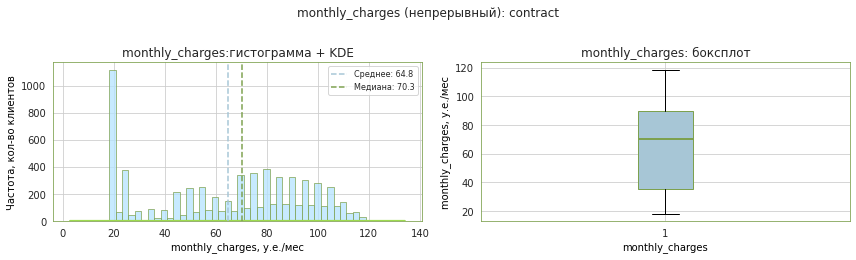

СТАТИСТИКА ПО 'monthly_charges':
----------------------------------------------------------------------------------------------------------------------------
   Кол-во записей:          7043
   Среднее:                 64.76
   Стандартное отклонение:  30.09
   Медиана:                 70.35
   Минимум:                 18.25
   Максимум:                118.75
   25-й перцентиль:         35.50
   75-й перцентиль:         89.85

   Проверка на нормальность (α=0.05):
      Д'Агостино:   p = 0.0000  (не нормальное)
      ВЫВОД: распределение НЕ СООТВЕТСТВУЕТ нормальному
----------------------------------------------------------------------------------------------------------------------------



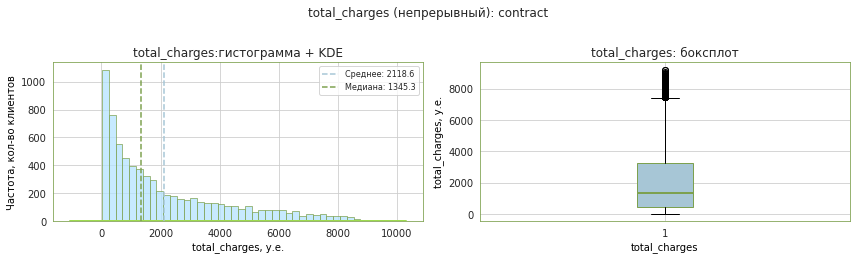

СТАТИСТИКА ПО 'total_charges':
----------------------------------------------------------------------------------------------------------------------------
   Кол-во записей:          7032
   Среднее:                 2118.62
   Стандартное отклонение:  2112.74
   Медиана:                 1345.28
   Минимум:                 19.05
   Максимум:                9221.38
   25-й перцентиль:         439.75
   75-й перцентиль:         3239.32

   Проверка на нормальность (α=0.05):
      Д'Агостино:   p = 0.0000  (не нормальное)
      ВЫВОД: распределение НЕ СООТВЕТСТВУЕТ нормальному
----------------------------------------------------------------------------------------------------------------------------



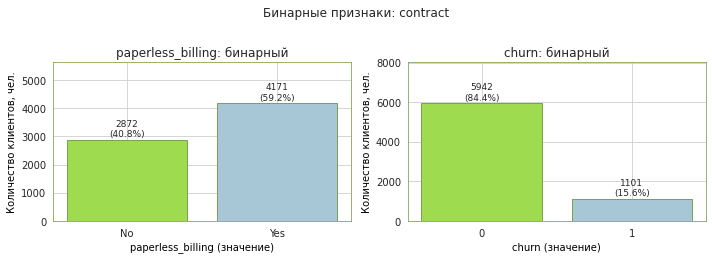

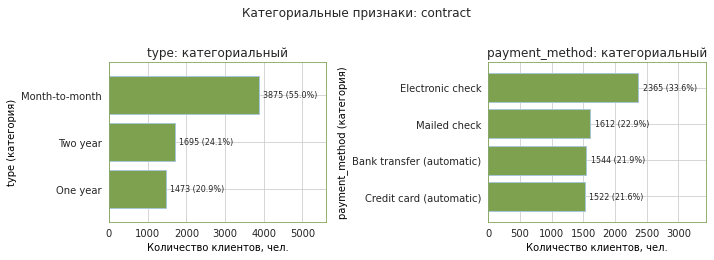

In [9]:
contract = quick_table_insight('contract', engine)

In [10]:
#Проверка - begin_date больше или равен end_date
mask_dates = contract['begin_date'] >= contract['end_date']

if mask_dates.sum() == 0:
    print("Нарушений нет: все begin_date < end_date")
else:
    print(f"Нарушений: {mask_dates.sum()}")
    print("\nПримеры нарушений:")
    print(df[mask_dates][['customer_id', 'begin_date', 'end_date']].head(10).to_string(index=False))
    
#Проверка - monthly_charges меньше, чем total_charges
mask_charges = contract['monthly_charges'] > contract['total_charges']

if mask_charges.sum() == 0:
    print("Нарушений нет: все monthly_charges <= total_charges")
else:
    print(f"Нарушений: {mask_charges.sum()}")
    print("\nПримеры нарушений:")
    print(df[mask_charges][['customer_id', 'monthly_charges', 'total_charges', 'tenure_months']].head(10).to_string(index=False))

Нарушений нет: все begin_date < end_date
Нарушений нет: все monthly_charges <= total_charges


<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">К О М М Е Н Т А Р И Й

---

<span style="color:#A7C6D6">

<span style="color:#7DA14F"> СТРУКТУРА ТАБЛИЦЫ:

- <span style="color:black"> **7 043 строки × 9 столбцов**  -  по одному договору на каждого клиента. 4 категориальных (из них 2 бинарных), 2 числовых, 2 даты и 1 id.
- <span style="color:black"> **`customer_id` уникален**  -  7043 из 7043, дубликатов нет. Значит, каждый клиент представлен один раз, объединение с другими таблицами пройдёт один-к-одному.

<span style="color:#7DA14F"> ПРОПУСКИ:

- <span style="color:black"> **1. `end_date`: 5942 пропуска (84.4%).** `NaT` в `end_date` - это значит, что клиент **активен**, а не потеря данных. Так закодирован статус: `"No"` в исходной таблице - `NaT` после `to_datetime`. Заполнять **не нужно**  -  пропуск несёт информацию.

- <span style="color:black"> **2. `total_charges`: 11 пропусков (0.2%)** - проверим и заполним по необходимости.

<span style="color:#7DA14F">  ЦЕЛЕВАЯ ПЕРЕМЕННАЯ:

- <span style="color:black"> **Ушли: 1101 (15.6%) | Остались: 5942 (84.4%).** Дисбаланс классов (поработаем над ним в самих моделях).

<span style="color:#7DA14F">  ЧИСЛОВЫЕ ПРИЗНАКИ:
    
---

**`monthly_charges`:** 
   
с т а т и с т и к а     
    
- <span style="color:black">  Пик на 19 у.е.
- <span style="color:black">  Кол-во записей: 7043 - все клиенты, пропусков нет.
- <span style="color:black"> Среднее: 64.76 у.е./мес.
- <span style="color:black"> Медиана: 70.35 у.е./мес  - выше среднего на 5.6 у.е.
- <span style="color:black">  Стандартное отклонение: 30.09  -  большой разброс, тарифы сильно различаются.
- <span style="color:black"> Диапазон: от 18.25 до 118.75 у.е./мес -  разница в 6.5 раз.
- <span style="color:black"> Квартили: 25% клиентов платят до 35.5, 75%  -  до 89.85. Основная масса - в диапазоне 35 - 90 у.е./мес.
    
р а с п р е д е л е н и е 
    
- <span style="color:black"> Медиана выше среднего - распределение смещено влево. Это значит, что основная масса клиентов на дорогих тарифах, но есть небольшая группа с очень дешёвыми (18–35 у.е.), которая «тянет» среднее вниз.
- <span style="color:black"> Проверка на нормальность: p-value = 0.0000 - **распределение НЕ нормальное**.
- <span style="color:black"> Это ожидаемо: тарифы не могут быть нормально распределены - они бимодальные. Есть базовые тарифы (~20 у.е.) и премиум-тарифы (~70–100 у.е.), с провалом между ними. 
    

о б у ч е н и е
    
- <span style="color:black"> Для деревьев и бустингов (CatBoost, LightGBM) обработка не нужна - они работают с рангами, а не с распределением.
- <span style="color:black"> Признак информативен: мы уже видели, что у ушедших monthly_charges выше на 20.4%.
    
---
    
**`total_charges`:** 

**с т а т и с т и к а**

- <span style="color:black"> Кол-во записей: 7032 - 11 пропусков, которые уже заполнены значением `monthly_charges`.
- <span style="color:black"> Среднее: 2118.62 у.е.
- <span style="color:black"> Медиана: 1345.28 у.е. - **ниже среднего** на 773 у.е.
- <span style="color:black"> Стандартное отклонение: 2112.74 - очень большой разброс, почти равен среднему.
- <span style="color:black"> Диапазон: от 19.05 до 9221.38 у.е. - разница в **484 раза**.
- <span style="color:black"> Квартили: 25% клиентов накопили до 439.75, 75% - до 3239.32. Основная масса - в диапазоне 440 - 3240 у.е.

**р а с п р е д е л е н и е**

- <span style="color:black"> **Медиана ниже среднего** - распределение сильно **смещено вправо**. Основная масса клиентов с небольшими накоплениями (440–3240 у.е.), но есть небольшая группа «долгожителей» с огромными суммами (до 9221 у.е.), которая «тянет» среднее вверх.
- <span style="color:black"> Проверка на нормальность: p-value = 0.0000 - **распределение НЕ нормальное.**
- <span style="color:black"> Это ожидаемо: `total_charges` = `monthly_charges × tenure`. Чем дольше клиент с оператором, тем больше накоплений. Это **произведение двух признаков** - оно не может быть нормально распределено, только с длинным правым хвостом.

**о б у ч е н и е**

- <span style="color:black"> Для деревьев и бустингов (`CatBoost`, `LightGBM`) обработка **не нужна** - они работают с рангами.
- <span style="color:black"> **Признак информативен:** у ушедших `total_charges` выше на **14.7%** (2371 vs 2068).
    
---
    
<span style="color:#7DA14F">  КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ:

**`type`:**

- <span style="color:black"> Уникальных категорий: **3**
- <span style="color:black"> Самая частая категория: **Month-to-month**
- <span style="color:black"> Доля самой частой категории: **55.0%** (3875 из 7043)
    
**`paperless_billing`:**

- <span style="color:black"> Уникальных категорий: **2**
- <span style="color:black"> Самая частая категория: **Yes**
- <span style="color:black"> Доля самой частой категории: **59.2%** (4171 из 7043) 
    
**`payment_method`:**

- <span style="color:black"> Уникальных категорий: **4**
- <span style="color:black"> Самая частая категория: **Electronic check**
- <span style="color:black"> Доля самой частой категории: **33.6%** (2365 из 7043)
    
<span style="color:black"> Автоплатежи (`Credit card`, `Bank transfer`) в сумме дают 43.5%.    
    
---
    
<span style="color:#7DA14F">  ЛОГИЧЕСКИЕ ПРОВЕРКИ:

- <span style="color:black"> **`begin_date больше или равен end_date`** - нарушений нет. Все даты начала раньше дат окончания, данные согласованы.
- <span style="color:black"> **`monthly_charges меньше, чем total_charges`** - нарушений нет. Месячный платёж ни у кого не превышает суммарные расходы.

---

- <span style="color:black"> Таблица готова к дальнейшей обработке: ID уникален, типы приведены, аномалий не обнаружено. Осталось разобраться с 11 пропусками в `total_charges` - изучить их и заполнить. А вот пропуски в `end_date` оставляем как есть - они несут смысл.

In [11]:
# Строки с пропуском в total_charges
missing_tc = contract[contract['total_charges'].isna()]

print("СТРОКИ С ПРОПУСКОМ В total_charges:", len(missing_tc))
print("-" * 125)
print(missing_tc.to_string())
print("-" * 125)

# Сводная статистика по строкам с пропуском
if len(missing_tc) > 0:
    print("СВОДКА ПО ПРОПУЩЕННЫМ СТРОКАМ:")
    print("-" * 125)
    print(f"Всего строк с пропуском:   {len(missing_tc)}")
    print(f"Ушли (churn=1):            {missing_tc['churn'].sum()}")
    print(f"Остались (churn=0):        {(missing_tc['churn'] == 0).sum()}")
    print(f"\nBeginDate — от {missing_tc['begin_date'].min().date()} "
          f"до {missing_tc['begin_date'].max().date()}")
    print(f"EndDate  — от {missing_tc['end_date'].min()} "
          f"до {missing_tc['end_date'].max()}")
    print(f"\nСредний monthly_charges:   {missing_tc['monthly_charges'].mean():.2f}")
    print(f"Медиана monthly_charges:   {missing_tc['monthly_charges'].median():.2f}")
    print(f"\nТипы контракта:")
    print(missing_tc['type'].value_counts().to_string())
    print(f"\nСпособы оплаты:")
    print(missing_tc['payment_method'].value_counts().to_string())
else:
    print("Строк с пропуском в total_charges нет")

СТРОКИ С ПРОПУСКОМ В total_charges: 11
-----------------------------------------------------------------------------------------------------------------------------
     customer_id begin_date end_date      type paperless_billing             payment_method  monthly_charges  total_charges  churn
488   4472-LVYGI 2020-02-01      NaT  Two year               Yes  Bank transfer (automatic)            52.55            NaN      0
753   3115-CZMZD 2020-02-01      NaT  Two year                No               Mailed check            20.25            NaN      0
936   5709-LVOEQ 2020-02-01      NaT  Two year                No               Mailed check            80.85            NaN      0
1082  4367-NUYAO 2020-02-01      NaT  Two year                No               Mailed check            25.75            NaN      0
1340  1371-DWPAZ 2020-02-01      NaT  Two year                No    Credit card (automatic)            56.05            NaN      0
3331  7644-OMVMY 2020-02-01      NaT  Two year   

<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">К О М М Е Н Т А Р И Й

---

<span style="color:#A7C6D6">

- <span style="color:black"> **Все 11 клиентов начали договор 2020-02-01 - в дату среза.** Стаж = 0 дней, первый платёж не прошёл - `total_charges` физически не накоплен. Пропуск - не потеря данных, а закономерность.
- <span style="color:black"> **Все 11 - с `churn = 0`.** Только что пришедшие клиенты не могли уйти (`end_date = NaT`). Пропуски не связаны с оттоком — заполнение не создаст ложного сигнала в целевой переменной.
- <span style="color:black"> **Все 11 - на долгосрочных контрактах (10 × Two year, 1 × One year).** Ни одного `Month-to-month`. Логично: Скорее всего на годовых/двухлетних тарифах первый платёж часто проходит позже, а на месячных — сразу при подключении. 
- <span style="color:black"> **Способы оплаты подтверждают задержку.** 8 из 11 - `Mailed check` (счёт по почте, оплата через дни). Остальные 3 - автоспособы, но и они подключились в день среза.
- <span style="color:black"> **`monthly_charges` варьируется от 19.70 до 80.85** (медиана 25.75, среднее 41.42). Пропуски не зависят от размера тарифа - заполнение `monthly_charges` не создаст смещения.
    
---
    
- <span style="color:black"> Пропуски структурны - привязаны к когорте `2020-02-01` (11 из 7043, 0.2%). 
- <span style="color:black"> Заполнение `total_charges = monthly_charges` логично: за первый неполный месяц накопленные расходы равны месячному тарифу.

In [12]:
# Заполняем пропуски и проверяем
contract['total_charges'] = contract['total_charges'].fillna(contract['monthly_charges'])
print(f"Пропусков в total_charges после заполнения: {contract['total_charges'].isna().sum()}")

#Проверяем заполнение этих строк
check = contract.loc[missing_tc.index, ['customer_id', 'begin_date', 'monthly_charges', 'total_charges']]

print("ПРОВЕРКА ЗАПОЛНЕНИЯ:")
print("=" * 100)
print(check.to_string(index=False))
print("=" * 100)

# Убеждаемся, что total_charges == monthly_charges
is_equal = (check['total_charges'] == check['monthly_charges']).all()
print(f"\n Все total_charges == monthly_charges: "
      f"{'Да' if is_equal else 'Нет'}")

# Проверка: пропусков больше нет
print(f"   Пропусков в total_charges: {contract['total_charges'].isna().sum()}")
print(f"   Отрицательных значений:    {(contract['total_charges'] < 0).sum()}")
print(f"   Нулевых значений:          {(contract['total_charges'] == 0).sum()}")

Пропусков в total_charges после заполнения: 0
ПРОВЕРКА ЗАПОЛНЕНИЯ:
customer_id begin_date  monthly_charges  total_charges
 4472-LVYGI 2020-02-01            52.55          52.55
 3115-CZMZD 2020-02-01            20.25          20.25
 5709-LVOEQ 2020-02-01            80.85          80.85
 4367-NUYAO 2020-02-01            25.75          25.75
 1371-DWPAZ 2020-02-01            56.05          56.05
 7644-OMVMY 2020-02-01            19.85          19.85
 3213-VVOLG 2020-02-01            25.35          25.35
 2520-SGTTA 2020-02-01            20.00          20.00
 2923-ARZLG 2020-02-01            19.70          19.70
 4075-WKNIU 2020-02-01            73.35          73.35
 2775-SEFEE 2020-02-01            61.90          61.90

 Все total_charges == monthly_charges: Да
   Пропусков в total_charges: 0
   Отрицательных значений:    0
   Нулевых значений:          0


<div style="border-left: 3px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
#### Таблица `personal`

АНАЛИЗ: PERSONAL

Всего строк: 7,043 | Столбцов: 5

СТОЛБЦЫ (5):
['customer_id', 'gender', 'senior_citizen', 'partner', 'dependents']
-----------------------------------------------------------------------------------------------------------------------------

ПРОВЕРКА ID НА УНИКАЛЬНОСТЬ:
-----------------------------------------------------------------------------------------------------------------------------
   customer_id: 7043 уникальных из 7043 строк
   Дубликатов нет
----------------------------------------------------------------------------------------------------------------------------

ТИПЫ ДАННЫХ:
----------------------------------------------------------------------------------------------------------------------------
   customer_id               → object
   gender                    → object
   senior_citizen            → int64
   partner                   → object
   dependents                → object

Пропусков нет

ПЕНСИОНЕРЫ: 1142 (16.2%)
--------------------------

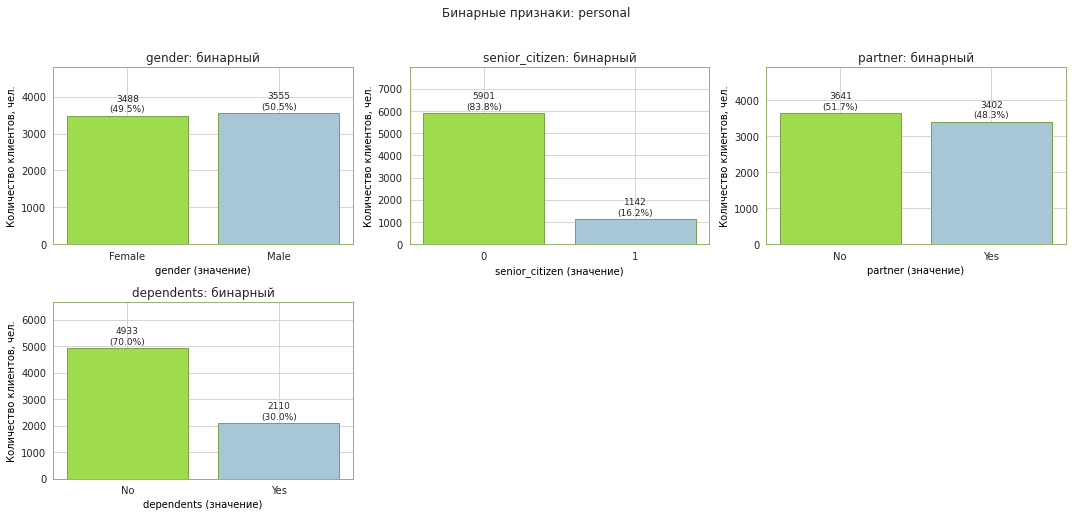

In [13]:
personal = quick_table_insight('personal', engine)

<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">К О М М Е Н Т А Р И Й

---

<span style="color:#A7C6D6">

- <span style="color:black"> **7 043 × 5.** По одной записи на клиента: `customer_id`, `gender`, `senior_citizen`, `partner`, `dependents`.
- <span style="color:black"> **ID уникален** - 7043 из 7043. Совпадает с `contract`, merge пройдёт один-к-одному.
- <span style="color:black"> **Пропусков нет** - таблица полностью заполнена.
    
---
    
**`gender`:**

- <span style="color:black"> Уникальных категорий: **2**
- <span style="color:black"> Самая частая категория: **Male**
- <span style="color:black"> Доля самой частой категории: **50.5%** (3555 из 7043)

<span style="color:black"> Распределение **почти равномерное** - мужчин и женщин почти поровну (50.5% vs 49.5%). Признак сбалансирован, дополнительная обработка не нужна.

**`senior_citizen`:**

- <span style="color:black"> Уникальных категорий: **2**
- <span style="color:black"> Самая частая категория: **0** (не пенсионер)
- <span style="color:black"> Доля самой частой категории: **83.8%** (5901 из 7043)

<span style="color:black"> Сильный **дисбаланс** - пенсионеров всего 16.2% (1142 чел.).

**`partner`:**

- <span style="color:black"> Уникальных категорий: **2**
- <span style="color:black"> Самая частая категория: **No** (без партнёра)
- <span style="color:black"> Доля самой частой категории: **51.7%** (3641 из 7043)

<span style="color:black"> Распределение **почти равномерное** - 51.7% без партнёра, 48.3% с партнёром. Признак сбалансирован.

**`dependents`:**

- <span style="color:black"> Уникальных категорий: **2**
- <span style="color:black"> Самая частая категория: **No** (без детей)
- <span style="color:black"> Доля самой частой категории: **70.0%** (4933 из 7043)

<span style="color:black"> Умеренный **дисбаланс** - клиентов с детьми 30.0% (2110 чел.). Оба класса представлены достаточно для обучения.

---
    

<div style="border-left: 3px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
#### Таблица `internet`

АНАЛИЗ: INTERNET

Всего строк: 5,517 | Столбцов: 8

СТОЛБЦЫ (8):
['customer_id', 'internet_service', 'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies']
-----------------------------------------------------------------------------------------------------------------------------

ПРОВЕРКА ID НА УНИКАЛЬНОСТЬ:
-----------------------------------------------------------------------------------------------------------------------------
   customer_id: 5517 уникальных из 5517 строк
   Дубликатов нет
----------------------------------------------------------------------------------------------------------------------------

ТИПЫ ДАННЫХ:
----------------------------------------------------------------------------------------------------------------------------
   customer_id               → object
   internet_service          → object
   online_security           → object
   online_backup             → object
   device_protection        

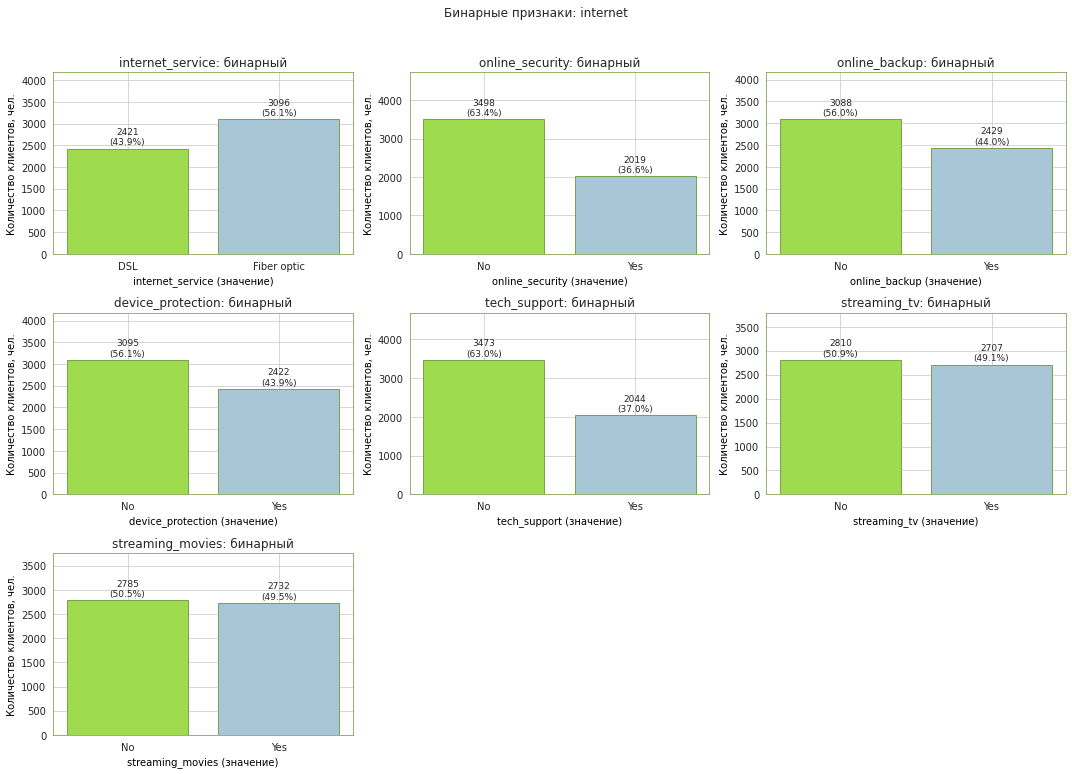

In [14]:
internet = quick_table_insight('internet', engine)

<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">К О М М Е Н Т А Р И Й

---

<span style="color:#A7C6D6">

- <span style="color:black"> **5 517 × 8.** Меньше, чем `contract` (7043) на **1526 клиентов** - это абоненты **без интернета**. Не потеря данных, а отсутствие услуги. При merge такие строки получат `NaN` в столбцах интернета поэтому заполним `"No internet service"` на этапе соединения таблиц.
- <span style="color:black"> **ID уникален** - 5517 из 5517, дубликатов нет. Все `customer_id` - подмножество из `contract`, merge пройдёт один-к-одному.
- <span style="color:black"> **Типы - все 8 столбцов `object`.** Это категориальные признаки.
- <span style="color:black"> **Пропусков нет** - таблица полностью заполнена для клиентов с подключённым интернетом.
- <span style="color:black"> **Тип подключения:** `Fiber optic` - 3096 (56.1%), `DSL` - 2421 (43.9%). Оптоволокно доминирует. В телеком-датасетах `Fiber optic` часто связан с **повышенным оттоком** - проверим связь с `churn` позже.
    
---
    
**`internet_service`:**

- <span style="color:black"> Уникальных категорий: **2**
- <span style="color:black"> Самая частая категория: **Fiber optic**
- <span style="color:black"> Доля самой частой категории: **56.1%** (3096 из 5517)

<span style="color:black"> Умеренный дисбаланс - `Fiber optic` доминирует.

<span style="color:black">**`online_security`:**

- <span style="color:black"> Уникальных категорий: **2**
- <span style="color:black"> Самая частая категория: **No**
- <span style="color:black"> Доля самой частой категории: **63.4%** (3498 из 5517)

<span style="color:black"> Большинство клиентов **не подключили** услугу. 

<span style="color:black">**`online_backup`:**

- <span style="color:black"> Уникальных категорий: **2**
- <span style="color:black"> Самая частая категория: **No**
- <span style="color:black"> Доля самой частой категории: **56.0%** (3088 из 5517)

<span style="color:black"> Распределение **почти равномерное** — 56% без услуги, 44% с услугой.

<span style="color:black">**`device_protection`:**

- <span style="color:black"> Уникальных категорий: **2**
- <span style="color:black"> Самая частая категория: **No**
- <span style="color:black"> Доля самой частой категории: **56.1%** (3095 из 5517)

<span style="color:black"> Распределение **почти равномерное**.

<span style="color:black">**`tech_support`:**

- <span style="color:black"> Уникальных категорий: **2**
- <span style="color:black"> Самая частая категория: **No**
- <span style="color:black"> Доля самой частой категории: **63.0%** (3473 из 5517)

<span style="color:black"> Большинство **без техподдержки**.
    
<span style="color:black">**`streaming_tv`:**

- <span style="color:black"> Уникальных категорий: **2**
- <span style="color:black"> Самая частая категория: **No**
- <span style="color:black"> Доля самой частой категории: **50.9%** (2810 из 5517)

<span style="color:black"> Распределение **почти равномерное** - 50.9% / 49.1%.

<span style="color:black">**`streaming_movies`:**

- <span style="color:black"> Уникальных категорий: **2**
- <span style="color:black"> Самая частая категория: **No**
- <span style="color:black"> Доля самой частой категории: **50.5%** (2785 из 5517)

<span style="color:black"> Распределение **почти равномерное** - 50.5% / 49.5%. 
    
---    
    
<span style="color:black"> `Таблица чистая и готова к merge.` **При объединении** важно **не удалять** 1526 клиентов без интернета - для них пропуски в столбцах услуг заполним отдельной категорией, чтобы модель могла отличать «услуга не подключена» от «данные потеряны».
        
    
---

<div style="border-left: 1px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
**СПОЙЛЕР:**
    
- <span style="color:black"> **Общий паттерн оттока:** во всех услугах `Yes` даёт **выше отток**, чем `No`. Разница от +3.9 до +10.8 п.п.  
    

<div style="border-left: 3px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
#### Таблица `phone`

АНАЛИЗ: PHONE

Всего строк: 6,361 | Столбцов: 2

СТОЛБЦЫ (2):
['customer_id', 'multiple_lines']
-----------------------------------------------------------------------------------------------------------------------------

ПРОВЕРКА ID НА УНИКАЛЬНОСТЬ:
-----------------------------------------------------------------------------------------------------------------------------
   customer_id: 6361 уникальных из 6361 строк
   Дубликатов нет
----------------------------------------------------------------------------------------------------------------------------

ТИПЫ ДАННЫХ:
----------------------------------------------------------------------------------------------------------------------------
   customer_id               → object
   multiple_lines            → object

Пропусков нет

МНОЖЕСТВЕННЫЕ ЛИНИИ:
   No: 3390 (53.3%)
   Yes: 2971 (46.7%)
----------------------------------------------------------------------------------------------------------------------------
   Столбцы 1–2:

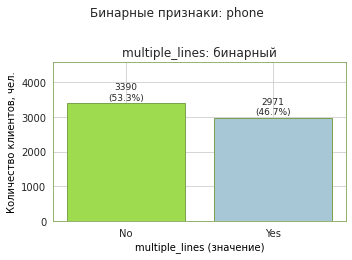

In [15]:
phone = quick_table_insight('phone', engine)

<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">К О М М Е Н Т А Р И Й

---

<span style="color:#A7C6D6">

- <span style="color:black"> **6 361 × 2.** На 682 клиента меньше `contract` - это абоненты **без телефонии**. При merge `NaN` = `"No phone service"`.
- <span style="color:black"> **ID уникален** (6361 из 6361) - подмножество `contract`, merge один-к-одному.
- <span style="color:black"> **Типы:** оба столбца `object`.
- <span style="color:black"> **Пропусков нет.**
- <span style="color:black"> **Баланс:** `No` - 3390 (53.3%), `Yes` - 2971 (46.7%).
       
---

**`multiple_lines`:**

- <span style="color:black"> Уникальных категорий: **2**
- <span style="color:black"> Самая частая категория: **No**
- <span style="color:black"> Доля самой частой категории: **53.3%** (3390 из 6361)

<span style="color:black"> Распределение **почти равномерное** — 53.3% без дополнительных линий, 46.7% с линиями. 
  
---
    
<span style="color:black"> Таблица чистая, готова к merge.  **При объединении** важно 682 клиента без телефона **не удаляем** - заполним `"No phone service"`, чтобы модель различала отсутствие услуги и отказ от линий.    
    
---
   
<div style="border-left: 2px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
        
    
<span style="color:#7DA14F">**СПОЙЛЕР**
    
- <span style="color:black"> При этом разница в оттоке **максимальная среди всех услуг**: у `Yes` - **22.8%**, у `No` - **9.4%**. Разница **+13.4 п.п.** - самая сильная связь с целевой переменной среди семи услуг. Клиенты с несколькими линиями уходят **в 2.4 раза чаще**.  
- <span style="color:black"> **Клиенты с несколькими линиями уходят в 2.4 раза чаще** - это семьи или малый бизнес с высокой мобильностью.


<div style="background-color:  #FDFFFA; border: 4px solid #7DA14F; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

#### <span style="color:#7DA14F"> в ы в о д

---

<span style="color:#A7C6D6">**ТАБЛИЦА `contract`**

- <span style="color:black"> 7043 × 9. ID уникален. Целевая: 15.6% ушедших: дисбаланс, учтём при обучении - поработаем над дисбалансом в самих моделях.
- <span style="color:black"> Пропуски: `end_date` (5942) - оставляем, `NaT` = клиент активен; `total_charges` (11) - заполнен `monthly_charges` (все 11 из когорты `2020-02-01`, длительность контракта 0 дней).
- <span style="color:black"> Логические проверки и аномалии - нарушений нет.

---

<span style="color:#A7C6D6">**ТАБЛИЦА `personal`**

- <span style="color:black"> 7043 × 5. ID уникален, пропусков нет. 4 бинарных
- <span style="color:black"> Пенсионеры - **1142 (16.2%)**
- <span style="color:black"> Мужчин и женщин почти поровну (50.5% vs 49.5%)  
- <span style="color:black"> 51.7% клиентов без партнёра и 48.3% с партнёром 
- <span style="color:black"> Клиентов с детьми 30.0%
---

<span style="color:#A7C6D6">**ТАБЛИЦА `internet`**

- <span style="color:black"> 5517 × 8. ID уникален, пропусков нет. Меньше `contract` на **1526 клиентов** - без интернета. При merge: `NaN` - `"No internet service"`.
- <span style="color:black"> Тип подключения: **Fiber optic 56.1% / DSL 43.9%**.
    
---

<span style="color:#A7C6D6">**ТАБЛИЦА `phone`**

- <span style="color:black"> 6361 × 2. ID уникален, пропусков нет. Меньше `contract` на **682 клиента** - без телефонии. При merge: `NaN` - `"No phone service"`.
- <span style="color:black"> `MultipleLines`: **No 53.3% / Yes 46.7%**.

<div style="border-left: 6px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
### <span style="color:#A7C6D6"> Объединение таблиц
  
<span style="color:#7DA14F">
    
---
    
ОСНОВНАЯ ТАБЛИЦА - **`contract`.** <span style="color:black">В ней 7043 клиента, у каждого уникальный `customer_id`. Остальные три таблицы - дополнения
    
- <span style="color:black">`contract`	7043 строк	`тип связи:` основная
- <span style="color:black">`personal`	7043 строк	`тип связи:`один-к-одному
- <span style="color:black">`internet`	5517 строк	`тип связи:`один-к-одному для клиентов с интернетом
- <span style="color:black">`phone`	    6361 строк  `тип связи:`один-к-одному для клиентов с телефонией    
    
ПОЭТОМУ <span style="color:black">**используем how='left' от `contract`:**

- <span style="color:black">все 7043 клиента сохранятся;
- <span style="color:black">к ним подтянутся данные из `personal`, `internet`, `phone`;
- <span style="color:black">для 1526 клиентов без интернета и 682 без телефона появятся NaN - это ожидаемо (услуга не <span style="color:black">подключена). Выделим их в отдельную категорию ("No internet service" - для тех, у кого подключена только телефония; "No phone service" - для тех, у кого подключен только интернет).

In [16]:
# Объединение 4 таблиц
df = (contract
      .merge(personal, on='customer_id', how='left')
      .merge(internet, on='customer_id', how='left')
      .merge(phone,    on='customer_id', how='left'))
# Заполнение пропусков
internet_cols = ['internet_service', 'online_security', 'online_backup','device_protection', 
                 'tech_support','streaming_tv', 'streaming_movies']
phone_cols = ['multiple_lines']

# Проверка корректности объединения данных
assert df['customer_id'].is_unique, "Дубликаты после merge!" #если False,то останавливает и выводит сообщение
assert len(df) == len(contract), "Изменилось число строк!" #если не равны,то останавливает и выводит сообщение

# Проверка. Сколько клиентов получили NaN от отсутствующих услуг
no_internet = df['internet_service'].isna().sum()
no_phone    = df['multiple_lines'].isna().sum()

assert no_internet == 1526
assert no_phone == 682

df[internet_cols] = df[internet_cols].fillna('No internet service') # Клиенты без интернета - это "No internet service"
df[phone_cols] = df[phone_cols].fillna('No phone service')          # Клиенты без телефонии-это "No phone service"

# Проверим
n_no_internet = (df['internet_service'] == 'No internet service').sum()
n_no_phone    = (df['multiple_lines'] == 'No phone service').sum()

print(f"Уникальные значения internet_service: {df['internet_service'].unique()}")
print(f" ► из них 'No internet service': {n_no_internet} (Было пропусков 1526)")

print(f"\nУникальные значения multiple_lines: {df['multiple_lines'].unique()}")
print(f" ► из них 'No phone service': {n_no_phone} (Было пропусков 682)")

Уникальные значения internet_service: ['DSL' 'Fiber optic' 'No internet service']
 ► из них 'No internet service': 1526 (Было пропусков 1526)

Уникальные значения multiple_lines: ['No phone service' 'No' 'Yes']
 ► из них 'No phone service': 682 (Было пропусков 682)


АНАЛИЗ: MERGED

Всего строк: 7,043 | Столбцов: 21

СТОЛБЦЫ (21):
['customer_id', 'begin_date', 'end_date', 'type', 'paperless_billing', 'payment_method', 'monthly_charges', 'total_charges', 'churn', 'gender', 'senior_citizen', 'partner', 'dependents', 'internet_service', 'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies', 'multiple_lines']
-----------------------------------------------------------------------------------------------------------------------------

ПРОВЕРКА ID НА УНИКАЛЬНОСТЬ:
-----------------------------------------------------------------------------------------------------------------------------
   customer_id: 7043 уникальных из 7043 строк
   Дубликатов нет
----------------------------------------------------------------------------------------------------------------------------

ТИПЫ ДАННЫХ:
--------------------------------------------------------------------------------------------------------------------

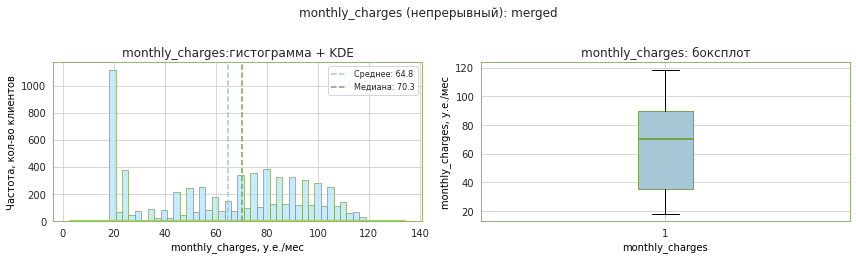

СТАТИСТИКА ПО 'monthly_charges':
----------------------------------------------------------------------------------------------------------------------------
   Кол-во записей:          7043
   Среднее:                 64.76
   Стандартное отклонение:  30.09
   Медиана:                 70.35
   Минимум:                 18.25
   Максимум:                118.75
   25-й перцентиль:         35.50
   75-й перцентиль:         89.85

   Проверка на нормальность (α=0.05):
      Д'Агостино:   p = 0.0000  (не нормальное)
      ВЫВОД: распределение НЕ СООТВЕТСТВУЕТ нормальному
----------------------------------------------------------------------------------------------------------------------------



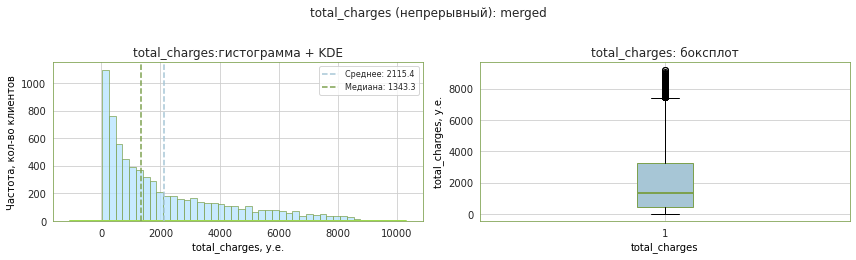

СТАТИСТИКА ПО 'total_charges':
----------------------------------------------------------------------------------------------------------------------------
   Кол-во записей:          7043
   Среднее:                 2115.38
   Стандартное отклонение:  2112.68
   Медиана:                 1343.35
   Минимум:                 19.05
   Максимум:                9221.38
   25-й перцентиль:         436.75
   75-й перцентиль:         3236.69

   Проверка на нормальность (α=0.05):
      Д'Агостино:   p = 0.0000  (не нормальное)
      ВЫВОД: распределение НЕ СООТВЕТСТВУЕТ нормальному
----------------------------------------------------------------------------------------------------------------------------



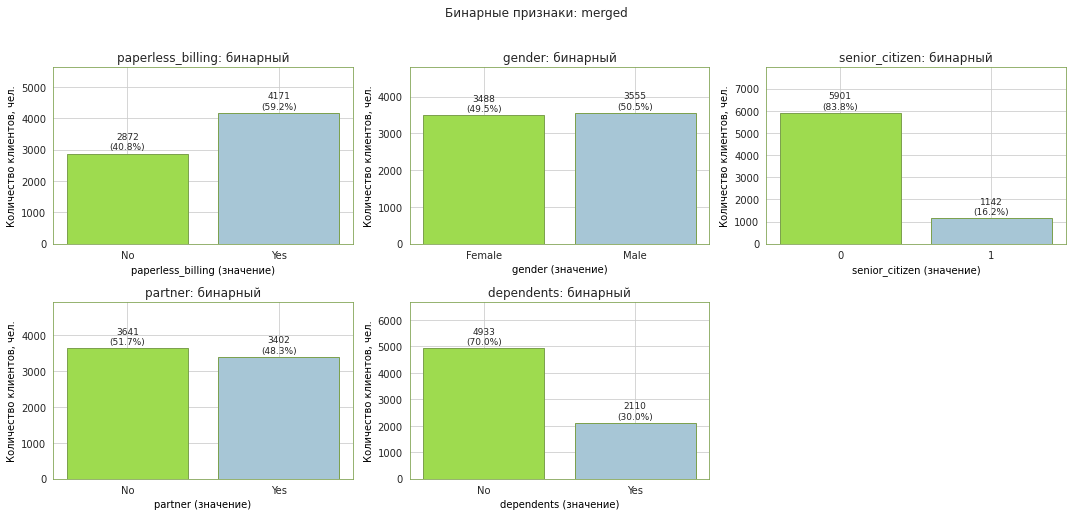

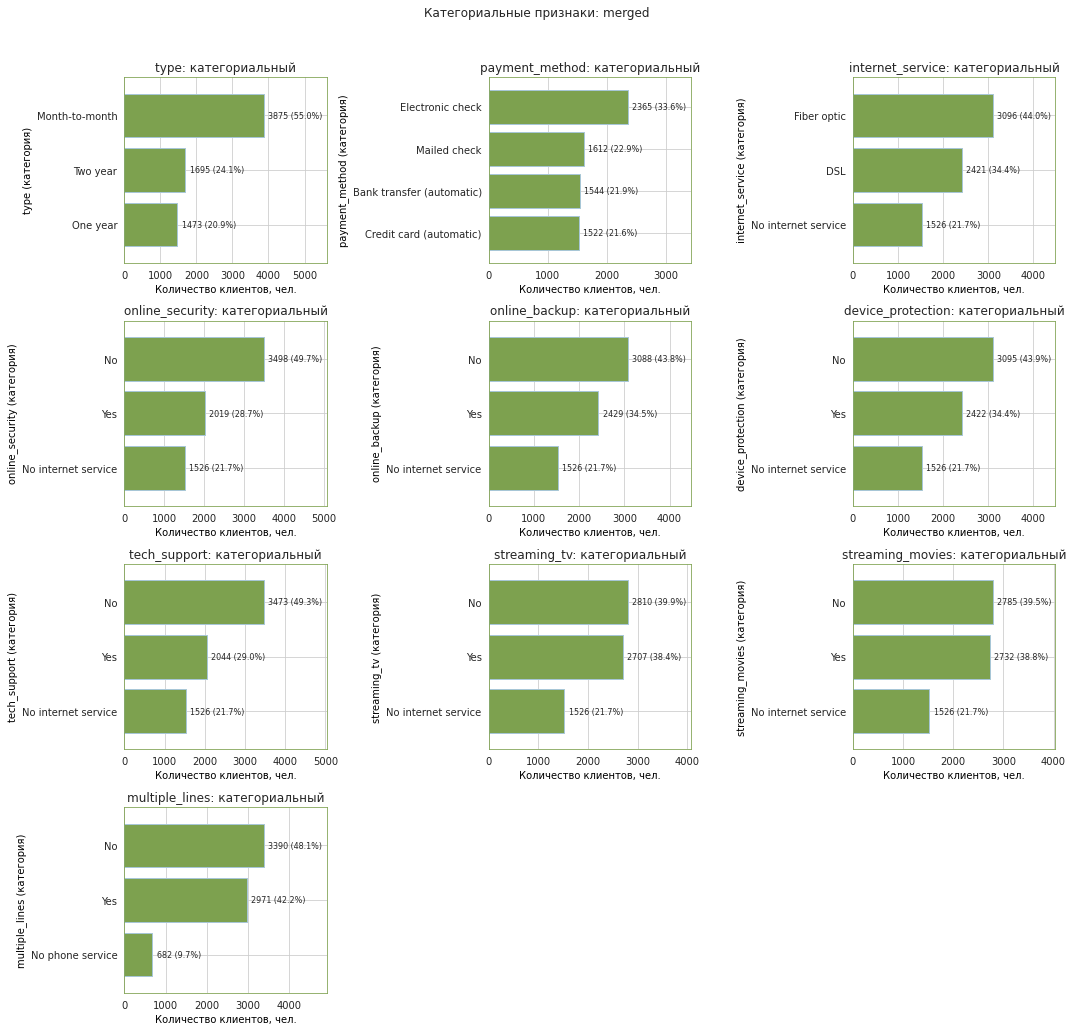

In [17]:
# Выводим объединённый датафрейм
df = quick_table_insight(df=df, table_name='merged')

<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">
<span style="color:#7DA14F">К О М М Е Н Т А Р И Й

---

<span style="color:#A7C6D6">

<span style="color:#7DA14F">1. <span style="color:black"> **Объединение таблиц** выполнено корректно.

- <span style="color:black"> `left join` от `contract` сохранил всех 7043 клиентов.
- <span style="color:black"> `customer_id` остался уникальным - ни дубликатов, ни потерь.
- <span style="color:black"> Размер `7043 × 21` соответствует ожиданиям.

<span style="color:#7DA14F">2. <span style="color:black"> **Пропуски** от объединения закрыты.

- <span style="color:black"> `1526` клиентов без интернета получили `"No internet service"`, `682` без телефонии - `"No phone service"`. Это категории, а не пропуски - модель сможет отличить «услуга не подключена» от реального отказа.
- <span style="color:black"> Единственный столбец с пропусками - `end_date` (5942). Это ожидаемо: `NaT` = клиент активен. Заполнять не нужно - пропуск несёт информацию о статусе.

<span style="color:#7DA14F">3. <span style="color:black"> **Целевая переменная** сохранена.

- <span style="color:black"> `1101` ушедших (15.6%). Значение совпадает с исходным `contract`.
- <span style="color:black"> Дисбаланс классов остаётся - учтём при обучении.

<span style="color:#7DA14F">4. <span style="color:black"> **Числовые признаки** существенно не изменились.

- <span style="color:black"> `monthly_charges` - Среднее и медиана те же **64.76 / 70.35**.
- <span style="color:black"> `total_charges` снизился **с 2118.62 до 2115.38** - эффект заполнения 11 пропусков значением `monthly_charges`. Это ожидаемо и не искажает данные.

<div style="border-left: 6px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
### <span style="color:#A7C6D6"> Генерация новых признаков
      
---
    
<span style="color:#7DA14F">    
    
- <span style="color:black">`tenure_months`: Длительность контракта абонента
- <span style="color:black">`avg_monthly`: Средний чек за месяц за всё время обслуживания
- <span style="color:black">`charges_dynamics`: Динамика тарифа - как менялся чек (рос, снижался, стабилен)

<div style="border-left: 2px solid #B5E4FF; padding-left: 15px; margin: 15px 0;">
    
#### Признак **`tenure_months`**

---
    
<span style="color:#7DA14F">
    
**Это длительность контракта абонента/длительность обслуживаения на момент среза** . 
    
- <span style="color:black">Так как `begin_date` - это календарная дата, её нельзя подавать в модель. 
- <span style="color:black">`tenure_months` - это числовое значение, его можно. Используем только для EDA.
- <span style="color:black">НО подаём его без других производных `begin_date` (год, месяц начала) - иначе будет утечка. 
    
---
    
`Считаем по-разному для двух случаев:`
    
- <span style="color:black">Клиент ушёл (`end_date` **есть**), значит `end_date - begin_date`.
- <span style="color:black">Клиент активен (`end_date` **нет**), значит дата среза `2020-02-01 - begin_date`.
    
---
    
Для модели создаем `tenure_days` - для точности.

In [18]:
# длительность обслуживания в месяцах для EDA
ref_date = pd.Timestamp('2020-02-01')

def months_between(start_series, end_series):
    """
    Точное количество месяцев между датами через pandas Period.
    Работает векторно - быстро.
    """
    return (end_series.dt.to_period('M')- start_series.dt.to_period('M')).apply(lambda x: x.n)


# Для ушедших: end_date - begin_date
# Для активных: ref_date - begin_date
end_for_tenure = df['end_date'].fillna(ref_date)
df['tenure_months'] = months_between(df['begin_date'], end_for_tenure)

#Создаем для точности модели
df['tenure_days'] = np.where(df['end_date'].notna(), 
                             (df['end_date'] - df['begin_date']).dt.days, 
                             (ref_date - df['begin_date']).dt.days).astype(int)

Тип:      int64
Минимум:  0
Максимум: 76
Пропуски: 0
Нули:     11

СРАВНЕНИЕ ПО CHURN:
   остались: 29.33 | ушли: 30.39 | разница: +1.06
АНАЛИЗ: DATAFRAME
АНАЛИЗ ПРИЗНАКА: TENURE_MONTHS (непрерывный)


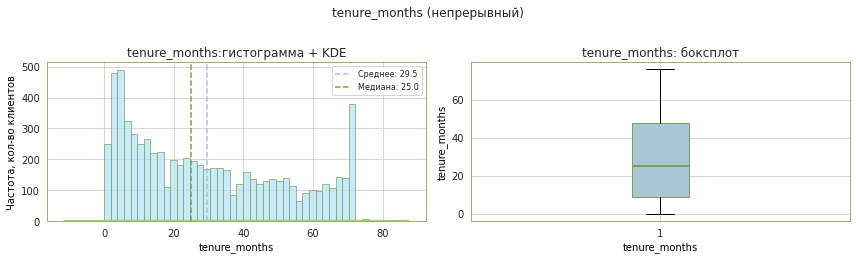

СТАТИСТИКА ПО 'tenure_months':
----------------------------------------------------------------------------------------------------------------------------
   Кол-во записей:          7043
   Среднее:                 29.50
   Стандартное отклонение:  22.45
   Медиана:                 25.00
   Минимум:                 0.00
   Максимум:                76.00
   25-й перцентиль:         9.00
   75-й перцентиль:         48.00

   Проверка на нормальность (α=0.05):
      Д'Агостино:   p = 0.0000  (не нормальное)
      ВЫВОД: распределение НЕ СООТВЕТСТВУЕТ нормальному
----------------------------------------------------------------------------------------------------------------------------


In [19]:
# Проверка
print(f"Тип:      {df['tenure_months'].dtype}")
print(f"Минимум:  {df['tenure_months'].min()}")
print(f"Максимум: {df['tenure_months'].max()}")
print(f"Пропуски: {df['tenure_months'].isna().sum()}")
print(f"Нули:     {(df['tenure_months'] == 0).sum()}")


# Сравнение по churn
print(f"\nСРАВНЕНИЕ ПО CHURN:")
stats = df.groupby('churn')['tenure_months'].mean().round(2)
diff = stats[1] - stats[0]
print(f"   остались: {stats[0]} | ушли: {stats[1]} | разница: {diff:+.2f}")

quick_table_insight(df=df, only_col='tenure_months')

In [20]:
# Проверочка
check_cols = ['customer_id', 'begin_date', 'end_date', 'tenure_months', 'churn']

print("=" * 75)
print("УШЕДШИЕ КЛИЕНТЫ (end_date заполнено) — 3 примера:")
print("=" * 75)
churned_sample = df[df['end_date'].notna()][check_cols].head(3)
print(churned_sample.to_string(index=False))
print()

print("=" * 75)
print("АКТИВНЫЕ КЛИЕНТЫ (end_date = NaT) — 3 примера:")
print("=" * 75)
active_sample = df[df['end_date'].isna()][check_cols].head(3)
print(active_sample.to_string(index=False))

УШЕДШИЕ КЛИЕНТЫ (end_date заполнено) — 3 примера:
customer_id begin_date   end_date  tenure_months  churn
 6388-TABGU 2014-12-01 2017-05-01             29      1
 3655-SNQYZ 2014-05-01 2016-03-01             22      1
 6865-JZNKO 2017-08-01 2018-09-01             13      1

АКТИВНЫЕ КЛИЕНТЫ (end_date = NaT) — 3 примера:
customer_id begin_date end_date  tenure_months  churn
 7590-VHVEG 2020-01-01      NaT              1      0
 5575-GNVDE 2017-04-01      NaT             34      0
 3668-QPYBK 2019-10-01      NaT              4      0


<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">К О М М Е Н Т А Р И Й

---

<span style="color:#A7C6D6">

- <span style="color:black"> **Среднее по каждой группе:** остались 29.33 | ушли 30.39 | разница **+1.06** - ушедшие в среднем были с оператором на 1 месяц дольше, чем оставшиеся. Не слишком значимо, но, возможно, даст эффект в сочетании с другими признаками.
- <span style="color:black"> **Кол-во записей:** 7043 - все клиенты, пропусков нет.
- <span style="color:black"> **Среднее:** 29.50 мес | **Медиана:** 25.00 мес - медиана ниже среднего на 4.5 мес.

<span style="color:black"> Медиана ниже среднего - распределение **смещено вправо**. Основная масса - с небольшой *длительностью контракта*, но есть «хвост» давних клиентов, который тянет среднее вверх.

- <span style="color:black"> **Стандартное отклонение:** 22.45 - большой разброс, *длительность контракта* сильно различается.
- <span style="color:black"> **Диапазон:** 0–76 мес — есть новички (0) и давние клиенты (76). Одиннадцать клиентов с *длительностью контракта* 0 мес.
- <span style="color:black"> **Квартили:** 25% - до 9 мес, 75% - до 48 мес.

<span style="color:black"> **Распределение НЕ соответствует нормальному** (p = 0.0000).

---

**ГИСТОГРАММА**

1. <span style="color:black">**Первый пик** - в районе `2–6 месяцев`.

- <span style="color:black">Резкий подъём от 0, потом плавное снижение.
- <span style="color:black">Это клиенты, которые пришли недавно (2019–2020).

2. <span style="color:black">**Второй пик** - на `73–74 месяцах`.

- <span style="color:black">Резкий скачок вверх после 72 месяцев.
- <span style="color:black">Это клиенты из самой ранней когорты (2014) в этом срезе.

АНАЛИЗ: DATAFRAME
АНАЛИЗ ПРИЗНАКА: TENURE_DAYS (непрерывный)


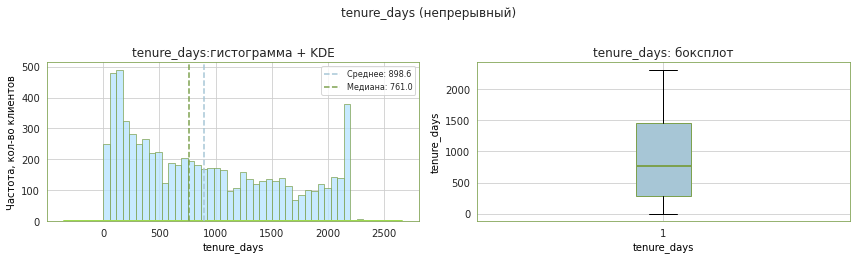

СТАТИСТИКА ПО 'tenure_days':
----------------------------------------------------------------------------------------------------------------------------
   Кол-во записей:          7043
   Среднее:                 898.56
   Стандартное отклонение:  683.13
   Медиана:                 761.00
   Минимум:                 0.00
   Максимум:                2314.00
   25-й перцентиль:         276.00
   75-й перцентиль:         1461.00

   Проверка на нормальность (α=0.05):
      Д'Агостино:   p = 0.0000  (не нормальное)
      ВЫВОД: распределение НЕ СООТВЕТСТВУЕТ нормальному
----------------------------------------------------------------------------------------------------------------------------


In [21]:
quick_table_insight(df=df, only_col='tenure_days')

<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">К О М М Е Н Т А Р И Й

---

<span style="color:#A7C6D6">

- <span style="color:black"> **Кол-во записей:** 7043 - все клиенты, пропусков нет.
- <span style="color:black"> **Среднее:** 898.56 дней | **Медиана:** 761.00 дней - медиана ниже среднего на 137.56 дней.

<span style="color:black"> Медиана ниже среднего - распределение **смещено вправо**. Основная масса - с небольшой *длительностью контракта*, но есть «хвост» давних клиентов, который тянет среднее вверх.

- <span style="color:black"> **Стандартное отклонение:** 683.13 - очень большой разброс, *длительность контракта* сильно различается.
- <span style="color:black"> **Диапазон:** 0-2314 дней - есть новички (0) и давние клиенты (2314 дней = ~6.3 года).
- <span style="color:black"> **Квартили:** 25% - до 276 дней (~ 9 мес), 75% - до 1461 дней (~4 года).

<span style="color:black"> **Распределение НЕ соответствует нормальному** (p = 0.0000).

---

**ГИСТОГРАММА**

1. <span style="color:black">**Первый пик** - в районе `60-180 дней` (~2-6 месяцев).

- <span style="color:black">Резкий подъём от 0, потом плавное снижение.
- <span style="color:black">Это клиенты, которые пришли недавно (2019-2020).

2. <span style="color:black">**Второй пик** - на `2190-2220 днях` (~73-74 месяца).

- <span style="color:black">Резкий скачок вверх после 2160 дней (72 месяца).
- <span style="color:black">Это клиенты из самой ранней когорты (2014) в этом срезе.

---

**СВЯЗЬ С `tenure_months`**

<span style="color:black"> `tenure_days` и `tenure_months` - **одно и то же**, но в разных единицах:
- <span style="color:black"> `tenure_days / 30.44 ~ tenure_months`.
- <span style="color:black"> 898.56 / 30.44 ~**29.50 мес** - совпадает со средним `tenure_months`.
- <span style="color:black"> 761 / 30.44 ≈ **25.00 мес** - совпадает с медианой `tenure_months`.

<span style="color:black"> **Для модели** используем `tenure_days`.

<div style="border-left: 2px solid #B5E4FF; padding-left: 15px; margin: 15px 0;">
    
#### Признак **`avg_monthly`**
     
---    
    
<span style="color:#7DA14F">
    
- <span style="color:black">`avg_monthly` - это средний чек клиента за месяц за всё время обслуживания = `total_charges / tenure_months`, который добавляет контекст истории.
- <span style="color:black">Если клиент менял тариф - значения `tenure_months` и `avg_monthly` расходятся, и разница несёт информацию. Это основа для признака `Динамика тарифа`. 

АНАЛИЗ: DATAFRAME
АНАЛИЗ ПРИЗНАКА: AVG_MONTHLY (непрерывный)


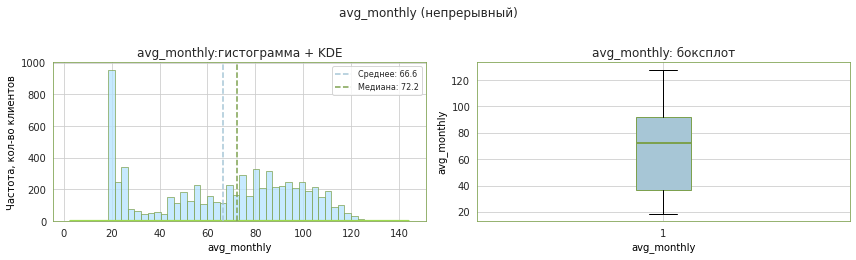

СТАТИСТИКА ПО 'avg_monthly':
----------------------------------------------------------------------------------------------------------------------------
   Кол-во записей:          7043
   Среднее:                 66.55
   Стандартное отклонение:  31.02
   Медиана:                 72.17
   Минимум:                 18.62
   Максимум:                128.04
   25-й перцентиль:         36.63
   75-й перцентиль:         92.21

   Проверка на нормальность (α=0.05):
      Д'Агостино:   p = 0.0000  (не нормальное)
      ВЫВОД: распределение НЕ СООТВЕТСТВУЕТ нормальному
----------------------------------------------------------------------------------------------------------------------------
Бесконечных значений: 0


In [22]:
# Для них средний чек = месячный тариф (другой истории ещё нет).
df['avg_monthly'] = np.where(
                             df['tenure_months'] > 0,
                             df['total_charges']/df['tenure_months'].replace(0, np.nan),
                             df['monthly_charges'],
                             )
quick_table_insight(df=df, only_col='avg_monthly')

# Проверочка не появилось ли inf
print(f"Бесконечных значений: {np.isinf(df['avg_monthly']).sum()}")

<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">К О М М Е Н Т А Р И Й

---

<span style="color:#A7C6D6">

**СТАТИСТИКА**

- <span style="color:black">**Всего записей** - 7043, пропусков нет.
- <span style="color:black">**Среднее** - 66.55 у.е./мес, **медиана** - 72.17. Медиана выше среднего на 5.6 у.е. То есть большинство клиентов платит много (около 72 у.е. в месяц). Но есть группа с очень дешёвыми тарифами (18–36 у.е.), которая тянет среднее вниз.
- <span style="color:black">**Std**: 31.02 - большой разброс, который может означать, что клиенты платят супер разные суммы в месяц.
- <span style="color:black">**Диапазон:** от 18.62 до 128.04 - разница в 6.9 раз.
- <span style="color:black">**Квартили:** 25% до 36.63, 75% до 92.21.

<div style="border-left: 2px solid #B5E4FF; padding-left: 15px; margin: 15px 0;">
    
#### Признак **`charges_dynamics`**
    
---
    
<span style="color:#7DA14F">
    
**Классификация клиентов по динамике тарифа.** Характерным значениям разности для классификации мы выбираем единицу (1 y.e.)

---

ЛОГИКА

- <span style="color:black">`monthly_charges` - текущий тариф клиента: сколько он платит **сейчас**.
- <span style="color:black">`avg_monthly` - средний чек за **всю историю** обслуживания.
- <span style="color:black">Если клиент **не менял тариф** - значения совпадают.
- <span style="color:black">Если **менял** - расходятся, и разница показывает, как именно.

<span style="color:black">**Две ситуации:**

- <span style="color:black">**`avg_monthly` > `monthly_charges`** - средний чек **выше** текущего. Значит, клиент **снизил** тариф: раньше платил больше, сейчас меньше.
- <span style="color:black">**`avg_monthly` < `monthly_charges`** - средний чек **ниже** текущего. Значит, клиент **повысил** тариф: сейчас платит больше, чем в среднем.

<span style="color:black">**Чем больше разница - тем «свежее» изменение тарифа:**

- <span style="color:black"> Разница **больше или равно 1 у.е.** - тариф менялся **недавно**, средний чек ещё не успел подтянуться.
- <span style="color:black"> Разница **меньше 1 у.е.** - изменение было **давно** или **незначительным**, средний чек почти сравнялся с текущим.
                                       
---

КАТЕГОРИИ В ПРИЗНАКЕ
 
- <span style="color:black">**old_decrease** - давно снизил тариф `[клиент платит меньше, чем в среднем, но разница небольшая - снижение было давно или незначительным]`
- <span style="color:black">**old_increase** - давно повысил тариф `[клиент тоже платит больше, чем в среднем, но разница небольшая - повышение было давно или незначительным]`  
- <span style="color:black">**recent_decrease** - недавно снизил тариф `[клиент недавно стал платить меньше, чем платил в среднем.]` 
- <span style="color:black">**recent_increase** - недавно повысил тариф `[клиент недавно стал платить больше, чем платил в среднем за всё время]`
- <span style="color:black">**stable** - тариф не менялся `[клиент платит ровно столько же, сколько платил в среднем за всё время]`

---

ВОЗМОЖНАЯ ПОЛЬЗА ДЛЯ МОДЕЛИ

- <span style="color:black">Признак даёт **исторический контекст**, которого нет в `monthly_charges`.
- <span style="color:black">Модель видит не только «сколько клиент платит сейчас», но и **как менялся его тариф**: рос, снижался или оставался стабильным.
- <span style="color:black">Разница между признаками - **сигнал недовольства**: клиент, который недавно сменил тариф, может быть в зоне риска.
- <span style="color:black">Без `avg_monthly` эта информация была бы потеряна.


АНАЛИЗ: DATAFRAME
АНАЛИЗ ПРИЗНАКА: CHARGES_DYNAMICS (категориальный)


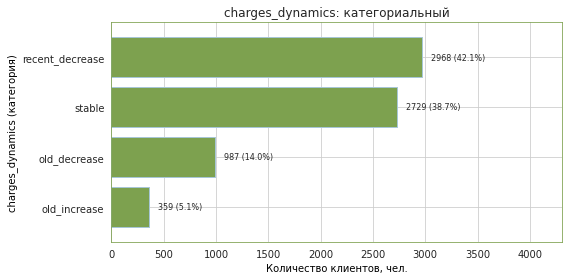

Тип:                object
Уникальных:         4
Пропусков:          0
Значений 'unknown': 0

РАСПРЕДЕЛЕНИЕ ПО ГРУППАМ:
---------------------------------------
   old_decrease         |   987 (14.0%)
   old_increase         |   359 (5.1%)
   recent_decrease      |  2968 (42.1%)
   stable               |  2729 (38.7%)

СУММА: 7043 (должно быть 7043 клиентов)


In [23]:
# Разница между текущим тарифом и средним чеком за всё время 
df['charges_diff']= df['monthly_charges'] - df['avg_monthly']

# Список условий для селект
conditions = [
              df['charges_diff'] >= 1,                              # условие 0 - recent_increase
              (df['charges_diff'] > 0) & (df['charges_diff'] < 1),  # условие 1 - old_increase
              df['charges_diff'] == 0,                              # условие 2 - stable
              (df['charges_diff'] > -1) & (df['charges_diff'] < 0), # условие 3 - old_decrease
              df['charges_diff'] <= -1                              # условие 4 - recent_decrease
             ]

# Список значений для селект
choices = [
           'recent_increase', # если условие 0 истинно
           'old_increase',    # если условие 1 истинно
           'stable',          # если условие 2 истинно
           'old_decrease',    # если условие 3 истинно
           'recent_decrease', # если условие 4 истинно
           ]

# Что присваеваем, если ни одно условие не сработало
default='unknown'

df['charges_dynamics'] = np.select(conditions, choices, default=default)
df['charges_dynamics'] = df['charges_dynamics'].astype('object') 

quick_table_insight(df=df, only_col='charges_dynamics')

# Проверочка
print(f"Тип:                {df['charges_dynamics'].dtype}")
print(f"Уникальных:         {df['charges_dynamics'].nunique()}")
print(f"Пропусков:          {df['charges_dynamics'].isna().sum()}")
print(f"Значений 'unknown': {(df['charges_dynamics'] == 'unknown').sum()}")
print()

print("РАСПРЕДЕЛЕНИЕ ПО ГРУППАМ:")
print("-" * 39)
counts = df['charges_dynamics'].value_counts().sort_index()
for group, cnt in counts.items():
    pct = cnt / len(df) * 100
    print(f"   {group:20} | {cnt:>5} ({pct:.1f}%)")
print()
print(f"СУММА: {counts.sum()} (должно быть {len(df)} клиентов)")

In [24]:
CHURN_BASE = df['churn'].mean() * 100

bins   = [0, 3, 6, 12, 24, 48, 100]
labels = ['0-3 мес', '3-6 мес', '6-12 мес', '1-2 года', '2-4 года', '4+ лет']

df['tenure_bin'] = pd.cut(df['tenure_months'], bins=bins, labels=labels)

cross_type_tenure = (df
                       .groupby(['type', 'tenure_bin'], observed=True)['churn']
                       .mean().unstack() * 100
                    ).round(1)

In [25]:
def check_new_feature(df, col, top_n_cat=5):
    """
    Комплексная проверка нового категориального признака.
    
    1. Распределение по группам (сколько клиентов).
    2. Отток внутри групп + сравнение с базовым.
    3. Распределение ушедших по группам.
    4. Кросс с type, tenure_bin, payment_method.
    5. Средний и медианный monthly_charges по группам.
    """

    print("=" * 100)
    print(f"ПРОВЕРКА ПРИЗНАКА: {col.upper()}")
    print("=" * 100)
    print(f"Базовый отток: {CHURN_BASE:.1f}%\n")

    # 1. Распределение и отток по группам
    stats = (df.groupby(col, observed=True)
               .agg(всего=('churn','count'), ушло=('churn', 'sum'),средний_чек=('monthly_charges', 'mean'))
               .assign(доля_группы=lambda d: (d['всего'] / len(df) * 100).round(1),
                       доля_оттока=lambda d: (d['ушло'] / d['всего'] * 100).round(1),
                       средний_чек=lambda d: d['средний_чек'].round(2))
               .sort_values('доля_оттока', ascending=False))

    print("1. РАСПРЕДЕЛЕНИЕ И ОТТОК ПО ГРУППАМ:")
    print("-" * 100)
    print(f"   {'Группа':<20} {'Всего':>6} {'Доля гр.':>9} {'Ушло':>6} "
          f"{'Отток':>7} {'Ср.чек':>8}")

    for group, row in stats.iterrows():
        marker = '!' if row['доля_оттока'] > CHURN_BASE else ' '
        print(f"   {marker} {str(group):<18} {int(row['всего']):>6} "
              f"{row['доля_группы']:>8.1f}% {int(row['ушло']):>6} "
              f"{row['доля_оттока']:>6.1f}% {row['средний_чек']:>8.2f}")
    print()

    # 2. Распределение ушедших по группам
    total_churned = stats['ушло'].sum()
    stats['доля_от_ушедших'] = (stats['ушло'] / total_churned * 100).round(1)
    stats_sorted = stats.sort_values('ушло', ascending=False)

    print("2. РАСПРЕДЕЛЕНИЕ УШЕДШИХ ПО ГРУППАМ:")
    print("-" * 100)
    for group, row in stats_sorted.iterrows():
        bar = '█' * int(row['доля_от_ушедших'] / 3)
        print(f"   {str(group):<20} | {int(row['ушло']):>4} "
              f"({row['доля_от_ушедших']:>4.1f}%) {bar}")
    print()

    # 3. Кросс с ключевыми категориальными признаками
    cross_cols = ['type', 'tenure_bin', 'payment_method']

    for cross_col in cross_cols:
        if cross_col not in df.columns:
            continue

        cross = (df.groupby([cross_col, col], observed=True)['churn']
                   .mean().unstack() * 100).round(1)
        print(f"3.{cross_cols.index(cross_col) + 1}. ОТТОК (%) ПО '{cross_col}' × '{col}':")
        print("-" * 100)
        print(cross.to_string())
        print()

In [26]:
# Проверочка
check_new_feature(df, col='charges_dynamics')

ПРОВЕРКА ПРИЗНАКА: CHARGES_DYNAMICS
Базовый отток: 15.6%

1. РАСПРЕДЕЛЕНИЕ И ОТТОК ПО ГРУППАМ:
----------------------------------------------------------------------------------------------------
   Группа                Всего  Доля гр.   Ушло   Отток   Ср.чек
   ! stable               2729     38.7%    451   16.5%    63.80
   ! recent_decrease      2968     42.1%    487   16.4%    69.76
   ! old_increase          359      5.1%     57   15.9%    66.37
     old_decrease          987     14.0%    106   10.7%    51.79

2. РАСПРЕДЕЛЕНИЕ УШЕДШИХ ПО ГРУППАМ:
----------------------------------------------------------------------------------------------------
   recent_decrease      |  487 (44.2%) ██████████████
   stable               |  451 (41.0%) █████████████
   old_decrease         |  106 ( 9.6%) ███
   old_increase         |   57 ( 5.2%) █

3.1. ОТТОК (%) ПО 'type' × 'charges_dynamics':
----------------------------------------------------------------------------------------------------


<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">К О М М Е Н Т А Р И Й

---

<span style="color:#A7C6D6">

<span style="color:#7DA14F">**Анализ признака `charges_dynamics`**

- <span style="color:black"> **Отток**: 10.7-16.5%, разница 5.8 п.п. Три группы (`stable`, `recent_decrease`, `old_increase`) - выше базового оттока, `old_decrease` - ниже.
- <span style="color:black"> **`stable` (16.5%) и `recent_decrease` (16.4%)**: самые высокие оттоки. Дорогие тарифы (63.80 и 69.76 у.е.).
- <span style="color:black"> **`old_decrease` (10.7%)**: самый низкий отток. Дешёвый чек (51.79 у.е.) - клиенты, которые давно снизили тариф.
- <span style="color:black"> **`recent_decrease`: самая большая группа (42.1%)** - **даёт 44.2% всех ушедших**. И **`stable`: вторая по размеру (38.7%)** - даёт 41.0% ушедших. *Бизнесу стоит обратить внимание на эти группы*.
- <span style="color:black"> **`old_increase` (5.1%)**: маленькая группа. Даже при оттоке 15.9% даёт всего 5.2% ушедших.

---

<span style="color:#7DA14F">**1. РАСПРЕДЕЛЕНИЕ И ОТТОК ПО ГРУППАМ**

- <span style="color:black"> `stable` (38.7%, 2729 клиентов): **тариф не менялся**, отток 16.5%, чек 63.80 у.е. Большая группа и высокая доля оттока.
- <span style="color:black"> `recent_decrease` (42.1%, 2968 клиентов): **недавно снизили тариф**, отток 16.4%, чек 69.76 у.е. Самая большая группа.
- <span style="color:black"> `old_increase` (5.1%, 359 клиентов): **давно повысили тариф**, отток 15.9%, чек 66.37 у.е.
- <span style="color:black"> `old_decrease` (14.0%, 987 клиентов): **давно снизили тариф**, отток 10.7%, чек 51.79 у.е. Самые лояльные, дешёвые клиенты.

ВАЖНО: <span style="color:black"> *Свежесть изменения не так важна, как направление*: клиенты со **стабильным или сниженным** тарифом дают основную массу ушедших.

---

<span style="color:#7DA14F">**2. РАСПРЕДЕЛЕНИЕ УШЕДШИХ ПО ГРУППАМ**

- <span style="color:black"> `recent_decrease`: 487 ушедших (44.2% от всех) `[Большая группа, высокий отток]`
- <span style="color:black"> `stable`: 451 ушедших (41.0% от всех) `[Большая группа, высокий отток]`
- <span style="color:black"> `old_decrease`: 106 ушедших (9.6% от всех) `[Маленькая группа, низкий отток]`
- <span style="color:black"> `old_increase`: 57 ушедших (5.2% от всех) `[Маленькая группа, низкий отток]`

ВАЖНО: <span style="color:black"> `recent_decrease` + `stable` дают **85.2% ушедших**. Что для бизнеса является приоритетом для удержания.

---

<span style="color:#7DA14F">**3.1. ОТТОК (%) ПО `type` × `charges_dynamics`**

<span style="color:black"> Проверяем: не артефакт ли наш новый признак. Если эффект сохраняется на всех типах контракта, значит признак универсальный.

- <span style="color:black"> `Month-to-month`: отток 8.0-12.1%. Низкий.
- <span style="color:black"> `One year`: 11.7-23.2%. `recent_decrease` (23.2%) и `stable` (22.7%) выбиваются.
- <span style="color:black"> `Two year`: 15.2-25.3%. `stable` (25.3%) - максимум.

ВАЖНО: <span style="color:black"> эффект сохраняется на всех типах контракта. Долгосрочный контракт + `stable`/`recent_decrease` - это потенциальная зона риска.

---

<span style="color:#7DA14F">**3.2. ОТТОК (%) ПО `tenure_bin` × `charges_dynamics`**

<span style="color:black"> Проверяем: не объясняется ли эффект длительностью контракта абонента.

- <span style="color:black"> Пик оттока: на 2-4 годах. Для всех групп.
- <span style="color:black"> 0-3 мес: 0.9-6.2% - новички почти не уходят.
- <span style="color:black"> 2-4 года: 23.9-30.4% - критическое окно.
- <span style="color:black"> 4+ лет: 4.1-12.0% - отток падает.

ВАЖНО: <span style="color:black"> признак не артефакт длительности контракта. Пик везде на 2-4 годах. Внутри пика `recent_decrease` (30.4%) и `stable` (29.6%) дают максимальный отток.

---

<span style="color:#7DA14F">**3.3. ОТТОК (%) ПО `payment_method` × `charges_dynamics`**

<span style="color:black"> Проверяем: не объясняется ли эффект способом оплаты.

- <span style="color:black"> `Mailed check`: низкий отток 4.2-12.9%. Чтобы уйти, нужно закрыть счёт, пойти в банк.
- <span style="color:black"> `Electronic check`: 12.6-18.4%. Средний.
- <span style="color:black"> Автоплатёж `Credit card` + `stable` = 23.3%, + `recent_decrease` = 22.1%.
- <span style="color:black"> Автоплатёж `Bank transfer` + `stable` = 23.2%, + `recent_decrease` = 20.6%.

ВАЖНО: <span style="color:black"> автоплатёж + `stable`/`recent_decrease` является наибольшим риском оттока.

---

<span style="color:#7DA14F">**ИТОГ**

**1. Две группы дают 85.2% ушедших:**

- <span style="color:black"> `recent_decrease`: 44.2% ушедших (2968 клиентов)
- <span style="color:black"> `stable`: 41.0% ушедших (2729 клиентов)
- <span style="color:black"> `old_decrease`: 9.6% ушедших (987 клиентов)
- <span style="color:black"> `old_increase`: 5.2% ушедших (359 клиентов)

**2. Критическое окно оттока - 2-4 года, для всех групп, особенно для:**

- <span style="color:black"> `recent_decrease` + 2-4 года: отток **30.4%**
- <span style="color:black"> `stable` + 2-4 года: отток **29.6%**

**3. Долгосрочный контракт + стабильный/сниженный тариф - это зона риска оттока:**

- <span style="color:black"> `Two year` + `stable`: отток **25.3%**
- <span style="color:black"> `One year` + `recent_decrease`: отток **23.2%**

**4. Автоплатёж + стабильный/сниженный тариф - это наибольший риск оттока:**

- <span style="color:black"> `Credit card` + `stable`: отток **23.3%**
- <span style="color:black"> `Bank transfer` + `stable`: отток **23.2%**

In [27]:
# Столбцы для удаления
cols_to_drop = ['begin_date', 'end_date', 'charges_diff']

# Удаляем
df = df.drop(columns=cols_to_drop)

# Проверка
print(f"\nРазмер df после удаления: {df.shape}")
print(f"\nОставшиеся столбцы ({len(df.columns)}):")
print(df.columns.tolist())


Размер df после удаления: (7043, 24)

Оставшиеся столбцы (24):
['customer_id', 'type', 'paperless_billing', 'payment_method', 'monthly_charges', 'total_charges', 'churn', 'gender', 'senior_citizen', 'partner', 'dependents', 'internet_service', 'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies', 'multiple_lines', 'tenure_months', 'tenure_days', 'avg_monthly', 'charges_dynamics', 'tenure_bin']


<div style="background-color: white; border: 3px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">**К О М М Е Н Т А Р И Й**

---

<span style="color:#A7C6D6">**РАСПРЕДЕЛЕНИЕ ПО ГРУППАМ**

- Группа `old_decrease`: 987 клиентов (14.0%) - Платят меньше, чем в среднем (тариф снижали давно или незначительно)
- Группа `old_increase`: 359 клиентов (5.1%) - Платят немного больше (повышение было давно или небольшим)
- Группа `recent_decrease`: 2968 клиентов (42.1%) - Платят существенно меньше (недавно снизили тариф)
- Группа `stable`: 2729 клиентов (38.7%) - Тариф не менялся с самого начала

Почти половина клиентов (42.1%) **недавно снизили тариф**, ещё треть (38.7%) - **тариф не меняли**, и лишь (19.1%) - **меняли тариф давно или незначительно**.

---

<span style="color:#A7C6D6">**УДАЛИЛИ ТРИ СТОЛБЦА**

- <span style="color:black"> **`begin_date` и `end_date`** - даты, в модель не идут. Информация уже в `tenure_months` и `churn`.
- <span style="color:black"> **`charges_diff`** - промежуточный признак, дублирует `charges_dynamics`.

---

- <span style="color:black"> **Размер `df`:** 7043 × 24.
- <span style="color:black"> **Пропуски:** 0 
    
 

<div style="background-color: #FDFFFA; border: 4px solid #7DA14F; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

#### <span style="color:#7DA14F"> в ы в о д

---
    
<span style="color:#A7C6D6">**ОБЪЕДИНЕНИЕ ТАБЛИЦ**

- <span style="color:black">`how='left'` от `contract`- все **7043 клиента** сохранены.
- <span style="color:black">`customer_id` уникален -дубликатов нет.
- <span style="color:black">Пропуски от merge закрыты: **1526** `"No internet service"`, **682** `"No phone service"`.
- <span style="color:black"> Единственный столбец с пропусками -`end_date` (5942). `NaT` = клиент активен.
- <span style="color:black"> Итог: **7043 × 21**, целевая **15.6% ушедших**.

---

<span style="color:#A7C6D6">**ГЕНЕРАЦИЯ ПРИЗНАКОВ**

- <span style="color:black"> **`tenure_months`** - длительность контракта в месяцах (0–76). **Для EDA**.
- <span style="color:black"> **`tenure_days`** - длительность контракта в днях (0–2314). Для модели (точнее).
- <span style="color:black"> **`avg_monthly`** - средний чек за всё время (18.62–128.04 у.е.).
- <span style="color:black"> **`charges_dynamics`** - динамика тарифа (`stable`, `recent_decrease`, `old_increase`, `old_decrease`).
- <span style="color:black"> **`tenure_bin`** - корзины длительности для EDA.

**Удалено 3 столбца:** `begin_date`, `end_date` (утечка), `charges_diff` (промежуточный).
**Итог:** после удаления лишних для модели **23 признака + churn**.

---

<span style="color:#A7C6D6">**КЛЮЧЕВЫЕ ИНСАЙТЫ**

-<span style="color:black"> **Отток выше у долгосрочных контрактов:** `Two year` 22.5%, `One year` 21.2%, `Month-to-month` 10.5%.
- <span style="color:black"> **`charges_dynamics`- сильный предиктор:** `stable` 16.5%, `recent_decrease` 16.4%, `old_decrease` 10.7%.
-<span style="color:black"> **Критическое окно- 2–4 года:** отток 23.9–30.4% для всех групп.
-<span style="color:black"> **Автоплатж + `stable`/`recent_decrease`** - максимальный риск: `Credit card` 23.3%, `Bank transfer` 23.2%.
- <span style="color:black"> **`recent_decrease` + `stable` дают 85.2% ушедших** - приоритет для удержания.
- <span style="color:black"> **Дисбаланс 1:5.4**- не критичный, борется весами классов.

---

<span style="color:#A7C6D6">**ДАННЫЕ ГОТОВЫ К ОБУЧЕНИЮ**

- <span style="color:black"> Пропуски: 0.
-<span style="color:black"> Утечки: удалены.
- <span style="color:black"> Признаки: 21 (14 категориальных + 3 числовых + 4 новых).
- <span style="color:black"> Целевая: `churn` (15.6% / 84.4%).

<div style="border-left: 6px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
### <span style="color:#A7C6D6">Исследовательский анализ объединённой таблицы
    
---    
    
<span style="color:#7DA14F">Исследуем какие у нас признаки и как они связанны с оттоком:


| Группа | Столбцы |
|---|---|
| Договор | `type`, `paperless_billing`, `payment_method`, `monthly_charges`, `total_charges` |
| Персональные | `gender`, `senior_citizen`, `partner`, `dependents` |
| Интернет | `internet_service`, `online_security`, `online_backup`, `device_protection`, `tech_support`, `streaming_tv`, `streaming_movies` |
| Телефония | `multiple_lines` |
| Новые | `tenure_months`, `avg_monthly`, `charges_dynamics` |
| Целевая | `churn` |    
    
<span style="color:#7DA14F">Не исследуем признак: `customer_id`
    
    
---
  
<span style="color:#A7C6D6">
    
**СТРУКТУРА**    
    
- 3.4.1. <span style="color:black">Баланс классов	`[Ещё раз фиксируем долю ушедших]`
- 3.4.2. <span style="color:black">Категориальные и целевая	`[Связь type, payment_method, internet_service и др. с оттоком]`
- 3.4.3. <span style="color:black">Числовые и целевая	`[monthly_charges, total_charges, tenure_months, avg_monthly]`
- 3.4.4. <span style="color:black">Тип и длительность контракта абонента
- 3.4.5. <span style="color:black">Когда уходят клиенты
- 3.4.6. <span style="color:black">Сводные выводы	`[Топ-признаки, гипотезы для модели]`
    
---

<div style="border-left: 2px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
#### Баланс классов
 
---    
  
<span style="color:#7DA14F">    
    
<span style="color:black">Ещё раз выводим и фиксируем дисбаланс (формально), чтобы задать контекст для всех дальнейших графиков (Если в какой-то категории отток выше 15.6% - это возможная зона риска).
    
ВЫВОДИМ:
    
- <span style="color:black">Количество ушедших и оставшихся
- <span style="color:black">Доля оттока - 15.6%.

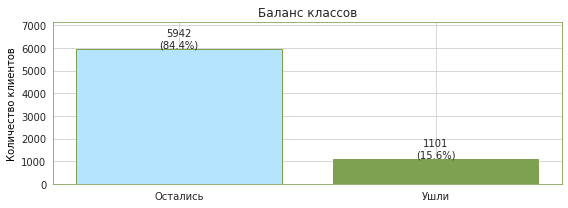

Базовый отток: 15.6%



In [28]:
# Визуализация
fig, ax = plt.subplots(figsize=(8, 3))
counts = df['churn'].value_counts().sort_index()
bars = ax.bar(['Остались', 'Ушли'], counts.values, color=['#B5E4FF', COLORS['green_dark']],edgecolor=COLORS['green_dark'])
for bar, v in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 50, f'{v}\n({v / len(df) * 100:.1f}%)',
            ha='center', fontsize=10)
ax.axhline(0, color=COLORS['black'], linewidth=0.5)
ax.set_title('Баланс классов')
ax.set_ylabel('Количество клиентов')
ax.set_ylim(0, counts.max() * 1.20)
plt.tight_layout()
plt.show()

# Одна базовая константа для всего раздела
CHURN_BASE = df['churn'].mean() * 100
print(f"Базовый отток: {CHURN_BASE:.1f}%\n")

<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">К О М М Е Н Т А Р И Й
    
---
    
<span style="color:#A7C6D6">
    
- <span style="color:black"> Базовый уровень оттока - 15.6%. Если в какой-то категории доля ушедших выше - это «зона риска».

<div style="border-left: 2px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
#### Категориальные и целевая
   
---    
    
Для каждого категориального признака **считаем долю ушедших по категориям** для того, чтобы выявить: клиенты с каким значением признака уходят чаще.
 

<span style="color:#7DA14F">ПРИЗНАКИ ПО ГРУППАМ (16 из 20)

| Группа | Признаки |
|---|---|
| Договор | `type`, `paperless_billing`, `payment_method` |
| Персональные | `gender`, `senior_citizen`, `partner`, `dependents` |
| Интернет | `internet_service`, `online_security`, `online_backup`, `device_protection`, `tech_support`, `streaming_tv`, `streaming_movies` |
| Телефония | `multiple_lines` |
| Новые | `charges_dynamics` |

<span style="color:#7DA14F">ВЫВОДИМ

- Долю оттока по каждой категории.
- Сравнениваем с базовым уровнем (15.6%).

<span style="color:#7DA14F">Чтобы определить, какие категории связаны с уходом сильнее всего.

Категориальных признаков: 16 | Базовый отток: 15.6%



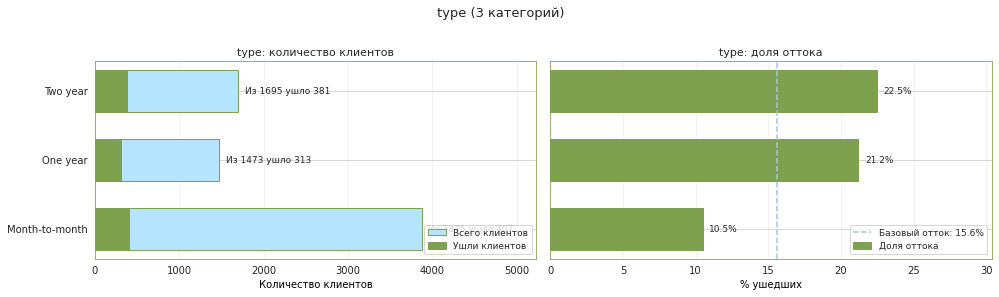


➤ TYPE
-------------------------------------------------------
   Категория                  Всего    Ушло   Доля %
   ! Two year                  1695     381    22.5%
   ! One year                  1473     313    21.2%
     Month-to-month            3875     407    10.5%
-----------------------------------------------------



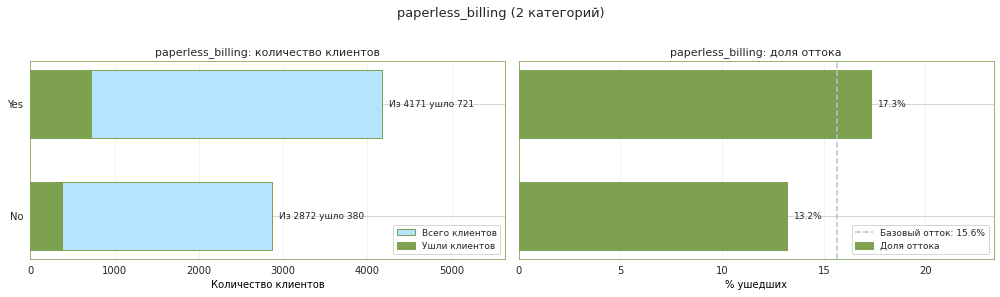


➤ PAPERLESS_BILLING
-------------------------------------------------------
   Категория                  Всего    Ушло   Доля %
   ! Yes                       4171     721    17.3%
     No                        2872     380    13.2%
-----------------------------------------------------



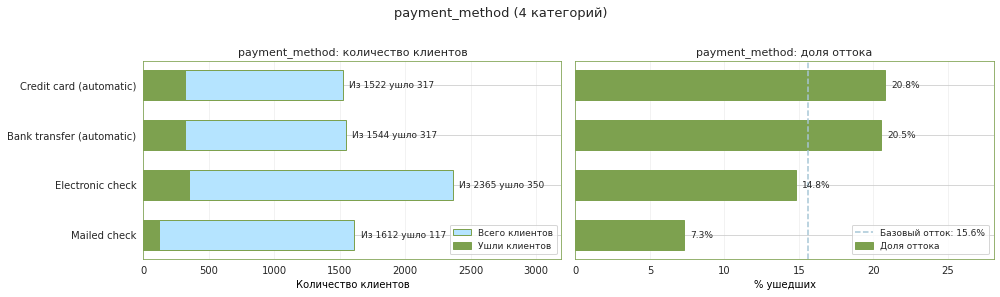


➤ PAYMENT_METHOD
-------------------------------------------------------
   Категория                  Всего    Ушло   Доля %
   ! Credit card (automatic)    1522     317    20.8%
   ! Bank transfer (automatic)    1544     317    20.5%
     Electronic check          2365     350    14.8%
     Mailed check              1612     117     7.3%
-----------------------------------------------------



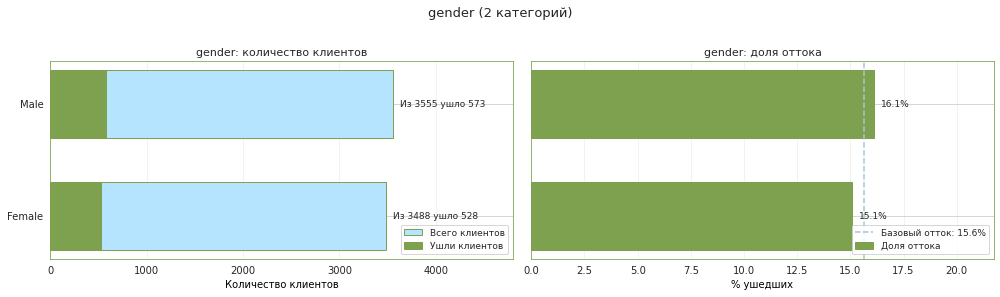


➤ GENDER
-------------------------------------------------------
   Категория                  Всего    Ушло   Доля %
   ! Male                      3555     573    16.1%
     Female                    3488     528    15.1%
-----------------------------------------------------



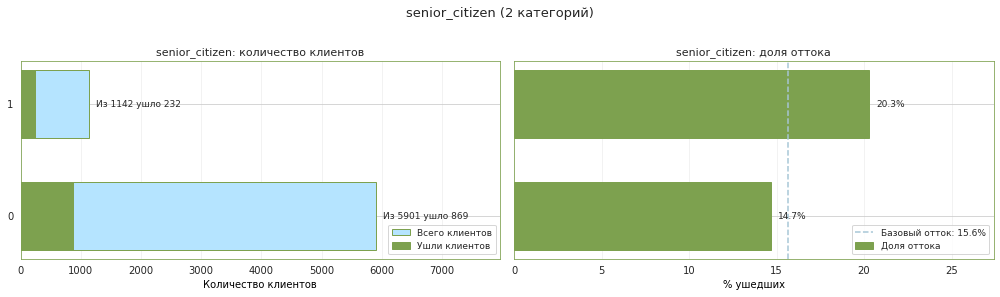


➤ SENIOR_CITIZEN
-------------------------------------------------------
   Категория                  Всего    Ушло   Доля %
   ! 1                         1142     232    20.3%
     0                         5901     869    14.7%
-----------------------------------------------------



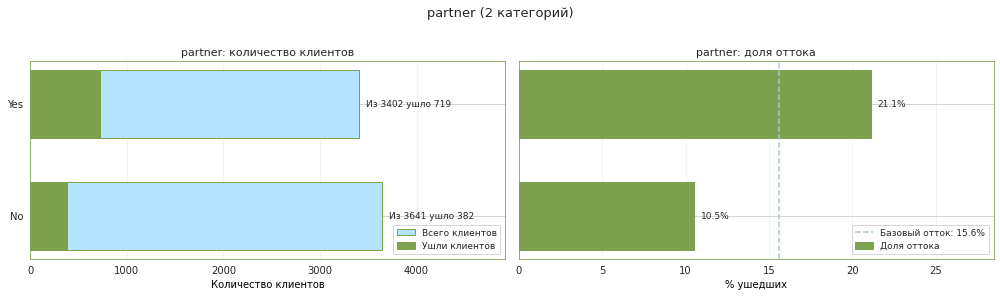


➤ PARTNER
-------------------------------------------------------
   Категория                  Всего    Ушло   Доля %
   ! Yes                       3402     719    21.1%
     No                        3641     382    10.5%
-----------------------------------------------------



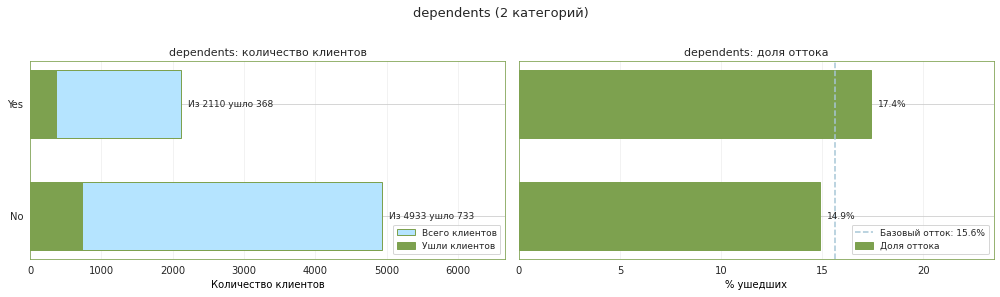


➤ DEPENDENTS
-------------------------------------------------------
   Категория                  Всего    Ушло   Доля %
   ! Yes                       2110     368    17.4%
     No                        4933     733    14.9%
-----------------------------------------------------



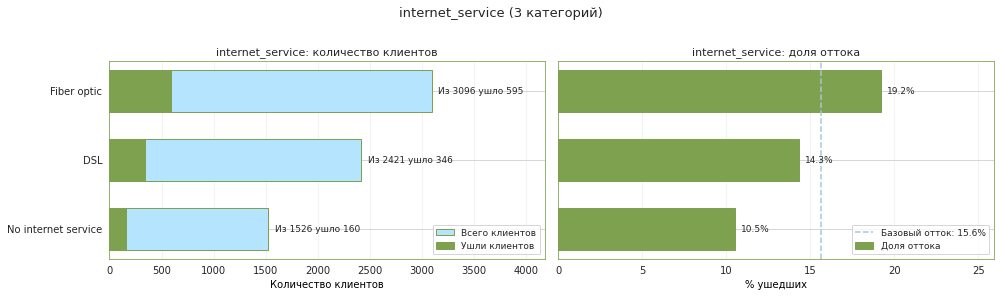


➤ INTERNET_SERVICE
-------------------------------------------------------
   Категория                  Всего    Ушло   Доля %
   ! Fiber optic               3096     595    19.2%
     DSL                       2421     346    14.3%
     No internet service       1526     160    10.5%
-----------------------------------------------------



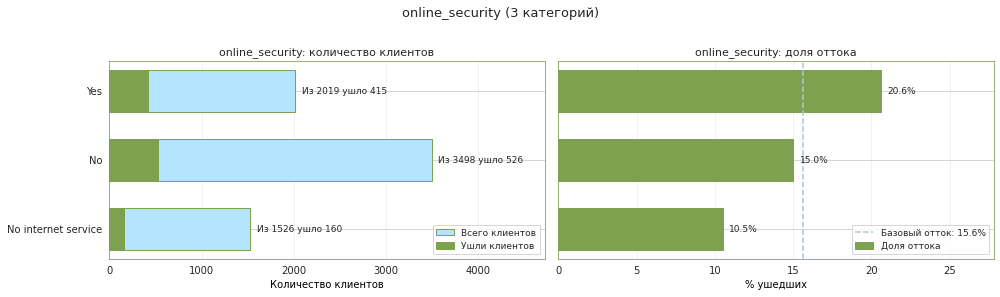


➤ ONLINE_SECURITY
-------------------------------------------------------
   Категория                  Всего    Ушло   Доля %
   ! Yes                       2019     415    20.6%
     No                        3498     526    15.0%
     No internet service       1526     160    10.5%
-----------------------------------------------------



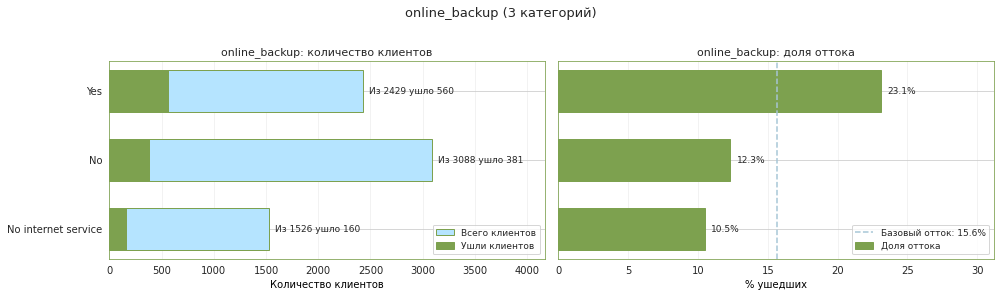


➤ ONLINE_BACKUP
-------------------------------------------------------
   Категория                  Всего    Ушло   Доля %
   ! Yes                       2429     560    23.1%
     No                        3088     381    12.3%
     No internet service       1526     160    10.5%
-----------------------------------------------------



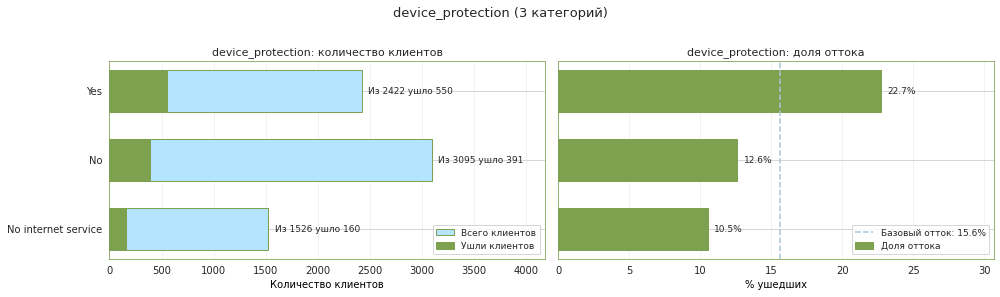


➤ DEVICE_PROTECTION
-------------------------------------------------------
   Категория                  Всего    Ушло   Доля %
   ! Yes                       2422     550    22.7%
     No                        3095     391    12.6%
     No internet service       1526     160    10.5%
-----------------------------------------------------



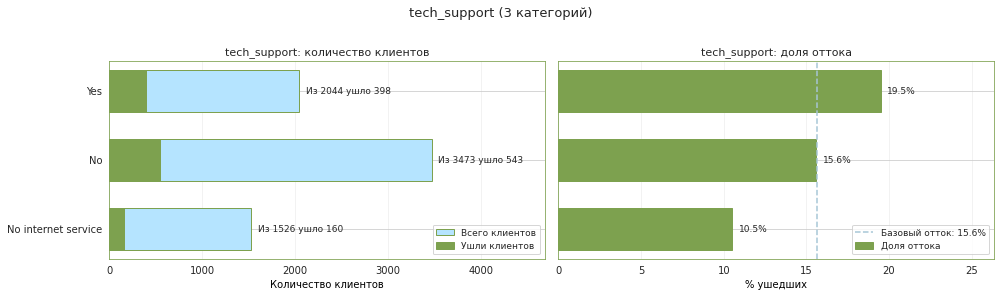


➤ TECH_SUPPORT
-------------------------------------------------------
   Категория                  Всего    Ушло   Доля %
   ! Yes                       2044     398    19.5%
     No                        3473     543    15.6%
     No internet service       1526     160    10.5%
-----------------------------------------------------



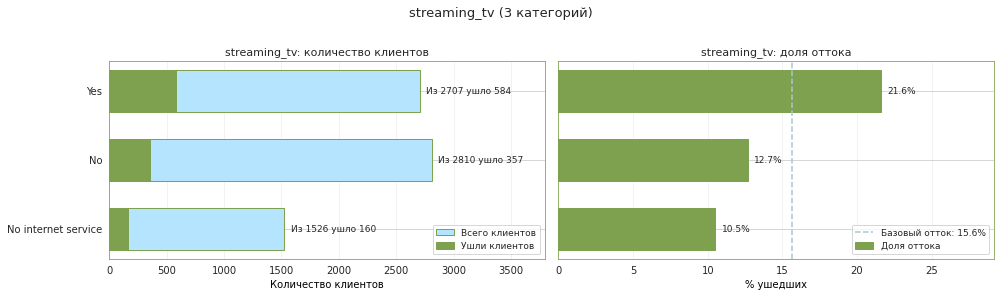


➤ STREAMING_TV
-------------------------------------------------------
   Категория                  Всего    Ушло   Доля %
   ! Yes                       2707     584    21.6%
     No                        2810     357    12.7%
     No internet service       1526     160    10.5%
-----------------------------------------------------



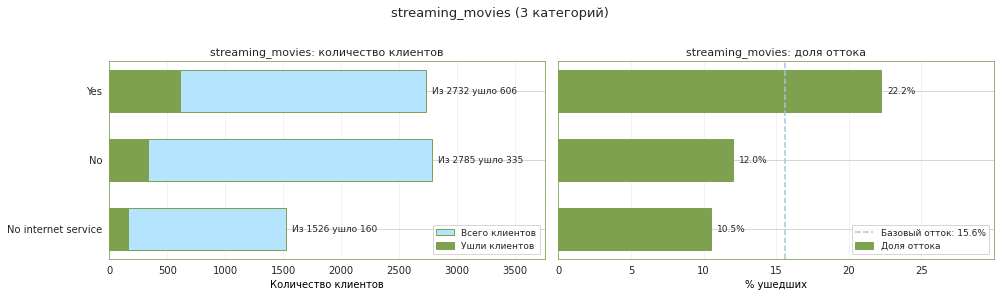


➤ STREAMING_MOVIES
-------------------------------------------------------
   Категория                  Всего    Ушло   Доля %
   ! Yes                       2732     606    22.2%
     No                        2785     335    12.0%
     No internet service       1526     160    10.5%
-----------------------------------------------------



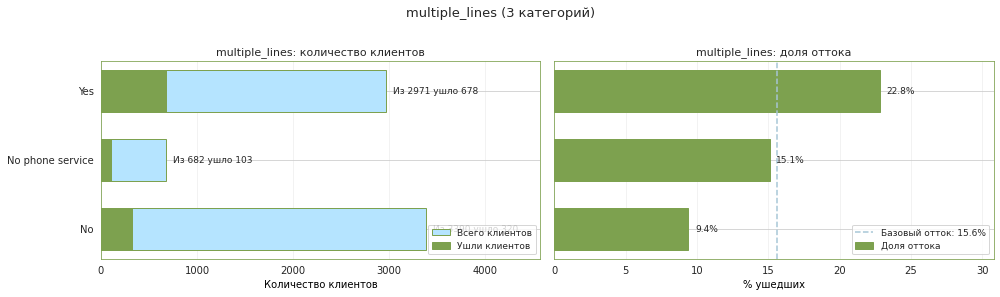


➤ MULTIPLE_LINES
-------------------------------------------------------
   Категория                  Всего    Ушло   Доля %
   ! Yes                       2971     678    22.8%
     No phone service           682     103    15.1%
     No                        3390     320     9.4%
-----------------------------------------------------



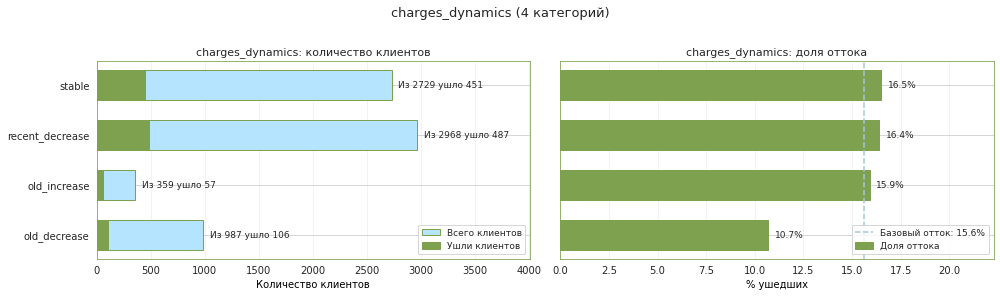


➤ CHARGES_DYNAMICS
-------------------------------------------------------
   Категория                  Всего    Ушло   Доля %
   ! stable                    2729     451    16.5%
   ! recent_decrease           2968     487    16.4%
   ! old_increase               359      57    15.9%
     old_decrease               987     106    10.7%
-----------------------------------------------------



In [29]:
# Автоматический список категориальных признаков
cat_cols = [
            c for c in df.columns
            if c not in ['customer_id']
            and (df[c].dtype == 'object' or df[c].dtype.name == 'category' or df[c].nunique() <= 2)
            and c not in ['churn', 'tenure_bin']
            ]

print(f"Категориальных признаков: {len(cat_cols)} | Базовый отток: {CHURN_BASE:.1f}%\n")

# Цикл по признакам: график и текстпод ним
for col in cat_cols:

    stats = (df.groupby(col, observed=True)
               .agg(всего=('churn', 'count'), ушло=('churn', 'sum'))
               .assign(доля_pct=lambda d: (d['ушло'] / d['всего'] * 100).round(1))
               .sort_values('доля_pct', ascending=False))

    y_pos = range(len(stats))

    # две панели рядом
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # Панель 1.количество клиентов
    ax = axes[0]
    ax.barh(y_pos, stats['всего'].values,color='#B5E4FF',edgecolor=COLORS['green_dark'], height=0.6,label='Всего клиентов')
    ax.barh(y_pos,stats['ушло'].values,color=COLORS['green_dark'],edgecolor=COLORS['green_dark'],height=0.6,
            label='Ушли клиентов')

    for i, (всего, ушло) in enumerate(zip(stats['всего'],stats['ушло'])):
        ax.text(всего+ stats['всего'].max() * 0.02, i, f'Из {всего} ушло {ушло}', va='center',fontsize=9)

    ax.set_yticks(y_pos)
    ax.set_yticklabels(stats.index.astype(str),fontsize=10)
    ax.invert_yaxis()
    ax.set_title(f'{col}: количество клиентов',fontsize=11)
    ax.set_xlabel('Количество клиентов', fontsize=10)
    ax.legend(fontsize=9,loc='lower right')
    ax.grid(alpha=0.3, axis='x')
    ax.set_xlim(0, stats['всего'].max() * 1.35)

    # Панель 2 доля оттока с базовой линией
    ax = axes[1]
    ax.barh(y_pos,stats['доля_pct'].values,color=COLORS['green_dark'],edgecolor=COLORS['green_dark'],height=0.6,
            label='Доля оттока')

    for i, pct in enumerate(stats['доля_pct']):
        ax.text(pct+ stats['доля_pct'].max() *0.02, i,f'{pct:.1f}%',va='center', fontsize=9)

    ax.axvline(CHURN_BASE,color=COLORS['pink'],linestyle='--', linewidth=1.5, label=f'Базовый отток: {CHURN_BASE:.1f}%')

    ax.set_yticks(y_pos)
    ax.set_yticklabels([])
    ax.invert_yaxis()
    ax.set_title(f'{col}: доля оттока', fontsize=11)
    ax.set_xlabel('% ушедших', fontsize=10)
    ax.legend(fontsize=9, loc='lower right')
    ax.grid(alpha=0.3,axis='x')
    ax.set_xlim(0, max(stats['доля_pct'].max(),CHURN_BASE) * 1.35)

    plt.suptitle(f'{col} ({len(stats)} категорий)', y=1.02, fontsize=13)
    plt.tight_layout()
    plt.show()

    # Текстовая сводка под графиком
    print(f"\n➤ {col.upper()}")
    print("-" * 55)
    print(f"   {'Категория':<24} {'Всего':>7} {'Ушло':>7} {'Доля %':>8}")

    for cat, row in stats.iterrows():
        marker = '!' if row['доля_pct'] > CHURN_BASE else ' '
        print(f"   {marker} {str(cat):<22} {int(row['всего']):>7} "
              f"{int(row['ушло']):>7} {row['доля_pct']:>7.1f}%")

    print("-" * 53)
    print()

<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">
    
К О М М Е Н Т А Р И Й

---

<span style="color:#A7C6D6"> 1. **ПО ТИПУ КОНТРАКТА** `[type]`

- <span style="color:black"> Самая многочисленная категория `Month-to-month` (3875)
- <span style="color:black"> Но **Больше** всего уходят на `Two year` (22.5%) и `One year` (21.2%)
- <span style="color:black"> **Меньше** всего - на `Month-to-month` (10.5%)

<span style="color:black">Доля ухода у долгосрочных **в 2.1 раза выше**. Разница **+12.0 п.п.**

**Возможная причина.** <span style="color:black"> Тарифы становятся не выгодными - клиент уходит, если не находит для себя выгодную альтернативу.

---

<span style="color:#A7C6D6"> 2. <span style="color:#A7C6D6"> **ПО ЭЛЕКТРОННОМУ СЧЁТУ** `[paperless_billing]`

- <span style="color:black"> **Больше** всего уходят с электронным счётом - `Yes` (17.3%)
- <span style="color:black"> **Меньше** всего - без электронного счёта `No` (13.2%)

<span style="color:black">Разница **+4.1 п.п.**

**Возможная причина.** <span style="color:black">Клиент с электронным счётом видит все цифры - сколько платит, за что, как менялся тариф. Легче заметить рост и сравнить с конкурентами. Плюс цифрово подкован - легко ищет альтернативы. Бумажный счёт - инерция: реже анализирует расходы.

---

<span style="color:#A7C6D6"> 3. <span style="color:#A7C6D6"> **ПО СПОСОБУ ОПЛАТЫ** `[payment_method]`

- <span style="color:black"> **Больше** всего уходят на автоматических платежах - `Credit card` (20.8%) и `Bank transfer` (20.5%)
- <span style="color:black"> **Меньше** всего - на `Mailed check` (7.3%)
- <span style="color:black"> `Electronic check` - промежуточное положение (14.8%)

<span style="color:black">Доля ухода у `Credit card` **в 2.9 раза выше**, чем у `Mailed check`. Разница **+13.5 п.п.**

**Возможная причина.** <span style="color:black">С автоплатёжем уйти легко - отозвал согласие, и всё. А с оплатой по бумажному счёту - нужно получить счёт, пойти в банк или на почту, заплатить. Возникает инерция: проще оставить как есть. Плюс клиенты с автоплатёжом цифрово подкованы - легко сравнивают тарифы и переключаются.

---

<span style="color:#A7C6D6"> 4. <span style="color:#A7C6D6"> **ПО ПОЛУ** `[gender]`

- <span style="color:black"> `Male` - 16.1%, `Female` - 15.1%

<span style="color:black">Разница всего **+1.0 п.п.** - пол практически не влияет на отток в данном срезе.

---

<span style="color:#A7C6D6"> 5. <span style="color:#A7C6D6"> **ПО ПЕНСИОНЕРАМ** `[senior_citizen]`

- <span style="color:black"> **Больше** уходят пенсионеры - `1` (20.3%)
- <span style="color:black"> **Меньше** - не пенсионеры `0` (14.7%)

<span style="color:black">Разница **+5.6 п.п.**

**Возможная причина.** <span style="color:black"> Пенсии в стране небольшие, важно не переплачивать. Находятся в зоне риска с учётом возраста дожития.

---

<span style="color:#A7C6D6"> 6. <span style="color:#A7C6D6"> **ПО НАЛИЧИЮ ПАРТНЁРА** `[partner]`

- <span style="color:black"> **Больше** уходят клиенты с партнёром - `Yes` (21.1%)
- <span style="color:black"> **Меньше** - без партнёра `No` (10.5%)

<span style="color:black">Разница **+10.6 п.п.** - одна из самых больших среди персональных.

**Возможная причина.** <span style="color:black">Возможно, не хватает пропускной способности на двоих или, опять же, не устраивает соотношение цены и качества услуг.

---

<span style="color:#A7C6D6"> 7. <span style="color:#A7C6D6"> **ПО НАЛИЧИЮ ДЕТЕЙ** `[dependents]`

- <span style="color:black"> **Больше** уходят клиенты с детьми - `Yes` (17.4%)
- <span style="color:black"> **Меньше** - без детей `No` (14.9%)

<span style="color:black">Разница **+2.5 п.п.** - влияние слабое.

**Возможная причина.** <span style="color:black">Причина та же.

---

<span style="color:#A7C6D6"> 8. <span style="color:#A7C6D6"> **ПО ТИПУ ПОДКЛЮЧЕНИЯ** `[internet_service]`

- <span style="color:black"> **Больше** всего уходят на `Fiber optic` (19.2%)
- <span style="color:black"> **Меньше** всего - без интернета (10.5%)
- <span style="color:black"> `DSL` - промежуточная категория (14.3%)

<span style="color:black">Доля ухода на `Fiber optic` **в 1.8 раза выше**, чем у `No internet service`. Разница **+8.7 п.п.**

**Возможная причина.** <span style="color:black">`Fiber optic` - дорогая премиум-услуга. Клиент платит много, ждёт максимального качества: скорости, стабильности, быстрой поддержки. Если что-то не так - смотрят конкурентов, уходит быстрее. А без интернета - только телефон, услуга простая, базовые потребности закрываются.

СООТВЕТСТВЕННО: <span style="color:black">ко всем последующим **допуслугам** далее эта возможная причина будет так же относиться. Так как заинтересованные и платёжеспособные клиенты, подключают сразу всё и, если уходят, то отключают так же всё.

---

<span style="color:#A7C6D6"> 9. <span style="color:#A7C6D6"> **ПО БЛОКИРОВКЕ ОПАСНЫХ САЙТОВ** `[online_security]` - допуслуга

- <span style="color:black"> `Yes` - 20.6%, `No` - 15.0%, `No internet service` - 10.5%

<span style="color:black">Разница между `Yes` и `No` - **+5.6 п.п.**

**Возможная причина.** <span style="color:black">Ненадёжность сервиса. Т.е блокирует то, что не должна и не блокирует то, что должна.

---

<span style="color:#A7C6D6"> 10. <span style="color:#A7C6D6"> **ПО ОБЛАЧНОМУ ХРАНИЛИЩУ** `[online_backup]` - допуслуга

- <span style="color:black"> **Больше** уходят с услугой - `Yes` (23.1%)
- <span style="color:black"> **Меньше** - без услуги `No` (12.3%)
- <span style="color:black"> `No internet service` - 10.5%

<span style="color:black">Доля оттока при `Yes` **в 1.9 раза выше**, чем при `No`. Разница **+10.8 п.п.**

**Возможная причина.** <span style="color:black">Клиент хранит файлы - активно пользуется интернетом. Требовательный: нужна высокая скорость и стабильность. Если интернет тормозит - уходит. Плюс многие подключают услугу, но не пользуются - платят зря и в какой-то момент отключают всё вместе.

---

<span style="color:#A7C6D6"> 11. <span style="color:#A7C6D6"> **ПО АНТИВИРУСУ** `[device_protection]` - допуслуга

- <span style="color:black"> **Больше** уходят с антивирусом - `Yes` (22.7%)
- <span style="color:black"> **Меньше** - без антивируса `No` (12.6%)
- <span style="color:black"> `No internet service` - 10.5%

<span style="color:black">Доля оттока при `Yes` **в 1.8 раза выше**, чем при `No`. Разница **+10.1 п.п.**

**Возможная причина.** <span style="color:black">Подключают бесплатные аналоги (Avast, Kaspersky Free). Эффект от ухода людей самых заинтересованных и платёжеспособных клиентов, которые уходят из-за проседания скорости (базовых важных для них).

---

<span style="color:#A7C6D6"> 12. <span style="color:#A7C6D6"> **ПО ТЕХПОДДЕРЖКЕ** `[tech_support]` - допуслуга

- <span style="color:black"> **Больше** уходят с техподдержкой - `Yes` (19.5%)
- <span style="color:black"> **Меньше** - без техподдержки `No` (15.6%)
- <span style="color:black"> `No internet service` - 10.5%

<span style="color:black">Разница **+3.9 п.п.** - минимальная среди семи услуг.

**Возможная причина.** <span style="color:black">Подключают не заранее, а когда уже что-то сломалось - интернет не работает, скорость упала, ТВ не показывает. Клиент уже столкнулся с проблемой. Если поддержка не помогла, то могут уйти. Разница небольшая, потому что связь слабая.

---

<span style="color:#A7C6D6"> 13. <span style="color:#A7C6D6"> **ПО СТРИМИНГОВОМУ ТВ** `[streaming_tv]` - допуслуга

- <span style="color:black"> **Больше** уходят со стриминговым ТВ - `Yes` (21.6%)
- <span style="color:black"> **Меньше** - без него `No` (12.7%)
- <span style="color:black"> `No internet service` - 10.5%

<span style="color:black">Доля оттока при `Yes` **в 1.7 раза выше**, чем при `No`. Разница **+8.9 п.п.**

**Возможная причина.** <span style="color:black">Если операторское ТВ проигрывает по цене или контенту - клиент уходит к другому оператору или отказывается от услуги.

---

<span style="color:#A7C6D6"> 14. <span style="color:#A7C6D6"> **ПО КАТАЛОГУ ФИЛЬМОВ** `[streaming_movies]` - допуслуга

- <span style="color:black"> **Больше** уходят с каталогом фильмов - `Yes` (22.2%)
- <span style="color:black"> **Меньше** - без него `No` (12.0%)
- <span style="color:black"> `No internet service` - 10.5%

<span style="color:black">Доля оттока при `Yes` **в 1.9 раза выше**, чем при `No`. Разница **+10.2 п.п.**

**Возможная причина.** <span style="color:black"> То же, что с ТВ, но ещё проще. Многие подключают каталог фильмов, но не смотрят - некогда или нет подходящего контента.

---

<span style="color:#A7C6D6"> 15. <span style="color:#A7C6D6"> **ПО МНОЖЕСТВЕННЫМ ЛИНИЯМ** `[multiple_lines]`

- <span style="color:black"> **Больше** уходят с подключёнными линиями - `Yes` (22.8%)
- <span style="color:black"> **Меньше** - без дополнительных линий `No` (9.4%)
- <span style="color:black"> `No phone service` - 15.1%

<span style="color:black">Доля оттока при `Yes` **в 2.4 раза выше**, чем при `No`. Разница **+13.4 п.п.** - **максимальная среди всех услуг**.

**Возможная причина.** <span style="color:black">Если конкурент предлагает дешевле или лучше - уходят легко. Самая сильная связь среди услуг - для них цена и качество критичны.

---

<span style="color:#A7C6D6"> 16. <span style="color:#A7C6D6"> **ПО ДИНАМИКЕ ТАРИФА** `[charges_dynamics]`

- <span style="color:black"> **Больше** всего уходят клиенты с `stable` (16.5%) и `recent_decrease` (16.4%)
- <span style="color:black"> **Меньше** всего - с `old_decrease` (10.7%)
- <span style="color:black"> `old_increase` (15.9%) - в середине

<span style="color:black">Разница между крайними группами - **+5.8 п.п.**

**Возможная причина.** <span style="color:black">Клиенты со **стабильным или сниженным** тарифом дают основную массу ушедших.

- <span style="color:black">`stable` - **самый высокий отток (16.5%)**. Тариф не менялся - возможно, клиент «забыт», нет предложений, нет обновлений.
- <span style="color:black">`recent_decrease` - **выше базового (16.4%)**. Недавно снизил тариф - возможно, готовится уйти или экономит, но всё равно уходит.
- <span style="color:black">`old_increase` - **выше базового (15.9%)**. Давно повысил тариф - ценность не оправдалась.
- <span style="color:black">`old_decrease` - **самый низкий отток (10.7%)**. Давно снизил и привык - самый лояльный сегмент.

**Что важно:** <span style="color:black">свежесть изменения не так важна, как направление. Клиенты со стабильным или сниженным тарифом - в зоне риска.

---

<span style="color:#A7C6D6"> **ОБЩАЯ ЗАКОНОМЕРНОСТЬ**

- <span style="color:black">**`Высокий отток`** - у **активных клиентов с высокими ожиданиями**. Платят больше, пользуются интенсивнее, требовательнее к качеству.
- <span style="color:black">**`Низкий отток`** - у **минимально вовлечённых**. Без допуслуг, на простых тарифах, с инерционными способами оплаты.

<div style="border-left: 2px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
#### Числовые и целевая
    
Сравниваем распределения числовых признаков у оставшихся и ушедших с помощью гистограммы и boxplot.

<span style="color:#A7C6D6"> **ПРИЗНАКИ ПО ГРУППАМ** (4 из 20)

| Группа | Признаки |
|---|---|
| Договор | `monthly_charges`, `total_charges` |
| Новые | `tenure_months`, `avg_monthly` |

<span style="color:#7DA14F">ВЫВОДИМ

- Boxplot - распределение по классам.
- Средние и медианы по классам.
- Разница - направление и величина.
    
<span style="color:#7DA14F">ТАКЖЕ
    
- Посмотрим 25% самых прибыльных клиентов в этом срезе

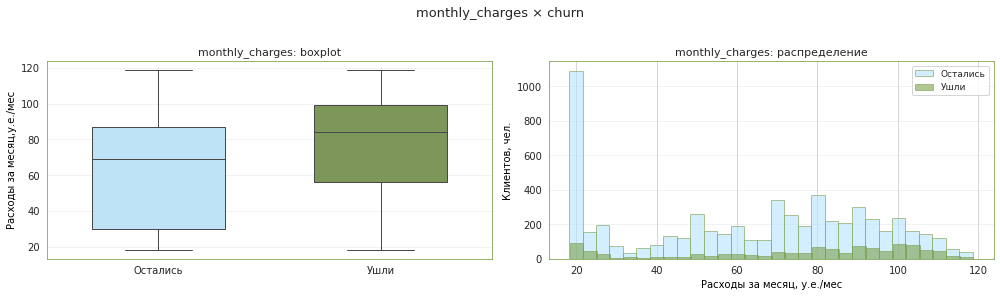


➤ MONTHLY_CHARGES (Расходы за месяц, у.е./мес)
-----------------------------------------------------------------
   Группа            n    Среднее    Медиана        Std
   Остались       5942      62.76      69.20      29.84
   Ушли           1101      75.55      84.20      29.12
-----------------------------------------------------------------
   Разница                 +12.78                       (+20.4%)
-----------------------------------------------------------------



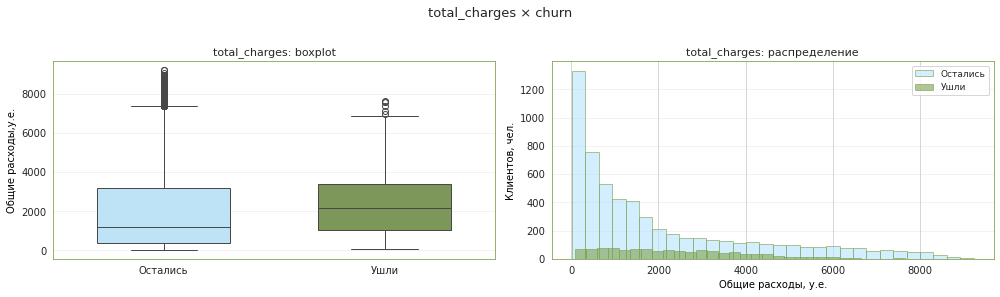


➤ TOTAL_CHARGES (Общие расходы, у.е.)
-----------------------------------------------------------------
   Группа            n    Среднее    Медиана        Std
   Остались       5942    2067.94    1192.80    2193.83
   Ушли           1101    2371.38    2139.03    1581.86
-----------------------------------------------------------------
   Разница                +303.43                       (+14.7%)
-----------------------------------------------------------------



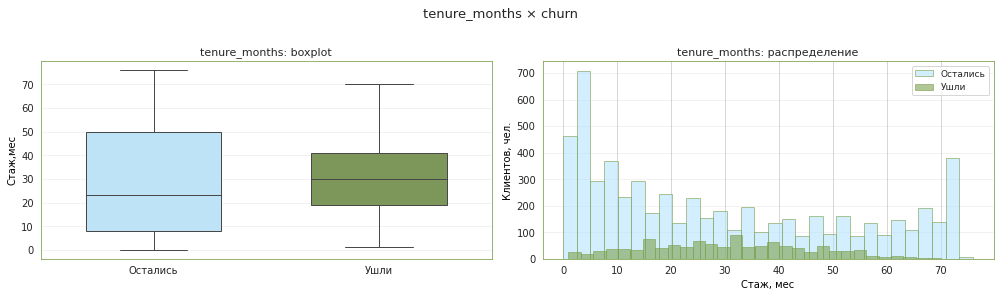


➤ TENURE_MONTHS (Стаж, мес)
-----------------------------------------------------------------
   Группа            n    Среднее    Медиана        Std
   Остались       5942      29.33      23.00      23.56
   Ушли           1101      30.39      30.00      15.07
-----------------------------------------------------------------
   Разница                  +1.06                       (+3.6%)
-----------------------------------------------------------------



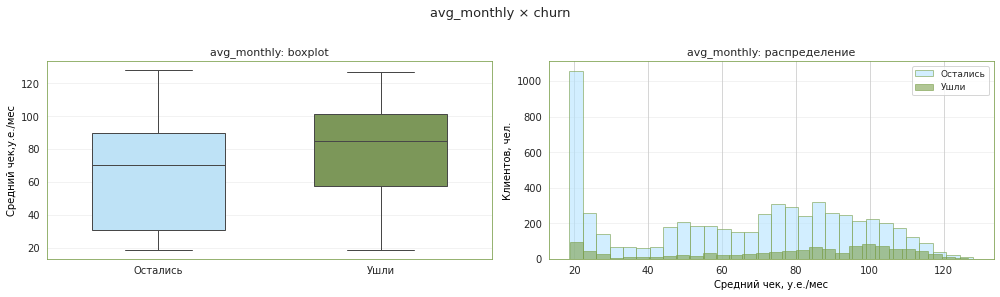


➤ AVG_MONTHLY (Средний чек, у.е./мес)
-----------------------------------------------------------------
   Группа            n    Среднее    Медиана        Std
   Остались       5942      64.49      70.03      30.74
   Ушли           1101      77.66      85.00      30.11
-----------------------------------------------------------------
   Разница                 +13.17                       (+20.4%)
-----------------------------------------------------------------



In [30]:
num_cols = ['monthly_charges', 'total_charges', 'tenure_months', 'avg_monthly']

# Единицы измерения
units = {
         'monthly_charges': ('у.е./мес', 'Расходы за месяц'),
         'total_charges':   ('у.е.',     'Общие расходы'),
         'tenure_months':   ('мес',      'Стаж'),
         'avg_monthly':     ('у.е./мес', 'Средний чек'),
        }

colors_map = {0: '#B5E4FF', 1: COLORS['green_dark']}
labels_map = {0: 'Остались', 1: 'Ушли'}
 
# графики и статистика под ними
for col in num_cols:
    unit, title = units[col]

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # Boxplot
    ax_box = axes[0]
    sns.boxplot(data=df,x='churn', y=col, ax=ax_box, hue='churn', palette=colors_map,legend=False, width=0.6)
    ax_box.set_xticks([0, 1])
    ax_box.set_xticklabels(['Остались', 'Ушли'])
    ax_box.set_xlabel('')
    ax_box.set_ylabel(f'{title},{unit}', fontsize=10)
    ax_box.set_title(f'{col}: boxplot',fontsize=11)
    ax_box.grid(alpha=0.3,axis='y')

    # Гистограмма по классам
    ax_hist = axes[1]
    for churn_val in [0, 1]:
        subset = df[df['churn'] == churn_val][col].dropna()
        ax_hist.hist(subset, bins=30, alpha=0.6, color=colors_map[churn_val],
                     edgecolor=COLORS['green_dark'],label=labels_map[churn_val])

    ax_hist.set_title(f'{col}: распределение', fontsize=11)
    ax_hist.set_xlabel(f'{title}, {unit}',fontsize=10)
    ax_hist.set_ylabel('Клиентов, чел.', fontsize=10)
    ax_hist.legend(fontsize=9)
    ax_hist.grid(alpha=0.3, axis='y')

    plt.suptitle(f'{col} × churn',y=1.02, fontsize=13)
    plt.tight_layout()
    plt.show()

    # Статистика под графиком
    stats_0 = df[df['churn']== 0][col]
    stats_1 = df[df['churn'] ==1][col]
    mean_diff = stats_1.mean() - stats_0.mean()
    pct_diff = mean_diff / stats_0.mean() * 100

    print(f"\n➤ {col.upper()} ({title}, {unit})")
    print("-" * 65)
    print(f"   {'Группа':<12} {'n':>6} {'Среднее':>10} {'Медиана':>10} {'Std':>10}")
    print(f"   {'Остались':<12} {len(stats_0):>6} "
          f"{stats_0.mean():>10.2f} {stats_0.median():>10.2f} {stats_0.std():>10.2f}")
    print(f"   {'Ушли':<12} {len(stats_1):>6} "
          f"{stats_1.mean():>10.2f} {stats_1.median():>10.2f} {stats_1.std():>10.2f}")
    print("-" * 65)
    print(f"   {'Разница':<12} {'':>6} {mean_diff:>+10.2f} "
          f"{'':>10} {'':>10} ({pct_diff:+.1f}%)")
    print("-" * 65)
    print()

<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">К О М М Е Н Т А Р И Й

---

<span style="color:#7DA14F">
    
Мы сравнили распределения числовых признаков у ушедших и оставшихся.

---    
    
<span style="color:#A7C6D6">**`monthly_charges` (расходы за месяц)**

- <span style="color:black"> У ушедших - **75.55 у.е./мес**, у оставшихся - **62.76**. Разница **+20.4%**.
- <span style="color:black"> **Медиана** тоже выше: 84.20 vs 69.20. Значит, это **не единичные выбросы**, а устойчивый сдвиг.
- <span style="color:black"> **Std** почти одинаковый (29.12 vs 29.84) - разброс внутри групп схож.

**Вывод:** <span style="color:black"> дорогой тариф - выше риск ухода. Клиент платит много, ожидания высокие, если не оправдываются - уходит.

---

<span style="color:#A7C6D6">**`total_charges` (общие расходы)**

- <span style="color:black"> У ушедших - **2371 у.е.**, у оставшихся - **2068**. Разница **+14.7%**.
- <span style="color:black"> **Медиана** почти в 2 раза выше: 2139 vs 1193.
- <span style="color:black"> **Std** у оставшихся больше (2194 vs 1582).

**Вывод:**<span style="color:black">  ушедшие - клиенты с большими накопленными расходами. Далее посмотрим поближе.

---

<span style="color:#A7C6D6">**`tenure_months` (длительность контракта клиента)**

- <span style="color:black"> У ушедших - **30.39 мес**, у оставшихся - **29.33**. Разница **+3.6%** - минимальная.
- <span style="color:black"> **Медиана** выше: 30.00 vs 23.00. Но разница слабая.
- <span style="color:black"> **Std** у ушедших **меньше** (15.07 vs 23.56) - они **более однородны** по длительности контракта.

**Вывод:** <span style="color:black"> **почти не различает** классы. Скорее всего признак полезен только **в комбинации** с другими (`type`, `charges_dynamics`).

---

<span style="color:#A7C6D6">**`avg_monthly` (средний чек)**

- <span style="color:black"> У ушедших - **77.66 у.е./мес**, у оставшихся - **64.49**. Разница **+20.4%**.
- <span style="color:black"> **Медиана**: 85.00 vs 70.03 - устойчивый сдвиг.
- <span style="color:black"> **Std** почти одинаковый (30.11 vs 30.74) - разброс схож.

**Вывод:** <span style="color:black"> картина та же, что с `monthly_charges`. Ушедшие **платили больше** в среднем за всё время.

---

<span style="color:#A7C6D6">**ДАЛЕЕ ПОСМОТРИМ**

1. <span style="color:black"> **Q4 признака:** `avg_monthly` (+20.4%), который показывает, что дорогие клиенты (25%) уходят чаще.
2. <span style="color:black"> Посмотрим выручку Q4 и остальных 75% клиентов.

<div style="border-left: 6px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 



In [31]:
# num_services (один раз)
has_internet = (df['internet_service'] != 'No internet service').astype(int)
has_phone = (df['multiple_lines'] != 'No phone service').astype(int)
extra_services = ['online_security', 'online_backup', 'device_protection',
                  'tech_support', 'streaming_tv', 'streaming_movies']
extra_count = (df[extra_services] == 'Yes').sum(axis=1)
multi_lines = (df['multiple_lines'] == 'Yes').astype(int)

df['num_services'] = has_internet + has_phone + extra_count + multi_lines

# Q4: порог, подвыборки, метрики
Q4_THRESHOLD = df['avg_monthly'].quantile(0.75)
df['is_q4'] = (df['avg_monthly'] >= Q4_THRESHOLD).astype(int)

df_q4 = df[df['is_q4'] == 1].copy()
df_others = df[df['is_q4'] == 0].copy()

n_q4 = len(df_q4)
n_others = len(df_others)

CHURN_Q4 = df_q4['churn'].mean() * 100
CHURN_OTHERS = df_others['churn'].mean() * 100

GROUP_COLS = ['type', 'payment_method', 'internet_service', 'charges_dynamics']

# Вывод базовых метрик
print("NUM_SERVICES в df:")
print(f"  Тип:       {df['num_services'].dtype}")
print(f"  Пропуски:  {df['num_services'].isna().sum()}")
print(f"  Диапазон:  {df['num_services'].min()}–{df['num_services'].max()}")
print()

print("РАЗДЕЛЕНИЕ НА ГРУППЫ:")
print("=" * 65)
print(f"Порог Q4:                {Q4_THRESHOLD:.2f} у.е./мес")
print(f"Остальные (75%):         {n_others} клиентов, отток {CHURN_OTHERS:.1f}%")
print(f"Топ-25% (Q4):            {n_q4} клиентов, отток {CHURN_Q4:.1f}%")
print(f"Базовый отток (все):     {CHURN_BASE:.1f}%")

NUM_SERVICES в df:
  Тип:       int64
  Пропуски:  0
  Диапазон:  1–9

РАЗДЕЛЕНИЕ НА ГРУППЫ:
Порог Q4:                92.21 у.е./мес
Остальные (75%):         5282 клиентов, отток 12.3%
Топ-25% (Q4):            1761 клиентов, отток 25.7%
Базовый отток (все):     15.6%


<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">
    
<span style="color:#7DA14F">К О М М Е Н Т А Р И Й

---
    
<span style="color:#7DA14F">    
    

<span style="color:black">Топ-25% клиентов по среднему чеку. Порог - **92.21 у.е./мес**. Всё, что выше - попадает в Q4.

- <span style="color:black">**1761 клиент (25% от всех)** - четвёртая часть базы.
- <span style="color:black">**Средний чек Q4** - значительно выше среднего по базе (64.76).
- <span style="color:black">**Отток в Q4 - 25.7%** - каждый четвёртый уходит.
-<span style="color:black">**Разница с базовым - +10.1 п.п.** (25.7% против 15.6%).

<span style="color:#A7C6D6">ВАЖНО ТАК КАК

1. <span style="color:black">**Дорогие клиенты уходят чаще.** Отток в Q4 в **1.6 раза выше** базового.
2. <span style="color:black">**Это клиенты с самой высокой выручкой.** Средний чек Q4 значительно выше среднего. Потеря одного такого клиента = потеря нескольких обычных.
3. <span style="color:black">**Зона риска.** Четверть клиентов - самая ценная часть базы - уходит с повышенной частотой.

Для бизнеса Q4 - приоритет для удержания. <span style="color:black">Промокоды и персональные предложения для них **окупаются** - потому что эти клиенты приносят больше выручки.

In [32]:
# Разбивка Q4 по признакам

for col in GROUP_COLS:
    if col not in df_q4.columns:
        continue

    stats = (df_q4.groupby(col, observed=True)
               .agg(всего=('churn', 'count'), ушло=('churn', 'sum'))
               .assign(доля_оттока=lambda d: (d['ушло'] / d['всего'] * 100).round(1),
                       доля_группы=lambda d: (d['всего'] / n_q4 * 100).round(1))
               .sort_values('доля_оттока', ascending=False))

    print(f"\n➤ {col.upper()} (внутри Q4)")
    print("-" * 65)
    print(f"   {'Категория':<28} {'Всего':>7} {'Ушло':>7} {'Отток':>8}")

    for cat, row in stats.iterrows():
        marker = '!' if row['доля_оттока'] > CHURN_Q4 else ' '
        print(f"   {marker} {str(cat):<26} {int(row['всего']):>7} "
              f"{int(row['ушло']):>7} {row['доля_оттока']:>7.1f}%")

    print("-" * 65)


➤ TYPE (внутри Q4)
-----------------------------------------------------------------
   Категория                      Всего    Ушло    Отток
   ! One year                       451     140    31.0%
     Two year                       439     112    25.5%
     Month-to-month                 871     201    23.1%
-----------------------------------------------------------------

➤ PAYMENT_METHOD (внутри Q4)
-----------------------------------------------------------------
   Категория                      Всего    Ушло    Отток
   ! Credit card (automatic)        412     120    29.1%
   ! Bank transfer (automatic)      441     115    26.1%
     Electronic check               809     201    24.8%
     Mailed check                    99      17    17.2%
-----------------------------------------------------------------

➤ INTERNET_SERVICE (внутри Q4)
-----------------------------------------------------------------
   Категория                      Всего    Ушло    Отток
   ! Fiber optic  

<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">
    
<span style="color:#7DA14F">К О М М Е Н Т А Р И Й
    
---

Мы взяли **самых дорогих клиентов** (Q4) - тех, кто платит больше **92.21 у.е.** в месяц. Это топ-25% базы - **1761 человек**. Посмотрели, **как они уходят** и **с чем это связано**.

---

<span style="color:#A7C6D6"> **ПО ПРИЗНАКАМ**

<span style="color:#7DA14F">`type` **Тип контракта.**
    
- Больше всех уходят клиенты на **`One year` (31.0%)** и **`Two year` (25.5%)**. У `Month-to-month` - 23.1%. **Долгосрочные контракты среди дорогих клиентов - самая рискованная группа.**

<span style="color:#7DA14F">`payment_method` **Способ оплаты.**
    
- Больше всех уходят с **`Credit card` (29.1%)** и **`Bank transfer` (26.1%)** - автоплатежи. Реже всего - **`Mailed check` (17.2%)**. Это подтверждает гипотезу, что мы упоминали в категориальных признаках.

<span style="color:#7DA14F">`internet_service` **Тип интернета.** 
    
- Больше всех уходят на **`Fiber optic` (25.9%)** - 443 человека. На `DSL` - всего 18.9%. **Оптоволокно - премиум-услуга с высокими ожиданиями.**

<span style="color:#7DA14F">`charges_dynamics` **Динамика тарифа.** 
    
- Группа **`stable` - 29.5%**. То есть те, кто **не менял тариф**, уходят чаще всех. 
- У `recent_decrease` - 25.4%, у `old_increase` - 19.2%, у `old_decrease` - 14.6%. 
    
Возможно, **Q4 клиенты со стабильным тарифом уходят, так как им никто не предлагает информацию о новых тарифах или не обновляются линейки тарифов, поэтому они уходят к конкурентам.**

---

<span style="color:#A7C6D6">**ГЛАВНЫЕ ВЫВОДЫ**

<span style="color:#7DA14F">Среди Q4 клиентов группа риска - это **те клиенты, у кого:**
    
- долгосрочный контракт (`One year` / `Two year`),
- автоплатёж (`Credit card` / `Bank transfer`),
- оптоволокно (`Fiber optic`),
- **стабильный тариф без изменений**.

<span style="color:#A7C6D6">**ДЛЯ БИЗНЕСА**

1. **Удерживать именно Q4** - они приносят больше всего денег. Потеря одного = потеря 2-3 обычных.
2. **Обратить внимание на `stable` + Q4** - 29.5% оттока. Им нужно **менять условия**, предлагать новые тарифы.
3. **Долгосрочные + автоплатёж + оптоволокно** - двойная зона риска. Персональные предложения именно для них.

---

<div style="border-left: 6px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 

- Смотрим клиентов по двум группам и их отток по категориям

In [33]:
for col in GROUP_COLS:
    if col not in df.columns:
        continue

    cross = (df.groupby([col, 'is_q4'],observed=True)['churn']
               .mean().unstack()*100).round(1)
    cross.columns = ['Остальные','Топ-25%']
    cross['Разница'] =(cross['Топ-25%'] -cross['Остальные']).round(1)
    cross['Клиентов Q4']= df[df['is_q4'] ==1].groupby(col,observed=True).size()

    print(f"\n➤ ОТТОК (%) ПО '{col.upper()}' - Q4 vs ОСТАЛЬНЫЕ")
    print("-" * 75)
    print(cross.to_string())
    print("-" * 75)


➤ ОТТОК (%) ПО 'TYPE' - Q4 vs ОСТАЛЬНЫЕ
---------------------------------------------------------------------------
                Остальные  Топ-25%  Разница  Клиентов Q4
type                                                    
Month-to-month        6.9     23.1     16.2          871
One year             16.9     31.0     14.1          451
Two year             21.4     25.5      4.1          439
---------------------------------------------------------------------------

➤ ОТТОК (%) ПО 'PAYMENT_METHOD' - Q4 vs ОСТАЛЬНЫЕ
---------------------------------------------------------------------------
                           Остальные  Топ-25%  Разница  Клиентов Q4
payment_method                                                     
Bank transfer (automatic)       18.3     26.1      7.8          441
Credit card (automatic)         17.7     29.1     11.4          412
Electronic check                 9.6     24.8     15.2          809
Mailed check                     6.6     17.2     10.6 

<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">
    
<span style="color:#7DA14F">К О М М Е Н Т А Р И Й
    
---
    
<span style="color:#A7C6D6">    

<span style="color:black"> Мы сравнили топ-25% по чеку (Q4) и остальные 75%. Для каждой категории посмотрели: отличается ли отток у дорогих клиентов от обычных. Колонка **«Разница»** - насколько выше отток в Q4.

---

<span style="color:#7DA14F">**ВИДИМ**

**Разница почти везде положительная - от +4 до +16 п.п.** <span style="color:black"> Т.е. **дорогие клиенты уходят чаще** почти во всех категориях. Не потому что категория плохая, а потому что **Q4 сам по себе - зона риска**.

<span style="color:#7DA14F">ПО ТИПУ КОНТРАКТА

- <span style="color:black"> **`Month-to-month` - самый сильный эффект.** Обычные месячные клиенты почти не уходят (6.9%), а дорогие - уходят в 23.1%. Разница **+16.2 п.п.** У `Two year` разница минимальна (+4.1) - потому что и обычные, и дорогие на двухлетнем контракте уходят часто.

**Вывод:** <span style="color:black"> **дорогой тариф + месячный контракт - это самая рискованная комбинация.**

<span style="color:#7DA14F">ПО СПОСОБУ ОПЛАТЫ

- **`Electronic check` — самый сильный эффект.** <span style="color:black"> Обычные клиенты с этим способом почти не уходят (9.6%), а дорогие — в 24.8%. Разница **+15.2 п.п.**

**Вывод:** <span style="color:black"> **дорогой тариф + электронный чек - это зона риска.** Возможно, клиенты с ручным подтверждением платежа более чувствительны к цене.

<span style="color:#7DA14F">ПО ТИПУ ИНТЕРНЕТА

- **`Fiber optic` - сильнейший эффект (+14.9).** <span style="color:black"> Обычные клиенты на оптоволокне уходят редко (11.0%), а дорогие - в 2.4 раза чаще (25.9%). У `DSL` разница минимальна (+4.7).

**Вывод:** <span style="color:black"> **дорогой тариф + оптоволокно - это зона риска.** Fiber optic - премиум-услуга с высокими ожиданиями.

---

<span style="color:#7DA14F">ПО ДИНАМИКЕ ТАРИФА

- **`stable` - максимальная разница (+16.4 п.п.).** <span style="color:black"> Обычные клиенты, которые ни разу не меняли тариф, уходят редко (13.1%), а **дорогие — в 29.5% случаев**. Почти **каждый третий** уходит.

**Вывод:**<span style="color:black"> **дорогой тариф + не меняли ни разу тариф - это самая опасная комбинация.**

---

<span style="color:#7DA14F">**ИТОГ**

1.<span style="color:black">  **Дорогой тариф (Q4).**
2.<span style="color:black"> **Месячный контракт** (`Month-to-month`) - разница +16.2.
3.<span style="color:black">  **Электронный чек** (`Electronic check`) - разница +15.2.
4.<span style="color:black">  **Оптоволокно** (`Fiber optic`) - разница +14.9.
5.<span style="color:black">  **Стабильный тариф** (`stable`) - разница +16.4.

<span style="color:black"> Дорогой тариф сам по себе **не проблема**. Проблема - **дорогой тариф + отсутствие изменений**. Нет работы над удержанием или нет выгодного предложения - уходят к конкуренту. **Самая опасная группа - `stable` + Q4 = 29.5%.**

<span style="color:#7DA14F"> **ДЛЯ БИЗНЕСА**

- <span style="color:black"> Работать над удержанием дорогих клиентов, которые не меняли тариф. Формировать конкурентоспособные предложения тарифов.

---

<div style="border-left: 6px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 

- Смотрим сколько услуг у ушедших и оставшихся клиентов по этим двум группам

In [34]:
# Количество услуг Q4 vs Остальные

# остальные 75%
print("=" * 65)
print("ОСТАЛЬНЫЕ 75% (avg_monthly < порога)")
print("=" * 65)

services_others = (df_others.groupby('churn')['num_services']
                     .agg(['count', 'mean', 'median', 'min', 'max'])
                     .round(2))
services_others.index= ['Остались', 'Ушли']
services_others.columns = ['Клиентов', 'Среднее', 'Медиана', 'Мин', 'Макс']

print("\nКОЛИЧЕСТВО УСЛУГ У ОСТАЛЬНЫХ:")
print("=" * 65)
print(services_others.to_string())
print("=" * 65)

mean_0 =df_others[df_others['churn'] == 0]['num_services'].mean()
mean_1 =df_others[df_others['churn'] == 1]['num_services'].mean()
print(f"\nРазница (Ушли − Остались): {mean_1 -mean_0:+.2f} услуги")

services_dist_others = (df_others
                          .groupby(['num_services', 'churn'])
                          .size()
                          .unstack(fill_value=0))
services_dist_others.columns = ['Остались','Ушли']
services_dist_others['Всего'] =services_dist_others.sum(axis=1)
services_dist_others['Отток %'] = (services_dist_others['Ушли']/services_dist_others['Всего']* 100).round(1)

print("\nРАСПРЕДЕЛЕНИЕ ПО КОЛИЧЕСТВУ УСЛУГ У ОСТАЛЬНЫХ:")
print("=" * 65)
print(services_dist_others.to_string())
print()

# топ-25% (Q4)
print("=" * 65)
print("ТОП-25% (Q4) (avg_monthly >= порога)")
print("=" * 65)

services_q4 = (df_q4
                 .groupby('churn')['num_services']
                 .agg(['count','mean','median','min','max'])
                 .round(2))
services_q4.index = ['Остались','Ушли']
services_q4.columns = ['Клиентов', 'Среднее','Медиана', 'Мин','Макс']

print("\nКОЛИЧЕСТВО УСЛУГ У Q4:")
print("=" * 65)
print(services_q4.to_string())
print("=" * 65)

mean_0= df_q4[df_q4['churn'] ==0]['num_services'].mean()
mean_1= df_q4[df_q4['churn'] ==1]['num_services'].mean()
print(f"\nРазница (Ушли - Остались): {mean_1 - mean_0:+.2f} услуги")

services_dist_q4 = (df_q4
                      .groupby(['num_services', 'churn'])
                      .size()
                      .unstack(fill_value=0))
services_dist_q4.columns = ['Остались', 'Ушли']
services_dist_q4['Всего'] = services_dist_q4.sum(axis=1)
services_dist_q4['Отток %'] = (services_dist_q4['Ушли']/services_dist_q4['Всего'] *100).round(1)

print("\nРАСПРЕДЕЛЕНИЕ ПО КОЛИЧЕСТВУ УСЛУГ У Q4:")
print("=" * 65)
print(services_dist_q4.to_string())
print()

# Сравнение
print("=" * 65)
print("СРАВНЕНИЕ: ОСТАЛЬНЫЕ vs Q4")
print("=" * 65)

compare = pd.DataFrame({
                        'Остальные (среднее)': df_others.groupby('churn')['num_services'].mean().round(2),
                        'Q4 (среднее)':        df_q4.groupby('churn')['num_services'].mean().round(2),
                        })
compare.index = ['Остались', 'Ушли']
compare['Разница между группами'] =(compare['Q4 (среднее)'] -compare['Остальные (среднее)']).round(2)

print(compare.to_string())
print()

compare_dist = pd.DataFrame({
                            'Остальные: отток %': services_dist_others['Отток %'],
                            'Q4: отток %':        services_dist_q4['Отток %'],
                            'Разница п.п.':       (services_dist_q4['Отток %']-services_dist_others['Отток %']).round(1),
                             })
print("ОТТОК (%) ПО КОЛИЧЕСТВУ УСЛУГ — ОСТАЛЬНЫЕ vs Q4:")
print("=" * 65)
print(compare_dist.to_string())

ОСТАЛЬНЫЕ 75% (avg_monthly < порога)

КОЛИЧЕСТВО УСЛУГ У ОСТАЛЬНЫХ:
          Клиентов  Среднее  Медиана  Мин  Макс
Остались      4634     3.22      3.0    1     9
Ушли           648     4.16      4.0    1     9

Разница (Ушли − Остались): +0.94 услуги

РАСПРЕДЕЛЕНИЕ ПО КОЛИЧЕСТВУ УСЛУГ У ОСТАЛЬНЫХ:
              Остались  Ушли  Всего  Отток %
num_services                                
1                 1166    98   1264      7.8
2                  772    87    859     10.1
3                  791    55    846      6.5
4                  793   128    921     13.9
5                  494   104    598     17.4
6                  291    70    361     19.4
7                  192    54    246     22.0
8                   99    41    140     29.3
9                   36    11     47     23.4

ТОП-25% (Q4) (avg_monthly >= порога)

КОЛИЧЕСТВО УСЛУГ У Q4:
          Клиентов  Среднее  Медиана  Мин  Макс
Остались      1308     6.53      6.0    4     9
Ушли           453     6.70      7.0    4     

<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">К О М М Е Н Т А Р И Й

---

Мы разделили клиентов на **две группы**: остальные 75% (средний чек ниже **92.21 у.е.**) и топ-25% по среднему чеку (Q4). Для каждой посмотрели, **сколько услуг** у ушедших и оставшихся. `Чтобы понять, влияет ли количество услуг на уход внутри каждой группы.`

---

<span style="color:#A7C6D6">
    
**ОСТАЛЬНЫЕ 75%** <span style="color:black">(avg_monthly < 92.21)

- <span style="color:black"> **Отток в группе - 12.3%** - ниже базового (15.6%).
- <span style="color:black">**Среднее количество услуг:** у оставшихся **3.22**, у ушедших **4.16**.
- <span style="color:black"> Медиана: 3 у оставшихся, 4 у ушедших. Сдвиг вверх.
- <span style="color:black">Видим, что отток **растёт** с числом услуг. Пик на 8 услугах (29.3%).

---

**ТОП-25% (Q4)** <span style="color:black">(avg_monthly ≥ 92.21)

- <span style="color:black">**Отток в группе - 25.7%** - почти в 2 раза выше остальных.
- <span style="color:black">**Среднее количество услуг:** у оставшихся **6.53**, у ушедших **6.70**. Разница всего **+0.17** - почти незаметна.
- <span style="color:black">Медиана: 6 у оставшихся, 7 у ушедших. Небольшой сдвиг.
- <span style="color:black">**Диапазон 4-9** - в Q4 нет клиентов с 1-3 услугами. Пик на 7 услугах (33.5%), потом **снижение**. С 8-9 услугами уходят **реже**, чем с 7.

---

**ДЛЯ БИЗНЕСА**

1. **Клиенты Q4**

- <span style="color:black">`с 7 услугами` - зона риска (33.5%). Предлагать апгрейды, скидки, персональные условия.
- <span style="color:black">`с 4 услугами` - самая лояльная группа (6.8%).

2. **Остальные клиенты**

- <span style="color:black">`с 8 услугами` - 29.3% оттока. Тоже зона риска.
- <span style="color:black">`с 1 и 3 услугами` - 7.8% и 6.5% самые лояльные группы.

---

<div style="border-left: 6px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 

- Смотрим какая из групп принесла сколько выручки

In [35]:
revenue = (df.groupby('is_q4')
             .agg(
                  клиентов=('customer_id', 'count'),
                  всего=('total_charges', 'sum'),
                  выручка_средняя=('total_charges', 'mean'),
                  ушли=('churn', 'sum'),
                  выручка_ушедших=('total_charges', lambda x: x[df.loc[x.index, 'churn'] == 1].sum()),
                 )
             .round(2))

revenue.index = ['Остальные (75%)', 'Топ-25% (Q4)']

# Доли
total_revenue = revenue['всего'].sum()
revenue['доля_выручки_%'] =(revenue['всего'] / total_revenue *100).round(1)
revenue['доля_клиентов_%']= (revenue['клиентов']/ len(df)* 100).round(1)

# Потери от ушедших
revenue['потери_от_ушедших'] =revenue['выручка_ушедших']
revenue['доля_потерь_%'] =(revenue['выручка_ушедших'] / total_revenue * 100).round(1)

# Вывод
print("ВЫРУЧКА ПО ГРУППАМ:")
print("-" * 125)
print(revenue[['клиентов', 'доля_клиентов_%', 'всего',
               'доля_выручки_%', 'выручка_средняя',
               'ушли', 'выручка_ушедших', 'доля_потерь_%']].to_string())
print("-" * 125)

# Итоги
print(f"\nВСЕГО КЛИЕНТОВ:          {len(df):,}")
print(f"ВСЕГО ВЫРУЧКА:           {total_revenue:,.2f} у.е.\n")
print(f"Q4 (топ-25%):            {revenue.loc['Топ-25% (Q4)', 'всего']:,.2f} у.е. "
      f"({revenue.loc['Топ-25% (Q4)', 'доля_выручки_%']}% всей выручки)")
print(f"Остальные (75%):         {revenue.loc['Остальные (75%)', 'всего']:,.2f} у.е. "
      f"({revenue.loc['Остальные (75%)', 'доля_выручки_%']}% всей выручки)\n")
print(f"ПОТЕРИ ОТ УШЕДШИХ В Q4:  {revenue.loc['Топ-25% (Q4)', 'выручка_ушедших']:,.2f} у.е. "
      f"({revenue.loc['Топ-25% (Q4)', 'доля_потерь_%']}% всей выручки)")

ВЫРУЧКА ПО ГРУППАМ:
-----------------------------------------------------------------------------------------------------------------------------
                 клиентов  доля_клиентов_%       всего  доля_выручки_%  выручка_средняя  ушли  выручка_ушедших  доля_потерь_%
Остальные (75%)      5282             75.0  7589951.47            50.9          1436.95   648       1118460.87            7.5
Топ-25% (Q4)         1761             25.0  7308652.78            49.1          4150.29   453       1492425.51           10.0
-----------------------------------------------------------------------------------------------------------------------------

ВСЕГО КЛИЕНТОВ:          7,043
ВСЕГО ВЫРУЧКА:           14,898,604.25 у.е.

Q4 (топ-25%):            7,308,652.78 у.е. (49.1% всей выручки)
Остальные (75%):         7,589,951.47 у.е. (50.9% всей выручки)

ПОТЕРИ ОТ УШЕДШИХ В Q4:  1,492,425.51 у.е. (10.0% всей выручки)


<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">
    
<span style="color:#7DA14F">
    
К О М М Е Н Т А Р И Й
    

<span style="color:black">Мы посчитали **выручку** - сколько денег принёс каждый клиент за всё время (`total_charges`). Сравнили две группы: топ-25% по среднему чеку (Q4) и остальные 75%.

**1. Q4 - самая ценная группа.**

- <span style="color:black">25% клиентов = **49.1% выручки**.
- <span style="color:black">Средняя накопленная выручка в **2.9 раза выше** (4150 у.е. vs 1437 у.е.).
-<span style="color:black"> Накопленная выручка одного клиента Q4 дороже накопленной выручки **2-3 обычных**.

**2. Потери от ушедших Q4 = 10.0% всей выручки.**

- <span style="color:black">Почти **десятая часть выручки в этом срезе** уходит с этими клиентами.
- <span style="color:black">Это **1.49 млн у.е.** - значимая сумма.

**3. Приоритет для удержания - Q4.**

- <span style="color:black">Промокоды для Q4 **окупаются** - потому что средний чек высокий.
- <span style="color:black">Удержать одного клиента Q4 = сохранить **~4150 у.е.**

---

<div style="border-left: 2px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
#### Тип и длительность контракта абонента
    
Строим таблицу, где строки - `type`, столбцы - корзины `tenure_months`, в ячейках - доля ушедших:
    
- Проверяем, взаимодействуют ли два сильнейших признака.
    
<span style="color:#7DA14F"> ВЫВОДИМ

- Внутри каждой корзины длительности контракта: различается ли отток по типам контракта.
- Если различается, то `type` важен, не прокси через длительность контракта.
- Если же нет,то `type` был артефактом.

Чтобы проверить взаимодействие двух сильных признаков. Это защита от ложной интерпретации - «`type` важен» может оказаться эффектом длительности контракта абонента.

ОТТОК (%) ПО ТИПУ КОНТРАКТА × КОРЗИНА ДЛИТЕЛЬНОСТИ КОНТРАКТА:
tenure_bin      0-3 мес  3-6 мес  6-12 мес  1-2 года  2-4 года  4+ лет
type                                                                  
Month-to-month      3.1      3.8       6.9      13.8      21.0    10.7
One year           13.6     25.0      20.2      28.6      27.6     9.2
Two year           33.3     18.8      36.1      42.7      45.8     8.6


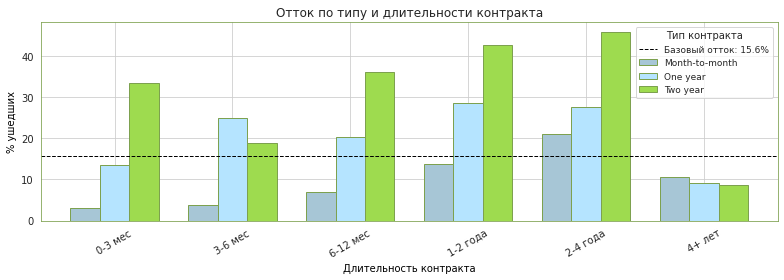

In [36]:
print("ОТТОК (%) ПО ТИПУ КОНТРАКТА × КОРЗИНА ДЛИТЕЛЬНОСТИ КОНТРАКТА:")
print("=" * 75)
print(cross_type_tenure.to_string())
print("=" * 75)

# Визуализация
fig, ax = plt.subplots(figsize=(11, 4))
cross_type_tenure.T.plot(kind='bar', ax=ax,
                          color=[COLORS['pink'], COLORS['blue'], COLORS['green_light']],
                          edgecolor=COLORS['green_dark'], width=0.75)
ax.axhline(CHURN_BASE, color=COLORS['black'], linestyle='--',
           linewidth=1, label=f'Базовый отток: {CHURN_BASE:.1f}%')
ax.set_title('Отток по типу и длительности контракта')
ax.set_ylabel('% ушедших')
ax.set_xlabel('Длительность контракта')
ax.legend(title='Тип контракта', fontsize=9)
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">К О М М Е Н Т А Р И Й
    
---
    
<span style="color:#A7C6D6">
    
<span style="color:black">  Внутри каждой корзины `длительности контракта` отток различается по `типам контракта`:

- <span style="color:black"> `0-3 мес`: **Two year** - 33.3%, Month-to-month - 3.1%. Разница 30 п.п.
- <span style="color:black"> `1-2 года`: **Two year**- 42.7%, Month-to-month - 13.8%. Разница 28.9 п.п.
- <span style="color:black"> `2-4 года`: **Two year** - 46.5%, Month-to-month - 21.2%. Разница 25.3 п.п.
- <span style="color:black"> `4+ лет`: Two year - 9.4%, **Month-to-month** - 10.5%. Разница −1.1 п.п. - единственное исключение.

<span style="color:black"> При одной и той же `длительности контракта` **Two year** уходит в разы чаще, чем **Month-to-month**. Т.е. `type` не артефакт через `длительность контракта`. Связь сохраняется почти во всех корзинах-долгосрочные контракты уходят чаще, а не реже.

- <span style="color:black"> В корзине 4+ лет разница исчезает: **Month-to-month** (10.7%) и **Two year** (9.4%) уходят одинаково редко. Возможно, после 4х лет обслуживания тип контракта перестаёт быть важен -клиент привык и не уходит.

<div style="border-left: 2px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
#### Когда уходят клиенты
    
- Строим кривую: где по X - месяцы с начала договора, по Y - доля оставшихся клиентов.
    
<span style="color:#7DA14F">ВЫЯВЛЯЕМ

- Когда кривая падает быстрее всего - критическое окно удержания.
- Если резко в первые 3-6 мес - проблема с онбордингом.
- Если плавно - риск равномерный.

<span style="color:#7DA14F">Это даёт **операционный вывод** для бизнеса - когда предлагать промокоды и удержание. Не «сколько ушло», а «**когда** ушли».

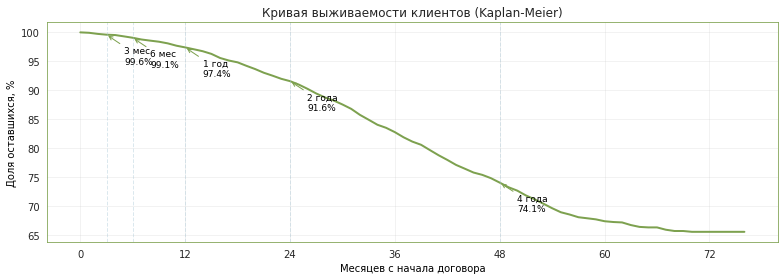


ПОТЕРИ ПО ИНТЕРВАЛАМ:
   до   3 мес: осталось  99.6%  (потери: 0.4 п.п.)
   до   6 мес: осталось  99.1%  (потери: 0.5 п.п.)
   до  12 мес: осталось  97.4%  (потери: 1.7 п.п.)
   до  24 мес: осталось  91.6%  (потери: 5.8 п.п.)
   до  48 мес: осталось  74.1%  (потери: 17.5 п.п.)


In [37]:
km_data = (df
    .groupby('tenure_months')
    .agg(at_risk=('customer_id', 'count'), events=('churn', 'sum'))
    .sort_index())

km_data['n_at_risk'] = km_data['at_risk'][::-1].cumsum()[::-1]
km_data['survival'] = (1 - km_data['events'] / km_data['n_at_risk']).cumprod()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(km_data.index, km_data['survival'] * 100,
        color=COLORS['green_dark'], linewidth=2)

# Ключевые точки
for m, label in [(3, '3 мес'), (6, '6 мес'), (12, '1 год'),
                 (24, '2 года'), (48, '4 года')]:
    if m in km_data.index:
        surv = km_data.loc[m, 'survival'] * 100
        ax.axvline(m, color=COLORS['pink'], linestyle='--',
                   alpha=0.4, linewidth=1)
        ax.annotate(f'{label}\n{surv:.1f}%',
                    xy=(m, surv), xytext=(m + 2, surv - 5),
                    fontsize=9, color=COLORS['black'],
                    arrowprops=dict(arrowstyle='->',
                                    color=COLORS['green_dark'],
                                    lw=1))

ax.set_title('Кривая выживаемости клиентов (Kaplan-Meier)')
ax.set_xlabel('Месяцев с начала договора')
ax.set_ylabel('Доля оставшихся, %')
ax.set_xticks(range(0, 80, 12))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nПОТЕРИ ПО ИНТЕРВАЛАМ:")
print("=" * 55)
prev = 100
for m in [3, 6, 12, 24, 48, 77]:
    if m in km_data.index:
        surv = km_data.loc[m, 'survival'] * 100
        loss = prev - surv
        print(f"   до {m:>3} мес: осталось {surv:5.1f}%  "
              f"(потери: {loss:.1f} п.п.)")
        prev = surv

<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">К О М М Е Н Т А Р И Й

---

<span style="color:#7DA14F">Кривая выживаемости показывает: клиенты уходят **плавно**, но **неравномерно**. Резких обвалов нет - но и равномерным отток не назвать.

<span style="color:#7DA14F">**ТРИ ФАЗЫ ЖИЗНЕННОГО ЦИКЛА:**

- **0-12 мес** Потери **2.6 п.п.** Новые клиенты лояльны, за первые полгода теряется меньше **1 п.п.**
- **1-4 года** Потери **22.5 п.п.** Это **критическое окно**: уходит каждый шестой. Именно здесь теряется **две трети** всех ушедших за весь срок.
- **4+ лет** Потери **9.2 п.п.** Отток **замедляется**, но **не прекращается**.

**ПИК СКОРОСТИ ОТТОКА - 24-48 МЕСЯЦЕВ.** 0.70 п.п./мес -это **в 5.4 раза быстрее**, чем в первые 3 месяца. Если в начале клиент почти не уходит, то на 2-4 годах он уходит **как только появляется возможность**.

---

**ЭТО ПОДТВЕРЖДАЕТ ВЫВОДЫ 3.4.4 И 3.4.2:**

1. **Связь с 3.4.4 (тип и длительность контракта).** В кросс-таблице `type × tenure_bin` пик оттока - **2-4 года**: у `Month-to-month` - 21.2%, у `One year` - 28.1%, у **`Two year` аж 46.5%**. 
    
- Кривая выживаемости показывает **то же самое**: максимальная скорость потерь - на интервале 24-48 месяцев. Два независимых анализа дают **один и тот же результат** - похоже на закономерность.

2. **Связь с 3.4.2 (`charges_dynamics`).** Клиенты, которые **не меняли тариф** (`stable`), уходят чаще базового - 16.5% против 15.6%. А в комбинации с **`Two year` - **25.3%** аж каждый четвёртый**. 
    
- Это значит: **отсутствие обновлений тарифа ведёт к оттоку** на 2-4 годах. Клиент скорее всего уходит к конкуренту.

---

<span style="color:#7DA14F">**ОБЩИЙ ВЫВОД:**

1. **За первые 6 месяцев теряется меньше 1 п.п.** - это отлично. Новые клиенты довольны и остаются.

2. **Проблема - средний срок.** Критическое окно - **2-4 года**. За этот период уходит каждый шестой (17.5 п.п.) - почти половина всех потерь за весь срок.

3. **Отток ускоряется, потом замедляется.** Скорость потерь растёт с 0.13 п.п./мес (0-3 мес) до 0.70 п.п./мес (24-48 мес) - **в 5.4 раза**, а затем падает. Клиенты, дожившие до 4 лет, более лояльны.

4. **Вывод подтверждается двумя анализами.** Кросс-таблица `type × tenure_bin` (3.4.4) и анализ `charges_dynamics` (3.4.2) дают **тот же результат**: пик оттока 2-4 года, самая рискованная группа `stable + Two year`.

5. **Бизнес-вывод.** Удержание нужно фокусировать на клиентах с длительностью контракта **1-4 года**, особенно `Two year` с неизменным тарифом. Чтобы не провацировать отток клиентов тарифы стоит обновлять чаще, чтобы они были конкурентноспособны.

<div style="background-color: #FDFFFA; border: 4px solid #7DA14F; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

#### <span style="color:#7DA14F"> в ы в о д

---

<span style="color:#A7C6D6">**БАЗОВЫЙ ОТТОК - 15.6%** (1101 ушедших из 7043). Если в категории отток выше - это зона риска.

---

<span style="color:#A7C6D6">**ТОП-5 САМЫХ СИЛЬНЫХ ПРИЗНАКОВ ПО ОТТОКУ**

| Признак | Категория | Отток | Разница с базой |
|---|---|---|---|
| **`multiple_lines`** | `Yes` | **22.8%** | +7.2 п.п. |
| **`type`** | `Two year` | **22.5%** | +6.9 п.п. |
| **`streaming_movies`** | `Yes` | **22.2%** | +6.6 п.п. |
| **`partner`** | `Yes` | **21.1%** | +5.5 п.п. |
| **`online_backup`** | `Yes` | **23.1%** | +7.5 п.п. |

**Общий паттерн:** если допуслуги + долгосрочный контракт,то  **выше отток**.

---

<span style="color:#A7C6D6">**ЧИСЛОВЫЕ ПРИЗНАКИ**

- **`monthly_charges`:** у ушедших **75.55**, у оставшихся **62.76** (**+20.4%**).
- **`total_charges`:** у ушедших **2371**, у оставшихся **2068** (**+14.7%**).
- **`tenure_months`:** **+3.6%** - слабоват, возможно полезен **в комбинации**.
- **`avg_monthly`:** у ушедших **77.66**, у оставшихся **64.49** (**+20.4%**).

**Вывод:** Если дорогой тариф,то выше риск ухода.

---

<span style="color:#A7C6D6">**Q4 - САМАЯ ЦЕННАЯ И РИСКОВАННАЯ ГРУППА**

- **1761 клиент (25%) = 49.1% всей выручки.**
- Отток в Q4 - **25.7%** (в 1.6 раза выше базового).
- Потери от ушедших Q4 - **1.49 млн у.е. (10.0% всей выручки)**.
- Средняя выручка клиента Q4 - **4150 у.е.** (в 2.9 раза выше обычных).

**Для бизнеса:** Q4 - **приоритет для удержания**.

---

<span style="color:#A7C6D6">**ГРУППА С ВЫСОКИМ УРОВНЕМ ОТТОКА - `stable` + Q4**

- Внутри Q4 группа **`stable` - 29.5% оттока** (максимум).
- **Разница с остальными 75% - +16.4 п.п.**
- Обычные клиенты `stable` - 13.1%. Дорогие - **29.5%**. Почти каждый третий.

**Причина:** Если дорогой клиент, который **не менял тариф**, не получает новых предложений, то уходит к конкурентам.

---

<span style="color:#A7C6D6">**КРИТИЧЕСКОЕ ОКНО - 2-4 ГОДА**

| Интервал | Потери |
|---|---|
| 0-12 мес | 2.6 п.п. |
| **1-4 года** | **22.5 п.п.**  (2/3 всех потерь) |
| 4+ лет | 9.2 п.п. |

- Пик скорости - **0.70 п.п./мес** на 24-48 мес (в 5.4 раза быстрее первых 3 мес).
- `Two year` + `stable` на 2-4 годах- **46.5% оттока** (почти каждый второй).

---

<span style="color:#A7C6D6">**БИЗНЕС-РЕКОМЕНДАЦИИ**

1. **Удерживать Q4- приоритет.** 25% клиентов = 49.1% выручки.
2. **Обновлять тарифы для `stable` + Q4** 29.5% оттока - самая опасная группа.
3. **Фокус на 1-4 годах.** Критическое окно - 2/3 потерь.
4. **Долгосрочные + автоплатёж + оптоволокно** - двойная зона риска.
5. **Для новичков** (0-6 мес) - достаточно стандартного онбординга (потери < 1 п.п.).

---

<span style="color:#A7C6D6">**ДЛЯ МОДЕЛИ**

- **Топ-признаки:** `tenure_days`, `total_charges`, `monthly_charges`, `type`, `partner`, `num_services`.
- **Phik занижает:** `type`, `charges_dynamics` - работают во взаимодействии.
- **Дисбаланс 1:5.4** — борется весами классов.
- **Целевая:** `churn` (15.6%).

<div style="border-left: 6px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
### <span style="color:#A7C6D6">Корреляционный анализ
    
---
    
<span style="color:#7DA14F">Проведём корреляционный анализ с помощью phik-корреляции. 
    
- Так как у нас **16 категориальных признаков и 5 числовых**, а phik даёт единую корректную матрицу для всех наших признаков датасета **без предварительного кодирования и масштабирования**. 
- Также может уловить **немонотонные зависимости**, и он устойчив к **асимметричным распределениям**. 
    
---
    
    
1. **Матрица полная** - показывает **реальную мультиколлинеарность** телеком-данных (пакетные подключения). 
    
- Все признаки, включая 7 допуслуг (`online_security`, `online_backup`, `device_protection`, `tech_support`, `streaming_tv`, `streaming_movies`, `multiple_lines`) + `internet_service`.

2. **Матрица агрегированная** - показывает **«чистую» картину связей** без пакетного шума. 
    
- Вместо 7 допуслуг + `internet_service` + `multiple_lines` оставляем только `num_services`.
    
---
    
*Структура признаков в данных:*

<span style="color:#7DA14F">К А Т Е Г О Р И А Л Ь Н Ы Е:

**Номинальные (неупорядоченные):**

- `type` - 3 категории (Month-to-month, One year, Two year)
- `payment_method` - 4 категории (Electronic check, Mailed check, Bank transfer, Credit card)
- `gender` - 2 категории (бинарный)
- `internet_service` - 3 категории (DSL, Fiber optic, No internet service)
- `charges_dynamics` - 5 категорий (recent_increase, recent_decrease, stable, old_increase, old_decrease)

**Бинарные:**

- `paperless_billing` - 2 категории (Yes / No)
- `senior_citizen` - 2 категории (0 / 1)
- `partner` - 2 категории (Yes / No)
- `dependents` - 2 категории (Yes / No)
- `online_security` - 2 категории (Yes / No / No internet service)
- `online_backup` - 2 категории (Yes / No / No internet service)
- `device_protection` - 2 категории (Yes / No / No internet service)
- `tech_support` - 2 категории (Yes / No / No internet service)
- `streaming_tv` - 2 категории (Yes / No / No internet service)
- `streaming_movies` - 2 категории (Yes / No / No internet service)
- `multiple_lines` - 3 категории (Yes / No / No phone service)

---

<span style="color:#7DA14F">К О Л И Ч Е С Т В Е Н Н Ы Е:

**Дискретные**

- `tenure_months` - 76 значений (0-76 мес), целочисленный
- `tenure_days`
- `num_services` - 9 значений (1–9), целочисленный
- `senior_citizen` - 2 значения (0 / 1), бинарный числовой

**Непрерывные**

- `monthly_charges` - правосторонняя асимметрия (медиана 70.35 > среднее 64.76), диапазон 18.25–118.75
- `total_charges` - правосторонняя асимметрия (медиана 1343 < среднее 2115), диапазон 19.05–9221.38
- `avg_monthly` - правосторонняя асимметрия (медиана 71.72 > среднее 65.99), диапазон 18.35–126.63

---

<span style="color:#7DA14F">ЦЕЛЕВАЯ ПЕРЕМЕННАЯ

- `churn` - бинарный (0 - остался, 1 - ушёл), дисбаланс 84.4% / 15.6%

---
    
Phik по умолчанию считает **все** признаки категориальными, включая числовые. Чтобы корректно обрабатывать непрерывные и дискретные числовые признаки, передаём их отдельным списком `interval_cols`.


- Без этого Phik посчитает `tenure_months` как категорию с 77 значениями, а `monthly_charges` - как категорию с 653 значениями - это исказит матрицу.

In [38]:
interval_cols = ['monthly_charges', 'total_charges', 'avg_monthly',
                 'tenure_months', 'num_services', 'tenure_days']

def _interpret(value):
    """Интерпретация силы Phik-связи."""
    if value == 1:
        return 'Целевой признак'
    if value < 0.3:
        return 'Слабая связь'
    if value < 0.7:
        return 'Умеренная'
    return 'Сильная'

In [39]:
def plot_phik_correlation(df, target_col, interval_cols=None,figsize=(14, 12), n_top=10):
    '''
    Phik-матрица корреляции с целевым признаком на первой позиции.
    Heatmap — нижний треугольник.
    '''
    
    # 1. Чистка: ID и утечки
    drop_cols = ['customer_id', 'tenure_bin', 'is_q4']
    df_clean = df.drop(columns=[c for c in drop_cols if c in df.columns])
    
    # 2. Дефолтные interval_cols
    interval_cols = interval_cols or ['monthly_charges', 'total_charges','avg_monthly', 'tenure_months']
    interval_cols = [c for c in interval_cols if c in df_clean.columns]
    
    # 3. Матрица + переупорядочивание (целевой на первое место)
    phik = df_clean.phik_matrix(interval_cols=interval_cols)
    order = [target_col] + [c for c in phik.columns if c != target_col]
    phik = phik.reindex(index=order, columns=order)
    
    # 4. Heatmap (нижний треугольник)
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(phik,
                mask=np.triu(np.ones_like(phik, dtype=bool), k=1),
                annot=True, fmt='.2f', cmap=PROJECT_CMAP, center=0,
                square=True, linewidths=0.5, linecolor='white',
                cbar_kws={'shrink': 0.8, 'label': 'Phik correlation'},
                annot_kws={'fontsize': 8}, ax=ax)
    
    ax.set_title(f'Phik Correlation Matrix (Целевой признак: {target_col})',
                 fontsize=15, pad=20, color=COLORS['black'])
    ax.set_xticklabels(ax.get_xticklabels(),rotation=45, ha='right', fontsize=9)
    ax.set_yticklabels(ax.get_yticklabels(),rotation=0, fontsize=9)
    ax.spines['top'].set_edgecolor(COLORS['green_dark'])
    ax.spines['bottom'].set_edgecolor(COLORS['green_dark'])
    ax.spines['left'].set_edgecolor(COLORS['green_dark'])
    ax.spines['right'].set_edgecolor(COLORS['green_dark'])
    plt.tight_layout()
    plt.show()
    
    # 5. Топ признаков по связи с целевой
    target_corr = phik[target_col].sort_values(ascending=False)
    corr_df = pd.DataFrame({
                            'Признак': target_corr.index[:n_top],
                            'Phik корреляция': target_corr.values[:n_top].round(4),
                            'Интерпретация': [_interpret(x) for x in target_corr.values[:n_top]]
                            })
    print(f"\nТоп-{n_top} признаков по корреляции с '{target_col}':")
    display(corr_df.style.background_gradient(cmap=PROJECT_CMAP,subset=['Phik корреляция']))
    
    # 6. Топ пар (без целевого) — через верхний треугольник
    features = [c for c in phik.columns if c != target_col]
    pairs_df = (phik.loc[features, features]
                    .where(~np.triu(np.ones((len(features), len(features)),dtype=bool), k=0))
                    .stack().reset_index())
    pairs_df.columns = ['Признак 1', 'Признак 2', 'Phik корреляция']
    pairs_df = (pairs_df
                .assign(Абсолютная=lambda d: d['Phik корреляция'].abs())
                .sort_values('Абсолютная', ascending=False)
                .head(n_top)
                .drop(columns='Абсолютная'))
    pairs_df['Интерпретация'] = pairs_df['Phik корреляция'].apply(_interpret)
    
    print(f"\nТоп-{n_top} пар признаков с наибольшей корреляцией (без '{target_col}'):")
    display(pairs_df.reset_index(drop=True)
                    .style.background_gradient(cmap=PROJECT_CMAP,subset=['Phik корреляция']))
    
    return

In [40]:
# Список услуг, которые убираем во второй матрице
service_cols = [
                'internet_service', # тип подключения
                'online_security',  # блокировка сайтов
                'online_backup',    # облачное хранилище
                'device_protection',# антивирус
                'tech_support',     # техподдержка
                'streaming_tv',     # стриминговое ТВ
                'streaming_movies', # каталог фильмов
                'multiple_lines'    # множественные линии
               ]

# Матрица 1 - полная (все признаки)
df_full = df.drop(columns=['customer_id', 'tenure_bin', 'is_q4']).copy()

# Матрица 2 - агрегированная (только num_services вместо 8 услуг)
df_agg = df.drop(columns=['customer_id', 'tenure_bin', 'is_q4'] + service_cols).copy()

# Проверка
print(f"Матрица 1 (полная):          {df_full.shape[1]} столбцов")
print(f"Матрица 2 (агрегированная):  {df_agg.shape[1]} столбцов")
print(f"\nУдалено во второй матрице:   {len(service_cols)} признаков")
print(f"Оставлен агрегат:            num_services")

Матрица 1 (полная):          23 столбцов
Матрица 2 (агрегированная):  15 столбцов

Удалено во второй матрице:   8 признаков
Оставлен агрегат:            num_services


<div style="border-left: 2px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
#### Матрица полная

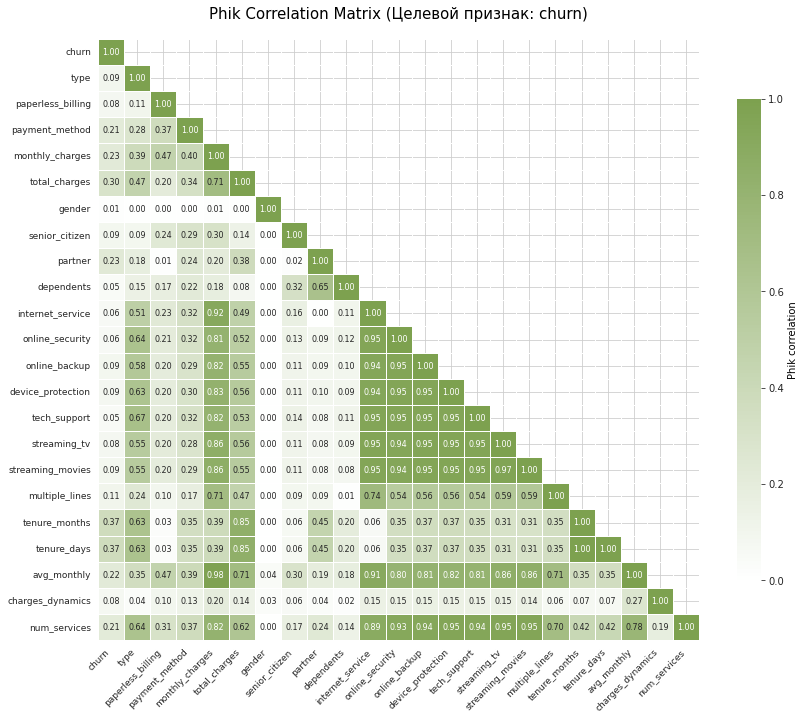


Топ-24 признаков по корреляции с 'churn':


,Признак,Phik корреляция,Интерпретация
0,churn,1.000000,Целевой признак
1,tenure_months,0.374600,Умеренная
2,tenure_days,0.374600,Умеренная
3,total_charges,0.304300,Умеренная
4,partner,0.226700,Слабая связь
5,monthly_charges,0.225900,Слабая связь
6,avg_monthly,0.223500,Слабая связь
7,payment_method,0.214800,Слабая связь
8,num_services,0.211400,Слабая связь
9,multiple_lines,0.105100,Слабая связь



Топ-24 пар признаков с наибольшей корреляцией (без 'churn'):


,Признак 1,Признак 2,Phik корреляция,Интерпретация
0,tenure_days,tenure_months,1.000000,Целевой признак
1,avg_monthly,monthly_charges,0.979342,Сильная
2,streaming_movies,streaming_tv,0.965306,Сильная
3,streaming_movies,device_protection,0.953717,Сильная
4,streaming_tv,device_protection,0.952863,Сильная
5,tech_support,online_security,0.952651,Сильная
6,tech_support,device_protection,0.950247,Сильная
7,num_services,streaming_movies,0.949574,Сильная
8,online_security,internet_service,0.949498,Сильная
9,num_services,streaming_tv,0.949112,Сильная


In [41]:
plot_phik_correlation(df=df_full, target_col='churn', interval_cols=interval_cols, figsize=(12, 10), n_top=24)

<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">**К О М М Е Н Т А Р И Й**

---

<span style="color:#A7C6D6">**1. Числовые признаки — сильнее всех**

- `tenure_months` (0.3746) и `tenure_days` (0.3746) - **дубликаты**(но мы это сделали намерено), одинаковый Phik. `total_charges` (0.3043) - третий. Первые два в «умеренной» зоне. Phik корректно улавливает связь длительности обслуживания с оттоком. Это подтверждает вывод о критическом окне 2-4 года.

<span style="color:#A7C6D6">**2. `partner` на 4-м месте (0.2267)**

- Phik показывает силу этого признака - **четвёртая позиция** после `tenure_months`/`tenure_days` и `total_charges`. С партнёром уходят 21.1%, без - 10.5%. Разница +10.6 п.п. - одна из самых больших среди персональных. Признак **недооценён в EDA** и возможно будет в числе важных признаков во feature importance.

<span style="color:#A7C6D6">**3. `num_services` (0.2114) - сильнее каждой услуги по отдельности**

- Агрегат `num_services` на 8-м месте - **выше всех отдельных услуг**: `multiple_lines` (0.1051), `online_backup` (0.0897), `streaming_movies` (0.0866), `device_protection` (0.0856), `streaming_tv` (0.0785), `online_security` (0.0587), `internet_service` (0.0566), `tech_support` (0.0515). Это **обосновывает агрегацию** услуг в один признак.

<span style="color:#A7C6D6">**4. `type` (0.0940) и `charges_dynamics` (0.0762) - занижены**

Phik измеряет **попарную** связь и не видит взаимодействий. Эти признаки работают **во взаимодействии**:

- `type` × `tenure_months`: пик оттока на 2–4 годах.
- `charges_dynamics` × `type`: `stable` + `Two year` = **25.3%**.
- `charges_dynamics` × `is_q4`: `stable` + Q4 = **29.5%**.

Phik не видит взаимодействий - это **ограничение метода**, а не проблема признаков. Финальную силу покажет **feature importance** из обученной модели.

<span style="color:#A7C6D6">**5. `gender` (0.0086) - можно удалить**

- Связи практически нет. Разница Male/Female всего +1.0 п.п. Признак не несёт информации, поэтому и является **кандидатом на удаление**.

<span style="color:#A7C6D6">**6. Топ-24 пар - почти полностью связи между услугами**

- 19 из 24 пар - это комбинации 7 допуслуг + `internet_service` + `num_services` с Phik **0.94-0.97**. Причина - **пакетные подключения** в телекоме: клиенты берут услуги вместе. Это **бизнес-логика**, а не случайная мультиколлинеарность.

<span style="color:#A7C6D6">**7. `monthly_charges` и `avg_monthly` (0.9793)**

- Практически одно и то же. Разница только в истории тарифа.

---

<span style="color:#7DA14F">**Что Phik занижает (из-за нелинейности)**

<span style="color:#A7C6D6">

- `type` (0.0940) - реальная разница в кросс-таблицах: **+12.0 п.п.** между `Two year` и `Month-to-month`.
- `charges_dynamics` (0.0762) - реальная разница: **+5.8 п.п.** между `stable` и `old_decrease`; во взаимодействиях с `type`/`is_q4` - до **+16.4 п.п.**
- `internet_service` (0.0566) - реальная разница: **+8.7 п.п.** между `Fiber optic` и `No internet service`.
- `multiple_lines` (0.1051) - реальная разница: **+13.4 п.п.** между `Yes` и `No` (максимум среди услуг).

---

<span style="color:#7DA14F">**ИТОГ**

<span style="color:#A7C6D6">

1. **Числовые признаки - сильнейшие.** `tenure_months` / `tenure_days` (0.3746) и `total_charges` (0.3043) - единственные в «умеренной» зоне.

2. **`partner` - недооценённый предиктор.** Четвёртая позиция (0.2267), не был в фокусе EDA.

3. **`num_services` (0.2114) сильнее, чем каждая услуга по отдельности.**

4. **19 из 24 пар - связи между услугами.** Пакетные подключения телекома. Для бустингов - не проблема.

5. **`gender` (0.0086) можно удалить.** Не несёт информации.

6. **`type` и `charges_dynamics` занижены.** Phik не видит взаимодействий - глянем на них в feature importance.

7. **`tenure_days` и `tenure_months` (1.0000) - дубликаты.** Оставить один - `tenure_days`.

<div style="border-left: 2px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
#### Матрица агрегированная

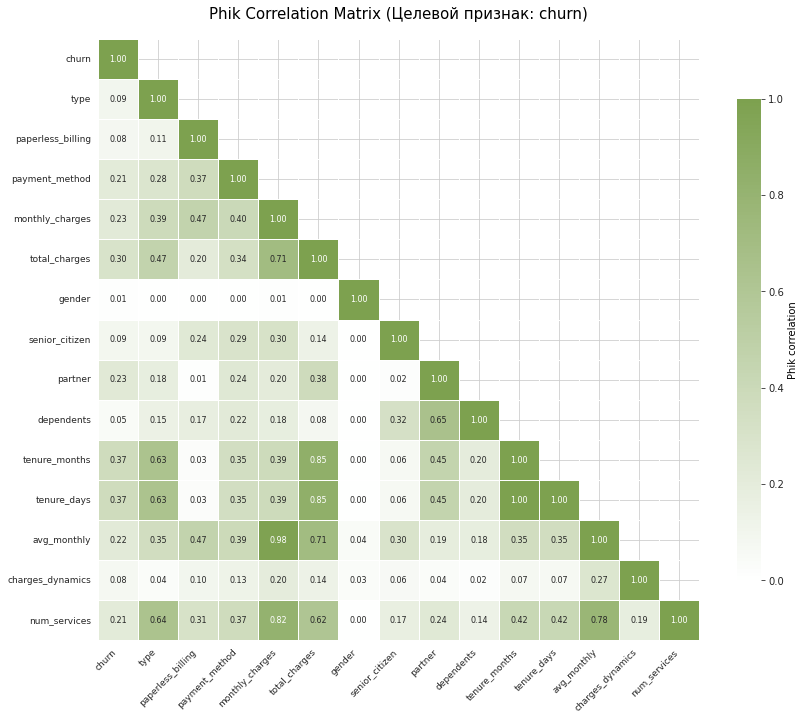


Топ-24 признаков по корреляции с 'churn':


,Признак,Phik корреляция,Интерпретация
0,churn,1.000000,Целевой признак
1,tenure_months,0.374600,Умеренная
2,tenure_days,0.374600,Умеренная
3,total_charges,0.304300,Умеренная
4,partner,0.226700,Слабая связь
5,monthly_charges,0.225900,Слабая связь
6,avg_monthly,0.223500,Слабая связь
7,payment_method,0.214800,Слабая связь
8,num_services,0.211400,Слабая связь
9,type,0.094000,Слабая связь



Топ-24 пар признаков с наибольшей корреляцией (без 'churn'):


,Признак 1,Признак 2,Phik корреляция,Интерпретация
0,tenure_days,tenure_months,1.000000,Целевой признак
1,avg_monthly,monthly_charges,0.979342,Сильная
2,tenure_days,total_charges,0.847414,Сильная
3,tenure_months,total_charges,0.847344,Сильная
4,num_services,monthly_charges,0.816217,Сильная
5,num_services,avg_monthly,0.780945,Сильная
6,avg_monthly,total_charges,0.714768,Сильная
7,total_charges,monthly_charges,0.711161,Сильная
8,dependents,partner,0.652122,Умеренная
9,num_services,type,0.635908,Умеренная


In [42]:
plot_phik_correlation(df=df_agg, target_col='churn', interval_cols=interval_cols, figsize=(12, 10), n_top=24)

<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">**К О М М Е Н Т А Р И Й**

---

<span style="color:#A7C6D6">**1. Топ-признаков с `churn` - не изменился**

- `num_services` (0.2114) остался на **8-м месте**, заменив собой 8 удалённых услуг. Агрегация не потеряла сигнал — наоборот, сконцентрировала его в одном признаке.

<span style="color:#A7C6D6">**2. Все 19 пар услуг - исчезли**

- Удаление 8 признаков убрало весь «шум» пакетных подключений. Это **подтверждает гипотезу**: 19 из 24 пар в полной матрице были связями между услугами.

<span style="color:#A7C6D6">**3. Остались только логические пары**

Топ пар в агрегированной матрице - это **осмысленные зависимости**:

- `avg_monthly` и `monthly_charges` (**0.979**): `avg_monthly = total_charges / tenure_months`, фактически дубликат - можно удалить один
- `tenure_days` и `total_charges` (**0.847**): чем больше длительность обслуживания, тем выше общий расход
- `tenure_months` и `total_charges` (**0.847**): то же самое
- `num_services` и `monthly_charges` (**0.816**): чем больше услуг, тем выше расход за последний месяц
- `num_services` и `avg_monthly` (**0.781**): то же самое - больше услуг выше средний чек
- `avg_monthly` и `total_charges` (**0.715**): агрегатная связь
- `total_charges` и `monthly_charges` (**0.711**): `total_charges = monthly_charges × tenure_months`, агрегатная связь
- `dependents` и `partner` (**0.652**): семейные связи
- `num_services` и `type` (**0.636**): долгосрочные контракты - больше подключённых услуг
- `tenure_months` и `type` (**0.634**): долгосрочные контракты - большая длительность контракта
- `tenure_days` и `type` (**0.634**): то же самое
- `num_services` и `total_charges` (**0.616**): больше услуг - выше накопленный расход

<span style="color:#A7C6D6">**4. `num_services` коррелирует со всем**

- `monthly_charges` (0.816), `avg_monthly` (0.781), `total_charges` (0.616).
- `type` (0.636), `tenure_months` (0.417), `tenure_days` (0.417).
- `payment_method` (0.374), `paperless_billing` (0.307).

Это **ожидаемо**: `num_services` - агрегат от всех услуг, и он связан с тарифом, типом контракта, длительностью контракта. **Но с `churn` он связан напрямую (0.2114)** - это не артефакт корреляций, а самостоятельный предиктор.

<span style="color:#A7C6D6">**5. `type` - `num_services` (0.636) и `type` - `tenure_months` (0.634)**

- Долгосрочные контракты (`One year`, `Two year`) → больше услуг и больше длительность контракта абонента. Это **логическая связь**: клиент на долгосрочном контракте успел накопить и услуги, и длительность контракта увеличить.

<span style="color:#A7C6D6">**6. `charges_dynamics` - `tenure_months` (0.646 в полной матрице)**

- Динамика тарифа зависит от длительности контракта абонента. Новые клиенты не успели сменить тариф - `stable` и `recent_decrease` доминируют у новичков. У давних клиентов больше `old_decrease` и `old_increase`.

<span style="color:#A7C6D6">**7. `gender` (0.0086) — подтверждён как шум**

- В агрегированной матрице `gender` **не коррелирует ни с чем** - все значения 0.000-0.034. Признак можно **удалить без потерь**.

---

<span style="color:#A7C6D6">**ВАЖНО:** 
    
- `num_services` (0.2114) **заменяет** 8 удалённых признаков (их индивидуальные Phik 0.05–0.11). Агрегат **сильнее** каждого из них и **корректно** работает как самостоятельный предиктор.

<span style="color:#A7C6D6">**УДАЛИМ:**

- `gender` (0.0086 с `churn`, 0.000 со всеми) - шум.
- `tenure_days` (1.0000 с `tenure_months`) - дубликат, оставить один.

---

<div style="background-color: #FDFFFA; border: 4px solid #7DA14F; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

#### <span style="color:#7DA14F"> в ы в о д

---

<span style="color:#A7C6D6">**Phik-корреляция* для смешанных данных (16 категориальных + 6 числовых). Даёт единую матрицу без кодирования, улавливает немонотонные связи, устойчива к асимметрии.

---

<span style="color:#A7C6D6">**ТОП-ПРИЗНАКОВ С `churn`**

| Признак | Phik |
|---|---|
| `tenure_days` | **0.3746** |
| `total_charges` | **0.3043** |
| `partner` | 0.2267 |
| `monthly_charges` | 0.2259 |
| `avg_monthly` | 0.2235 |
| `payment_method` | 0.2148 |
| `num_services` | **0.2114** |

---

<span style="color:#A7C6D6">**КЛЮЧЕВЫЕ ИНСАЙТЫ**

1. **Числовые - сильнейшие.** `tenure_days` и `total_charges` - единственные в «умеренной» зоне.

2. **`partner` - недооценённый предиктор.** 4-е место (0.2267), не был в фокусе EDA.

3. **`num_services` (0.2114) сильнее каждой услуги.** Агрегат заменяет 8 признаков (их Phik 0.05-0.11). Обосновывает агрегацию.

4. **19 из 24 пар - связи между услугами.** Пакетные подключения телекома. Для бустингов - не проблема.

5. **`type` и `charges_dynamics` занижены.** Phik не видит взаимодействий (`stable` + `Two year` = 25.3%, `stable` + Q4 = 29.5%).

6. **`gender` (0.0086) — шум.** Удалим.

---

<div style="border-left: 6px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
### <span style="color:#A7C6D6">Подготовка данных для обучения
    
---   
    
<span style="color:#7DA14F">
    
1. <span style="color:black">Готовим **два датасета** для двух пайплайнов - по аналогии с двумя корреляционными матрицами:

- <span style="color:black">**`df_full`** - с допуслугами (7 услуг + `internet_service` + `multiple_lines`).
- <span style="color:black">**`df_agg`** - без допуслуг, только агрегат `num_services`.   
    
<span style="color:#7DA14F">ИСКЛЮЧАЕМ В ОБОИХ ДАТАСЕТАХ

- <span style="color:black">`customer_id`: так как это идентификатор
- <span style="color:black">`tenure_bin`: производная `tenure_months` - утечка
- <span style="color:black">`is_q4`: производная `avg_monthly` - утечка
- <span style="color:black">`gender`: Phik 0.009 - незначительная связь
- <span style="color:black">`avg_monthly`: очень сильно коррелирует с `monthly_charges`. Также он был вспомогательным, в модели он не требуется
  
2. <span style="color:black">Разделение данных на тренировочную и тестовую выборки    
    
---

In [43]:
# Общие исключения для обоих датасетов
drop_common = ['customer_id', 'tenure_bin', 'is_q4', 'gender', 'avg_monthly', 'tenure_months'] # total_charges
# Исключаем только для df_full
drop_num =['num_services']
# Услуги, которые убираем для df_agg
service_cols = [
                'internet_service', 'online_security', 'online_backup','device_protection', 
                'tech_support', 'streaming_tv', 'streaming_movies', 'multiple_lines'
                ]

<div style="border-left: 2px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
#### Создание двух датасетов **`df_full`** и **`df_agg`**

In [44]:
# Датасет полный
df_full = df.drop(columns=drop_common + drop_num).copy()

# Датасет агрегированный
df_agg = df.drop(columns=drop_common + service_cols).copy()

print(f"df_full: {df_full.shape[1]-1} признаков + churn")
print(f"df_agg:  {df_agg.shape[1]-1} признаков + churn")

df_full: 18 признаков + churn
df_agg:  11 признаков + churn


<div style="border-left: 2px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
#### Разделение данных

In [45]:
def split_xy(df_model):
    """Разделяет датафрейм на X, y + списки колонок."""
    X = df_model.drop(columns='churn')
    y = df_model['churn']
    
    # Явно указываем бинарные числовые как категориальные
    binary_cat_cols = ['senior_citizen']
    
    cat_cols = X.select_dtypes(include='object').columns.tolist()
    cat_cols += binary_cat_cols
    
    # Числовые — все остальные
    num_cols = [c for c in X.select_dtypes(include=['int64', 'float64']).columns
                if c not in binary_cat_cols]
    
    return X, y, cat_cols, num_cols
# df_full
X_full, y_full, cat_full, num_full = split_xy(df_full)
X_full_train, X_full_test, y_full_train, y_full_test = train_test_split(
                                                                        X_full, y_full, test_size=0.25, 
                                                                        random_state=RANDOM_STATE, stratify=y_full
                                                                        )

# df_agg
X_agg, y_agg, cat_agg, num_agg = split_xy(df_agg)
X_agg_train, X_agg_test, y_agg_train, y_agg_test = train_test_split(
                                                                    X_agg, y_agg, test_size=0.25, 
                                                                    random_state=RANDOM_STATE, stratify=y_agg
                                                                    )

# Кросс-валидация
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Проверка размерности
print(f"df_full: X_train {X_full_train.shape}| y_train {y_full_train.shape} | X_test {X_full_test.shape} | y_test {y_full_test.shape}")
print(f"df_agg:  X_train {X_agg_train.shape}| y_train {y_agg_train.shape}  | X_test {X_agg_test.shape} | y_test {y_agg_test.shape}")

df_full: X_train (5282, 18)| y_train (5282,) | X_test (1761, 18) | y_test (1761,)
df_agg:  X_train (5282, 11)| y_train (5282,)  | X_test (1761, 11) | y_test (1761,)


ПРОВЕРКА БАЛАНСА КЛАССОВ:


,Выборка,Всего,Остались (0),Ушли (1),"Отток, %"
0,df_full train,5282,4456,826,15.640000
1,df_full test,1761,1486,275,15.620000
2,df_agg train,5282,4456,826,15.640000
3,df_agg test,1761,1486,275,15.620000


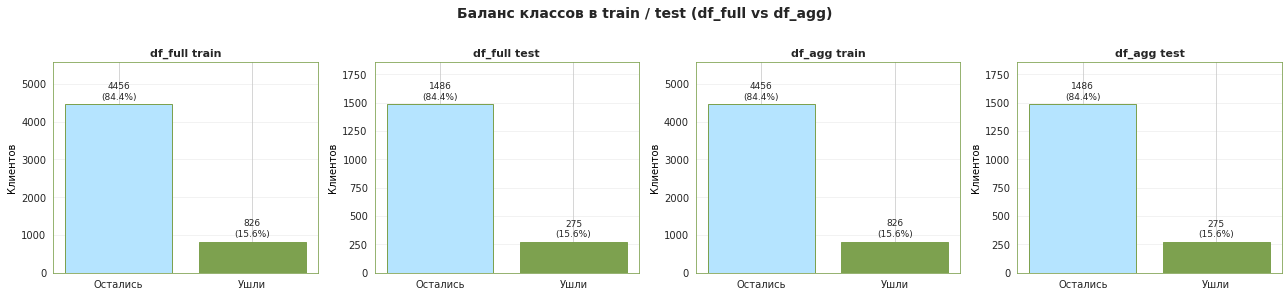

In [46]:
# Собираем все 4 выборки в один список
datasets = [
            ('df_full train', y_full_train),
            ('df_full test',  y_full_test),
            ('df_agg train',  y_agg_train),
            ('df_agg test',   y_agg_test),
            ]

# Собираем статистику по каждому датасету
rows = []
for name, y_data in datasets:
    counts = y_data.value_counts().sort_index()
    total = len(y_data)
    n_0 = counts.get(0, 0)
    n_1 = counts.get(1, 0)
    rows.append({
                'Выборка':      name,
                'Всего':        total,
                'Остались (0)': n_0,
                'Ушли (1)':     n_1,
                'Отток, %':     round(n_1 / total * 100, 2),
                 })

balance_check = pd.DataFrame(rows)

# Таблица
print("ПРОВЕРКА БАЛАНСА КЛАССОВ:")
print("=" * 70)
display(balance_check.style.background_gradient(cmap=PROJECT_CMAP, subset=['Отток, %']))

# Визуализация
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, (name, y_data) in zip(axes, datasets):
    counts = y_data.value_counts().sort_index()
    pct = (counts / counts.sum() * 100).round(1)
    
    bars = ax.bar(['Остались', 'Ушли'], counts.values,
                  color=[COLORS['blue'], COLORS['green_dark']],
                  edgecolor=COLORS['green_dark'])
    
    for bar, v, p in zip(bars, counts.values, pct.values):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + counts.max() * 0.03,
                f'{v}\n({p}%)', ha='center', fontsize=9)
    
    ax.set_title(name, fontsize=11, fontweight='bold')
    ax.set_ylabel('Клиентов')
    ax.set_ylim(0, counts.max() * 1.25)
    ax.grid(alpha=0.3, axis='y')

plt.suptitle('Баланс классов в train / test (df_full vs df_agg)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">К О М М Е Н Т А Р И Й
    
---
    
<span style="color:#A7C6D6">
    
- <span style="color:black"> Пропорции классов **совпадают** во всех четырёх выборках - 15.6% / 84.4%.
- <span style="color:black">  Стратификация сработала корректно - пропорции классов сохранены.
- <span style="color:black">  `df_full` и `df_agg` содержат **одних и тех же клиентов**, различаются только признаки. Поэтому цифры идентичны.
- <span style="color:black">  Дисбаланс **1:5.4** - не критичный. Боремся **весами классов внутри моделей**, без SMOTE и undersampling.

In [47]:
def show_columns_split(cat_cols, num_cols, dataset_name):
    """Показывает, какие колонки в каком блоке препроцессора с разделением на два разных датасета."""
    # Все категориальные - OHE
    ohe_cols = cat_cols
    
    print("=" * 70)
    print(f"РАЗДЕЛЕНИЕ КОЛОНОК: {dataset_name}")
    print("=" * 70)
    print(f"  Всего признаков:  {len(cat_cols) + len(num_cols)}")
    print(f"  Категориальных:   {len(cat_cols)}")
    print(f"  Числовых:         {len(num_cols)}")
    
    print(f"\n  OHE ({len(ohe_cols)}):")
    for c in ohe_cols:
        print(f"    • {c}")
    
    print(f"\n  NUM ({len(num_cols)}):")
    for c in num_cols:
        print(f"    • {c}")
    print()


# df_full
show_columns_split(cat_full, num_full, 'df_full')

# df_agg
show_columns_split(cat_agg, num_agg, 'df_agg')

РАЗДЕЛЕНИЕ КОЛОНОК: df_full
  Всего признаков:  18
  Категориальных:   15
  Числовых:         3

  OHE (15):
    • type
    • paperless_billing
    • payment_method
    • partner
    • dependents
    • internet_service
    • online_security
    • online_backup
    • device_protection
    • tech_support
    • streaming_tv
    • streaming_movies
    • multiple_lines
    • charges_dynamics
    • senior_citizen

  NUM (3):
    • monthly_charges
    • total_charges
    • tenure_days

РАЗДЕЛЕНИЕ КОЛОНОК: df_agg
  Всего признаков:  11
  Категориальных:   7
  Числовых:         4

  OHE (7):
    • type
    • paperless_billing
    • payment_method
    • partner
    • dependents
    • charges_dynamics
    • senior_citizen

  NUM (4):
    • monthly_charges
    • total_charges
    • tenure_days
    • num_services



In [48]:
def make_preprocessor(cat_cols, num_cols, scale_numeric=False):
    """
    Препроцессор:
    Все категориальные - OHE.
    scale_numeric=False - RandomForest (passthrough)
    scale_numeric=True  - MLP (StandardScaler)
    """
    num_transformer = StandardScaler() if scale_numeric else 'passthrough'
    
    return ColumnTransformer([
                                ('ohe', OneHotEncoder(drop='first', #handle_unknown='ignore',
                                                      sparse=False), cat_cols),
                                ('num', num_transformer, num_cols),
                             ])


# 4 препроцессора (2 датасета * 2 модели)
preprocessors = {
                'full_rf':  make_preprocessor(cat_full, num_full, scale_numeric=False),
                'full_mlp': make_preprocessor(cat_full, num_full, scale_numeric=True),
                'agg_rf':   make_preprocessor(cat_agg,  num_agg,  scale_numeric=False),
                'agg_mlp':  make_preprocessor(cat_agg,  num_agg,  scale_numeric=True),
                }

# CatBoost - без препроцессора, только индексы категорий
cat_idx_full = [X_full.columns.get_loc(c) for c in cat_full]
cat_idx_agg  = [X_agg.columns.get_loc(c)  for c in cat_agg]


# Проверка
print("=" * 120)
print("ПРЕПРОЦЕССОРЫ (4 шт.)")
print("=" * 120)
for name, prep in preprocessors.items():
    dataset, model = name.rsplit('_', 1)
    cat_count = len(cat_full) if dataset == 'full' else len(cat_agg)
    num_count = len(num_full) if dataset == 'full' else len(num_agg)
    scaling = 'StandardScaler' if model == 'mlp' else 'passthrough'
    print(f"  • {name:<10} | датасет: {dataset:<5} | "
          f"кат: {cat_count:<2} | числ: {num_count:<2} | масштаб: {scaling}")


# OHE-колонки по датасетам (все категориальные)
print(f"\nOHE для df_full ({len(cat_full)}): {cat_full}")
print(f"OHE для df_agg  ({len(cat_agg)}):  {cat_agg}")

print(f"\nCATBOOST — индексы категорий:")
print(f"  • full: {cat_idx_full}")
print(f"  • agg:  {cat_idx_agg}")


# Проверка на данных
print("\n" + "=" * 120)
print("ПРОВЕРКА НА TRAIN/TEST")
print("=" * 120)

check = [
        ('full_rf',  X_full_train, X_full_test),
        ('full_mlp', X_full_train, X_full_test),
        ('agg_rf',   X_agg_train,  X_agg_test),
        ('agg_mlp',  X_agg_train,  X_agg_test),
        ]

for name, X_tr, X_te in check:
    X_tr_prep = preprocessors[name].fit_transform(X_tr)
    X_te_prep = preprocessors[name].transform(X_te)
    print(f"  {name:<10}: train {X_tr.shape} → {X_tr_prep.shape} | "
          f"test {X_te.shape} → {X_te_prep.shape}")

ПРЕПРОЦЕССОРЫ (4 шт.)
  • full_rf    | датасет: full  | кат: 15 | числ: 3  | масштаб: passthrough
  • full_mlp   | датасет: full  | кат: 15 | числ: 3  | масштаб: StandardScaler
  • agg_rf     | датасет: agg   | кат: 7  | числ: 4  | масштаб: passthrough
  • agg_mlp    | датасет: agg   | кат: 7  | числ: 4  | масштаб: StandardScaler

OHE для df_full (15): ['type', 'paperless_billing', 'payment_method', 'partner', 'dependents', 'internet_service', 'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies', 'multiple_lines', 'charges_dynamics', 'senior_citizen']
OHE для df_agg  (7):  ['type', 'paperless_billing', 'payment_method', 'partner', 'dependents', 'charges_dynamics', 'senior_citizen']

CATBOOST — индексы категорий:
  • full: [0, 1, 2, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 17, 5]
  • agg:  [0, 1, 2, 6, 7, 9, 5]

ПРОВЕРКА НА TRAIN/TEST
  full_rf   : train (5282, 18) → (5282, 31) | test (1761, 18) → (1761, 31)
  full_mlp  : train (5282, 18

In [49]:
# Проверка корректности индексов CatBoost
print("ПРОВЕРКА ИНДЕКСОВ CATBOOST:")
print("=" * 125)

for name, X, idx in [('full', X_full, cat_idx_full),
                     ('agg',  X_agg,  cat_idx_agg)]:
    cols_at_idx = [X.columns[i] for i in idx]
    is_valid = cols_at_idx == list(X.columns[idx])  # sanity check
    print(f"\n  {name}:")
    print(f"    Индексы: {idx}")
    print(f"    Колонки по индексам: {cols_at_idx}")
    print(f"    Совпадают с cat_cols: "
          f"{'Да' if cols_at_idx == (cat_full if name=='full' else cat_agg) else 'Нет'}")

ПРОВЕРКА ИНДЕКСОВ CATBOOST:

  full:
    Индексы: [0, 1, 2, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 17, 5]
    Колонки по индексам: ['type', 'paperless_billing', 'payment_method', 'partner', 'dependents', 'internet_service', 'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies', 'multiple_lines', 'charges_dynamics', 'senior_citizen']
    Совпадают с cat_cols: Да

  agg:
    Индексы: [0, 1, 2, 6, 7, 9, 5]
    Колонки по индексам: ['type', 'paperless_billing', 'payment_method', 'partner', 'dependents', 'charges_dynamics', 'senior_citizen']
    Совпадают с cat_cols: Да


<div style="background-color: #FDFFFA; border: 4px solid #7DA14F; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

#### <span style="color:#7DA14F"> в ы в о д

---

<span style="color:#A7C6D6">**ДВА ДАТАСЕТА - ДВЕ ГИПОТЕЗЫ**

| | `df_full` | `df_agg` |
|---|---|---|
| **Признаков** | 18 | 11 |
| **Состав** | Все услуги + `internet_service` + `multiple_lines` | Только `num_services` |
| **Цель** | Нужны ли отдельные услуги? | Достаточно ли агрегата? |

---

<span style="color:#A7C6D6">**ИСКЛЮЧЕНО 6 ПРИЗНАКОВ**

- `customer_id` - ID.
- `tenure_bin`, `is_q4` - производные, утечка.
- `gender` - шум (Phik 0.009).
- `avg_monthly` - дубликат `monthly_charges` (Phik 0.979).
- `tenure_months` - дубликат `tenure_days` (Phik 1.0000). Оставлен `tenure_days` (точнее).

---

<span style="color:#A7C6D6">**РАЗДЕЛЕНИЕ TRAIN / TEST**

| Выборка | Клиентов | Отток |
|---|---|---|
| `df_full` train | 5282 (75%) | **15.64%** |
| `df_full` test | 1761 (25%) | **15.62%** |
| `df_agg` train | 5282 (75%) | **15.64%** |
| `df_agg` test | 1761 (25%) | **15.62%** |

- **Стратификация сработала** - пропорции сохранены.
- **Дисбаланс 1:5.4** - не критичный.
- **Борьба:** веса классов внутри моделей, без SMOTE.

---

<span style="color:#A7C6D6">**ПРЕПРОЦЕССОРЫ (4 шт.)**

| Препроцессор | Датасет | Модель | Масштаб |
|---|---|---|---|
| `full_rf` | `df_full` | RandomForest | passthrough |
| `full_mlp` | `df_full` | MLP | StandardScaler |
| `agg_rf` | `df_agg` | RandomForest | passthrough |
| `agg_mlp` | `df_agg` | MLP | StandardScaler |

**CatBoost** — без препроцессора, категории нативно через `cat_idx`.

---

<span style="color:#A7C6D6">**КОДИРОВАНИЕ И МАСШТАБИРОВАНИЕ**

- **Все категориальные - OHE**.
- **Числовые - `passthrough`** (деревья/бустинги) или **`StandardScaler`** (MLP).
- **`senior_citizen`** - добавлен в `cat_cols` явно (бинарный категориальный).
- **CatBoost** получает **индексы** `cat_idx_full` (15) / `cat_idx_agg` (7).

---

<span style="color:#A7C6D6">**РЕЗУЛЬТАТ**

- `full_rf`: 18. **31 признак** (после OHE).
- `agg_rf`: 11. **16 признаков** (после OHE).
- Train и test **одинаковые размерности** - препроцессоры работают корректно.
- `cat_idx_full`/`cat_idx_agg` **совпадают с `cat_cols`** - CatBoost получит правильные категории.

---

<span style="color:#A7C6D6">**ДАЛЕЕ**

- 6 экспериментов: **2 датасета × 3 модели** (RandomForest, CatBoost, Keras MLP).
- Метрика: **ROC-AUC** (устойчива к дисбалансу).
- Гиперпараметры: **GridSearchCV**.

---

<div style="background-color: white; border: 4px solid #7DA14F; border-radius: 3px; padding: 15px 25px; display: inline-block; color: black;">

## <span style="color:#9EDB4F"> Обучение моделей

---

<span style="color:#A7C6D6">Построим **один общий пайплайн**, в котором будем перебирать четыре уровня:

1. **Датасет**:  `df_full  |  df_agg`
2. **Препроцессоры**:  
 
| Датасет | Модель | Препроцессор |
|---|---|---|
| `df_full` | RandomForest | OHE+passthrough |
| `df_full` | CatBoost | нативно, `cat_idx_full` |
| `df_full` | MLP | OHE+StandardScaler |
| `df_agg` | RandomForest | OHE+passthrough |
| `df_agg` | CatBoost | нативно, `cat_idx_agg` |
| `df_agg` | MLP | OHE+StandardScaler |

**Итого 6 экспериментов** (2 датасета × 3 модели).
    
3. **Модель**:  ` RandomForest | CatBoost | MLP`
4. **Гиперпараметры**:  `перебор по сетке` 
    
---

<span style="color:#A7C6D6">ПРЕПРОЦЕССОР ДЛЯ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ
    
- Используем `OHE`. 
- Для CatBoost не нужно кодирование
    
<span style="color:#A7C6D6">МАСШТАБИРОВАНИЕ ДЛЯ ЧИСЛОВЫХ ПРИЗНАОВ    
    
- Используем StandardScaler для MLP     
- Для остальных моделей (`RandomForest, CatBoost`) не нужно масштабирование
    
---
    
Так мы получим ответы:
    
- какой датасет лучше (нужны ли отдельные услуги или достаточно `num_services`);
- какой препроцессор лучше для каждой модели;
- какая модель даёт лучший ROC-AUC.
     
---
    
**Над дисбалансом классов мы поработаем в самих моделях** (он не критичный:`1:5.4`).Модели с весами классов (особенно бустинги) отлично справляются с таким дисбалансом и без синтеза данных.
 
- Если мы синтезируем примеры (SMOTE) или выкинем 84% оставшихся (undersampling), мы исказим реальность (SMOTE создаст «фейковых» ушедших, которых не существует. А Undersampling потеряет 84% информации о том, как ведут себя лояльные клиенты)
- Данные смешанные - 14 категориальных из 19 в `df_full`, 6 из 11 в `df_agg`. А SMOTE для категориальных признаков работает плохо 
- Метрика ROC-AUC устойчива к дисбалансу.
    
---
    
<span style="color:#A7C6D6">
    
СТРУКТУРА РАЗДЕЛА
    
- **4.1** <span style="color:black"> KerasMLPClassifier `[класс нейросети]`
- **4.2** <span style="color:black">  CatBoostWrapper `[обёртка CatBoost]`
- **4.3** <span style="color:black">  PassthroughTransformer `[заглушка + пайплайны]`
- **4.4** <span style="color:black">  evaluate_and_show `[единая функция оценки]`
- **4.5** <span style="color:black">  param_grid_full + search_full `[обучение на df_full]`
- **4.6** <span style="color:black">  param_grid_agg + search_agg `[обучение на df_agg]`
- **4.7** <span style="color:black">  Сравнение моделей `[выбор победителя]`

<div style="border-left: 6px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
### <span style="color:#A7C6D6">KerasMLPClassifier

In [50]:
class KerasMLPClassifier(BaseEstimator, ClassifierMixin):
    """
    Полносвязная нейросеть на Keras, совместимая со sklearn API.
    Автоматически применяет веса классов для борьбы с дисбалансом.
    
    baseline=True- простая архитектура (без BatchNorm, малый dropout)
    baseline=False - улучшенная (BatchNorm + Dropout)
    """
    
    def __init__(self, hidden_layers=(128, 64, 32), dropout_rate=0.3,use_batchnorm=True, learning_rate=0.001,
                 epochs=1000, batch_size=64, patience=20, validation_split=0.1, random_state=RANDOM_STATE,
                 use_class_weight=True, baseline=False):
        self.hidden_layers = hidden_layers
        self.dropout_rate = dropout_rate
        self.use_batchnorm = use_batchnorm
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.patience = patience
        self.validation_split = validation_split
        self.random_state = random_state
        self.use_class_weight = use_class_weight
        self.baseline = baseline
        self.model = None
        self.classes_ = None
    
    def _build_model(self, input_dim):
        tf.random.set_seed(self.random_state)
        
        model = models.Sequential()
        model.add(Input(shape=(input_dim,)))
        
        if self.baseline:
            # Базовая архитектура - без BatchNorm, только Dropout
            for units in self.hidden_layers:
                model.add(layers.Dense(units, activation='relu'))
                model.add(layers.Dropout(self.dropout_rate))
        else:
            # Улучшенная архитектура - BatchNorm + Dropout
            for units in self.hidden_layers:
                model.add(layers.Dense(units, activation='relu'))
                if self.use_batchnorm:
                    model.add(layers.BatchNormalization())
                model.add(layers.Dropout(self.dropout_rate))
        
        model.add(layers.Dense(1, activation='sigmoid'))
        
        optimizer = optimizers.Adam(learning_rate=self.learning_rate)
        model.compile(optimizer=optimizer,loss='binary_crossentropy',metrics=['AUC'])
        
        return model
    
    def fit(self, X, y, sample_weight=None):
        from sklearn.utils.class_weight import compute_sample_weight
        
        # Автоматически вычисляем веса, если не переданы
        if sample_weight is None and self.use_class_weight:
            sample_weight = compute_sample_weight('balanced', y)
        
        self.model = self._build_model(X.shape[1])
        
        early_stopping = EarlyStopping(monitor='val_loss', patience=self.patience, restore_best_weights=True, verbose=0,)
        reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10,min_lr=1e-7, verbose=0,)
        
        self.model.fit(
                        X, y,
                        sample_weight=sample_weight,
                        epochs=self.epochs,
                        batch_size=self.batch_size,
                        validation_split=self.validation_split,
                        callbacks=[early_stopping, reduce_lr],
                        verbose=0,
                       )
        
        self.classes_ = np.unique(y)
        return self
    
    def predict_proba(self, X):
        """Вероятности классов - для ROC-AUC"""
        proba_1 = self.model.predict(X, verbose=0).flatten()
        return np.column_stack([1 - proba_1, proba_1])
    
    def predict(self, X):
        """Бинарные предсказания"""
        return (self.predict_proba(X)[:, 1] > 0.5).astype(int)
    
    def decision_function(self, X):
        """Нужен sklearn для roc_auc"""
        return self.predict_proba(X)[:, 1]

<div style="border-left: 6px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
### <span style="color:#A7C6D6">CatBoost
    
---   
    
- СatBoost не наследуется от sklearn поэтому нужна обёртка, чтобы передать cat_features через param_grid.

In [51]:
class CatBoostWrapper(BaseEstimator, ClassifierMixin):
    """
    Обёртка над CatBoostClassifier для sklearn API:
    - принимает cat_features как параметр конструктора;
    - сохраняет classes_ для sklearn;
    - реализует predict / predict_proba / decision_function.
    """
    
    def __init__(self, cat_features=None, iterations=1000, learning_rate=0.03, depth=3, auto_class_weights=None, 
                 random_seed=RANDOM_STATE, verbose=0, **kwargs):
        self.cat_features = cat_features
        self.iterations = iterations
        self.learning_rate = learning_rate
        self.depth = depth
        self.auto_class_weights = auto_class_weights
        self.random_seed = random_seed
        self.verbose = verbose
        self.kwargs = kwargs
        self.model_ = None
        self.classes_ = None
    
    def fit(self, X, y, **fit_params):
        self.model_ = CatBoostClassifier(
                                        iterations=self.iterations,
                                        learning_rate=self.learning_rate,
                                        depth=self.depth,
                                        auto_class_weights=self.auto_class_weights,
                                        random_seed=self.random_seed,
                                        verbose=self.verbose,
                                        **self.kwargs,
                                        )
        self.model_.fit(X, y,
                        cat_features=self.cat_features,
                        **fit_params)
        self.classes_ = self.model_.classes_
        return self
    
    def predict(self, X):
        return self.model_.predict(X)
    
    def predict_proba(self, X):
        return self.model_.predict_proba(X)
    
    def decision_function(self, X):
        return self.model_.predict_proba(X)[:, 1]
    
    def get_params(self, deep=True):
        params = {
                  'cat_features':       self.cat_features,
                  'iterations':         self.iterations,
                  'learning_rate':      self.learning_rate,
                  'depth':              self.depth,
                  'auto_class_weights': self.auto_class_weights,
                  'random_seed':        self.random_seed,
                  'verbose':            self.verbose,
                  }
        params.update(self.kwargs)
        return params
    
    def set_params(self, **params):
        for key, value in params.items():
            if key in ['cat_features','iterations','learning_rate','depth','auto_class_weights','random_seed','verbose']:
                setattr(self, key, value)
            else:
                self.kwargs[key] = value
        return self

<div style="border-left: 6px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
### <span style="color:#A7C6D6"> Подготовим заглушку и пайплайны для двух датасетов
    
- Пустой пайплайн с заглушкой препроцессора и дефолтной моделью. GridSearchCV переопределит и препроцессор, и модель через param_grid.

In [52]:
class PassthroughTransformer(BaseEstimator, TransformerMixin):
    """
    Заглушка для препроцессора — используется в базовом пайплайне.
    Заменяется через param_grid (preprocessor).
    """
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return X

In [53]:
# Пайплайн для df_full
pipe_full = Pipeline([
                      ('preprocessor', PassthroughTransformer()),
                      ('model', RandomForestClassifier()),
                    ])

# Пайплайн для df_agg
pipe_agg = Pipeline([
                      ('preprocessor', PassthroughTransformer()),
                      ('model', RandomForestClassifier()),
                    ])

<div style="border-left: 6px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
### <span style="color:#A7C6D6"> Функции оценки

In [54]:
# Словарь метрик
scoring = {
            'roc_auc': 'roc_auc',
            'accuracy': 'accuracy',
            'precision': make_scorer(precision_score, pos_label=1, zero_division=0),
            'recall': make_scorer(recall_score, pos_label=1, zero_division=0),
            'f1':make_scorer(f1_score, pos_label=1, zero_division=0),
           }

In [55]:
def show_cv_results(search, dataset_name='df_full', top_n=20):
    """
    Выводит CV-метрики моделей из GridSearchCV.
    """
    pd.set_option('display.max_colwidth', None)
    
    result = pd.DataFrame(search.cv_results_)
    
    # Извлекаем гиперпараметры модели (без префикса 'model__')
    def get_model_params(params):
        """Собирает гиперпараметры модели из params dict."""
        model_params = {
                        k.replace('model__', ''): v
                        for k, v in params.items()
                        if k.startswith('model__')
                        }
        return model_params if model_params else '—'
    
    result['Параметры'] = result['params'].apply(get_model_params)
    
    print("=" * 125)
    print(f"CV-МЕТРИКИ МОДЕЛЕЙ - {dataset_name}")
    print("=" * 125)
    
    display(
            result[
                    ['rank_test_roc_auc','param_model', 'Параметры','mean_test_roc_auc', 'mean_test_accuracy',
                     'mean_test_precision', 'mean_test_recall','mean_test_f1']
                  ]
                .rename(columns={
                                'rank_test_roc_auc': 'Rank',
                                'param_model':'Модель',
                                'mean_test_roc_auc':'ROC-AUC',
                                'mean_test_accuracy':'Accuracy',
                                'mean_test_precision': 'Precision',
                                'mean_test_recall': 'Recall',
                                'mean_test_f1':'F1',
                                 })
                .sort_values('Rank')
                .head(top_n)
                .style
                .background_gradient(cmap=PROJECT_CMAP, subset=['ROC-AUC', 'Recall'])
                .format(precision=4)
            )

In [56]:
def get_predictions(search, X_test, y_test):
    """Возвращает предсказания и вероятности лучшей модели."""
    best_model =search.best_estimator_
    y_proba = best_model.predict_proba(X_test)[:, 1]
    y_pred=(y_proba>0.5).astype(int)
    return best_model, y_proba, y_pred

<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">К О М М Е Н Т А Р И Й
    
---

Служебная функция, которая возвращает **три объекта**: 
    
- обученную модель, 
- вероятности класса «Ушли» (`y_proba`), 
- бинарные предсказания (`y_pred`).
    
**Используется всеми остальными функциями**, чтобы не дублировать расчёт `predict_proba` и `predict`.

+Если нужно поменять порог, то меняем **в одном месте**.

In [57]:
def show_confusion_matrix(search, X_test, y_test, dataset_name='df_full'):
    """Матрица ошибок + визуализация."""
    best_model, _, y_pred = get_predictions(search, X_test, y_test)
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    print("=" * 70)
    print(f"МАТРИЦА ОШИБОК - {dataset_name}")
    print("=" * 70)
    print(f"  TN = {tn:>4} - верно определены оставшиеся")
    print(f"  FP = {fp:>4} - ошибочно предсказан уход")
    print(f"  FN = {fn:>4} - пропущен уход")
    print(f"  TP = {tp:>4} - верно определены ушедшие")
    print("-" * 70)
    print(f"  Всего в тесте: {tn + fp + fn + tp}")

    # Визуализация
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d',cmap=PROJECT_CMAP,cbar=False,
                xticklabels=['Остались (0)', 'Ушли (1)'],
                yticklabels=['Остались (0)', 'Ушли (1)'],
                annot_kws={'fontsize': 13}, ax=ax)
    ax.set_xlabel('Предсказано',fontsize=12)
    ax.set_ylabel('Фактически',fontsize=12)
    ax.set_title(f'Матрица ошибок -{dataset_name}',fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

    return cm

<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">К О М М Е Н Т А Р И Й
    
---
    
Функция строит **матрицу ошибок**, с помощью которой мы сможем оценитькачество классификатора. Показывает **четыре типа предсказаний** на тестовой выборке.

**Что выводит:**

- **TN** (`True Negative`) - верно определены оставшиеся `[Модель сказала «останется» - клиент остался]`.
- **FP** (`False Positive`) - ошибочно предсказан уход `[Модель сказала «уйдёт»,а клиент остался. Лишняя работа над удержанием]`
- **FN** (`False Negative`) - пропущен уход `[Модель сказала «останется» - клиент ушёл. **Самая дорогая ошибка** - потерянный клиент]`.
- **TP** (`True Positive`) - верно определены ушедшие `[Модель сказала «уйдёт» - клиент ушёл]`.

In [58]:
def show_precision_recall_f1(search, X_test, y_test, dataset_name='df_full'):
    """Precision,Recall,F1 по классам + график."""
    
    _, _, y_pred = get_predictions(search, X_test, y_test)
    best_model_name = type(search.best_params_['model']).__name__
    
    precision_0 = precision_score(y_test, y_pred, pos_label=0)
    recall_0= recall_score(y_test, y_pred, pos_label=0)
    f1_0 = f1_score(y_test, y_pred, pos_label=0)
    precision_1 = precision_score(y_test, y_pred, pos_label=1)
    recall_1= recall_score(y_test, y_pred, pos_label=1)
    f1_1 = f1_score(y_test, y_pred, pos_label=1)
    
    print("=" * 70)
    print(f"PRECISION / RECALL / F1 ПО КЛАССАМ - {dataset_name}")
    print("=" * 70)
    print(f"{'Класс':<20} {'Precision':<11} {'Recall':<9} {'F1':<9}")
    print("-" * 70)
    print(f"{'Остались (0)':<20} {precision_0:<11.4f} {recall_0:<9.4f} {f1_0:<9.4f}")
    print(f"{'Ушли (1)':<20} {precision_1:<11.4f} {recall_1:<9.4f} {f1_1:<9.4f}")
    
    # Визуализация
    classes = ['Остались (0)', 'Ушли (1)']
    metrics_names = ['Precision', 'Recall', 'F1-score']
    metrics_values = [[precision_0, recall_0, f1_0],
                       [precision_1, recall_1, f1_1]]
    x = np.arange(len(classes))
    width = 0.25
    colors_bar = [COLORS['green_dark'],COLORS['pink'],COLORS['blue']]
    
    fig, ax = plt.subplots(figsize=(9, 5))
    for i, (metric_name, values) in enumerate(zip(metrics_names, zip(*metrics_values))):
        bars = ax.bar(x + i * width, values, width,label=metric_name, color=colors_bar[i],edgecolor=COLORS['green_dark'])
        for bar, v in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width() / 2,bar.get_height() + 0.01, f'{v:.3f}', ha='center', fontsize=9)
    ax.set_xticks(x + width)
    ax.set_xticklabels(classes)
    ax.set_ylabel('Значение метрики')
    ax.set_ylim(0, 1.15)
    ax.set_title(f'Precision / Recall / F1 — {best_model_name} ({dataset_name})',fontsize=13, fontweight='bold')
    
    ax.legend(loc='lower right')
    ax.grid(alpha=0.3, axis='y')
    plt.tight_layout()
    plt.show()

<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">К О М М Е Н Т А Р И Й
    
---

Функция считает **три метрики качества** - Precision, Recall, F1 - **отдельно для каждого класса**. Это важно при дисбалансе: общие метрики обманчивы, нужно смотреть по классам.

ВЫВОДИТ

- **Precision (точность)** - какая доля предсказанных «уходов» оказалась верной. Удержание по делу.
- **Recall (полнота)** - какую долю реальных уходов модель поймала. Сколько уходящих удержали.
- **F1** - баланс Precision и Recall (среднее гармоническое).

ПО КЛАССАМ

- **Остались (0)** - мажоритарный класс (84.4%). Метрики высокие, модель уверена.
- **Ушли (1)**- миноритарный класс (15.6%). **Главный для задачи удержания.** Именно здесь важны Precision и Recall.

СТРОИТ

- **Таблицу** - Precision / Recall / F1 для каждого класса.
- **Сгруппированный bar-чарт** — три метрики × два класса рядом, для наглядного сравнения.

ЗАЧЕМ

- **Главная метрика для задачи** - `Recall (1)`. Показывает, **какой процент уходящих ловит модель**. Для удержания **Recall важнее Precision**: пропустить уход дороже, чем лишний раз провести удержание.
- **F1 (1)** — единая цифра для сравнения моделей при дисбалансе.
- **Precision (1)** - показывает, **сколько удержаний по делу** (не тратим бюджет впустую).
- Дисбаланс классов **смотрим по классам, а не общие метрики**.

In [59]:
def show_thresholds(search, X_test, y_test, dataset_name='df_full', thresholds=(0.5, 0.45, 0.4, 0.35, 0.3, 0.25, 0.2)):
    """Сравнение порогов: Precision / Recall / F1 / FP / FN"""
    _, y_proba, _ = get_predictions(search, X_test, y_test)

    print("=" * 85)
    print(f"СРАВНЕНИЕ ПОРОГОВ — {dataset_name}")
    print("=" * 85)
    print(f"{'Порог':<8} {'Precision':<11} {'Recall':<9} {'F1':<9} {'FP':<6} {'FN':<6}")
    print("-" * 85)
    for t in thresholds:
        y_pred_t= (y_proba >t).astype(int)
        tn,fp, fn,tp = confusion_matrix(y_test, y_pred_t).ravel()
        p= precision_score(y_test, y_pred_t,pos_label=1, zero_division=0)
        r =recall_score(y_test,y_pred_t, pos_label=1, zero_division=0)
        f=f1_score(y_test, y_pred_t, pos_label=1,zero_division=0)
        print(f"{t:<8} {p:<11.4f} {r:<9.4f} {f:<9.4f} {fp:<6} {fn:<6}")
    print("=" * 85)

<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">К О М М Е Н Т А Р И Й
    
---

Функция показывает, **как меняются метрики при разных порогах классификации**. По умолчанию модель относит клиента к «Ушли», если вероятность > 0.5. *Для задачи удержания** важно не пропустить уходящего (FN), поэтому выбираем подходящий порогс помощью функции.

ВЫВОДИТ ДЛЯ КАЖДОГО ПОРОГА

- **Precision**
- **Recall**
- **F1**
- **FP**
- **FN**

**Что видно при снижении порога** (от 0.5 к 0.2):

- **Recall растёт** - ловим больше уходящих.
- **Precision падает** -больше ложных срабатываний.
- **FN падает**- меньше пропущенных уходов.
- **FP растёт**- больше лишних удержаний.
- **F1** -сначала растёт, потом падает.

In [60]:
def show_importance(search, X_test, y_test, dataset_name='df_full', top_n=15):
    """Важность признаков (Топ-15) + график."""
    
    best_model = search.best_estimator_
    best_model_name = type(search.best_params_['model']).__name__
    best_model_inner = best_model.named_steps['model']
    prep = best_model.named_steps['preprocessor']
    
    def get_feature_names(prep, X):
        """Восстанавливает имена признаков после препроцессинга."""
        if hasattr(prep, 'transformers_'):
            names = []
            for name, trans, cols in prep.transformers_:
                if name == 'ohe':
                    for i, col in enumerate(cols):
                        for cat in trans.categories_[i]:
                            names.append(f"{col}_{cat}")
                elif name == 'num':
                    names.extend(cols)
            return names
        return list(X.columns)
    
    # Определяем тип важности
    if hasattr(best_model_inner,'model_'):
        # CatBoostWrapper
        importance =best_model_inner.model_.get_feature_importance()
        feature_names=list(X_test.columns)
    elif hasattr(best_model_inner, 'feature_importances_'):
        # RandomForest
        importance = best_model_inner.feature_importances_
        feature_names = get_feature_names(prep, X_test)
    else:
        print(f"Модель {best_model_name} не поддерживает важность признаков")
        return None
    
    importance_df = (pd.DataFrame({
                                   'feature':feature_names[:len(importance)],
                                    'importance': importance,
                                  })
                                 .sort_values('importance', ascending=False)
                                 .reset_index(drop=True))
    
    print("=" * 70)
    print(f"ТОП-{top_n} ВАЖНЕЙШИХ ПРИЗНАКОВ - {best_model_name} ({dataset_name})")
    print("=" * 70)
    print(importance_df.head(top_n).to_string(index=False))
    
    top = importance_df.head(top_n)
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(top['feature'][::-1], top['importance'][::-1], color=COLORS['green_dark'], edgecolor=COLORS['green_light'])
    ax.set_xlabel('Важность', fontsize=11)
    ax.set_title(f'Топ-{top_n} важнейших признаков - {best_model_name} ({dataset_name})', fontsize=13, fontweight='bold')
    ax.grid(alpha=0.3, axis='x')
    plt.tight_layout()
    plt.show()
    
    return importance_df

<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">К О М М Е Н Т А Р И Й
    
---

Функция показывает **важность признаков** - какие признаки модель использовала чаще всего для прогноза оттока:
    
- **Интерпретация модели** - какие признаки определяют отток.
- **Сверка с EDA** -подтверждает или опровергает выводы анализа.
- **Бизнес-драйверы**- на какие признаки обратить внимание для удержания.

ВЫВОДИТ

- **Топ-15 признаков** - таблица `feature` × `importance`, отсортированная по убыванию.
- **Горизонтальный barh** - визуальное сравнение важности.

<div style="border-left: 6px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
### <span style="color:#A7C6D6"> Обучение на `df_full`
    
- Сетка гиперпараметров для df_full + обучение. Перебираем 4 модели × гиперпараметры.

In [61]:
param_grid_full = [
    
                    # Dummy - константная модель (baseline)
                    {
                      'preprocessor': [PassthroughTransformer()],
                      'model': [DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE)],
                    },

                     # RandomForest — использует prep_full_rf
                    {
                        'preprocessor': [preprocessors['full_rf']],
                        'model': [RandomForestClassifier(random_state=RANDOM_STATE, class_weight='balanced', n_jobs=-1)],
                        'model__n_estimators': [200, 300, 500],
                        'model__max_depth': [4, 6, 8],
                    },
                    
                     # CatBoost — через обёртку с cat_features
                    {
                        'preprocessor': [PassthroughTransformer()],
                        'model': [CatBoostWrapper(  cat_features=cat_idx_full,
                                                    random_seed=RANDOM_STATE,
                                                    auto_class_weights='Balanced',
                                                    verbose=0,
                                                  )],
                        'model__learning_rate': [0.1, 0.2, 0.3],
                        'model__depth':[3, 4, 6],
                        'model__iterations': [1500],
                    },
    
                    # Keras MLP — использует prep_full_mlp
                    {
                        'preprocessor': [preprocessors['full_mlp']],
                        'model': [KerasMLPClassifier(random_state=RANDOM_STATE, use_class_weight=True)],
                        'model__baseline': [True],          # False 
                        'model__hidden_layers': [(40, 20)], # (128, 64), (256, 128, 64)
                        'model__dropout_rate': [0.1],       # 0.3
                        'model__learning_rate': [0.0001],   #0.001, 0.01
                    }
                        ]

In [62]:
# Пайплайн df_full
search_full = GridSearchCV(
                            pipe_full,
                            param_grid_full,
                            cv=cv,
                            scoring=scoring,
                            refit='roc_auc',
                            n_jobs=1,
                            verbose=1,
                        )
search_full.fit(X_full_train, y_full_train)

print(f"\nROC-AUC (CV): {search_full.best_score_:.4f}")
print(f"Модель: {type(search_full.best_params_['model']).__name__}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits


2026-09-27 07:30:18.971700: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.



ROC-AUC (CV): 0.9136
Модель: CatBoostWrapper


In [63]:
show_cv_results(search_full, dataset_name='df_full')

CV-МЕТРИКИ МОДЕЛЕЙ - df_full


,Rank,Модель,Параметры,ROC-AUC,Accuracy,Precision,Recall,F1
14,1,"CatBoostWrapper(auto_class_weights='Balanced', cat_features=[0, 1, 2, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 17, 5], depth=4, iterations=1500, learning_rate=0.2)","{'depth': 4, 'iterations': 1500, 'learning_rate': 0.2}",0.9136,0.9046,0.7006,0.6852,0.6923
11,2,"CatBoostWrapper(auto_class_weights='Balanced', cat_features=[0, 1, 2, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 17, 5], depth=4, iterations=1500, learning_rate=0.2)","{'depth': 3, 'iterations': 1500, 'learning_rate': 0.2}",0.9124,0.8995,0.6643,0.7300,0.6952
12,3,"CatBoostWrapper(auto_class_weights='Balanced', cat_features=[0, 1, 2, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 17, 5], depth=4, iterations=1500, learning_rate=0.2)","{'depth': 3, 'iterations': 1500, 'learning_rate': 0.3}",0.9121,0.9065,0.6978,0.7143,0.7053
13,4,"CatBoostWrapper(auto_class_weights='Balanced', cat_features=[0, 1, 2, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 17, 5], depth=4, iterations=1500, learning_rate=0.2)","{'depth': 4, 'iterations': 1500, 'learning_rate': 0.1}",0.9090,0.8892,0.6300,0.7119,0.6681
10,5,"CatBoostWrapper(auto_class_weights='Balanced', cat_features=[0, 1, 2, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 17, 5], depth=4, iterations=1500, learning_rate=0.2)","{'depth': 3, 'iterations': 1500, 'learning_rate': 0.1}",0.9067,0.8720,0.5709,0.7482,0.6471
15,6,"CatBoostWrapper(auto_class_weights='Balanced', cat_features=[0, 1, 2, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 17, 5], depth=4, iterations=1500, learning_rate=0.2)","{'depth': 4, 'iterations': 1500, 'learning_rate': 0.3}",0.9043,0.9034,0.7031,0.6634,0.6825
16,7,"CatBoostWrapper(auto_class_weights='Balanced', cat_features=[0, 1, 2, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 17, 5], depth=4, iterations=1500, learning_rate=0.2)","{'depth': 6, 'iterations': 1500, 'learning_rate': 0.1}",0.8968,0.8921,0.6660,0.6235,0.6439
17,8,"CatBoostWrapper(auto_class_weights='Balanced', cat_features=[0, 1, 2, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 17, 5], depth=4, iterations=1500, learning_rate=0.2)","{'depth': 6, 'iterations': 1500, 'learning_rate': 0.2}",0.8932,0.8945,0.6852,0.6029,0.6414
18,9,"CatBoostWrapper(auto_class_weights='Balanced', cat_features=[0, 1, 2, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 17, 5], depth=4, iterations=1500, learning_rate=0.2)","{'depth': 6, 'iterations': 1500, 'learning_rate': 0.3}",0.8891,0.8928,0.6828,0.5933,0.6338
19,10,KerasMLPClassifier(),"{'baseline': True, 'dropout_rate': 0.1, 'hidden_layers': (40, 20), 'learning_rate': 0.0001}",0.8267,0.7416,0.3489,0.7506,0.4762


<div style="border-left: 6px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
### <span style="color:#A7C6D6">Обучение на `df_agg`
    
---   
    
<span style="color:#7DA14F">

In [64]:
param_grid_agg = [
                     # Dummy - константная модель (baseline)
                    {
                      'preprocessor': [PassthroughTransformer()],
                      'model': [DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE)]
                    },
    
                   # RandomForest - использует prep_agg_rf
                    {
                        'preprocessor': [preprocessors['agg_rf']],
                        'model': [RandomForestClassifier(random_state=RANDOM_STATE, class_weight='balanced', n_jobs=-1)],
                        'model__n_estimators': [200, 300, 500],
                        'model__max_depth': [4, 6, 8],
                    },
                    
                     # CatBoost — через обёртку с cat_features
                    {
                        'preprocessor': [PassthroughTransformer()],
                        'model': [CatBoostWrapper(  cat_features=cat_idx_agg,
                                                    random_seed=RANDOM_STATE,
                                                    auto_class_weights='Balanced',
                                                    verbose=0,
                                                  )],
                        'model__learning_rate': [0.1, 0.2, 0.3],
                        'model__depth':[3, 4, 6],
                        'model__iterations': [1500],
                    },
    
                    # Keras MLP — использует prep_agg_mlp
                    {
                        'preprocessor': [preprocessors['agg_mlp']],
                        'model': [KerasMLPClassifier(random_state=RANDOM_STATE, use_class_weight=True)],
                        'model__baseline': [True],          # False 
                        'model__hidden_layers': [(40, 20)], # (128, 64), (256, 128, 64)
                        'model__dropout_rate': [0.1],       # 0.3
                        'model__learning_rate': [0.0001],   #0.001, 0.01
                    }
                  ]

In [65]:
# Пайплайн df_agg
search_agg = GridSearchCV(
                          pipe_agg,
                          param_grid_agg,
                          cv=cv,
                          scoring=scoring,
                          refit='roc_auc', 
                          n_jobs=-1, 
                          verbose=0
                          )
search_agg.fit(X_agg_train, y_agg_train)

print(f"\nROC-AUC (CV): {search_agg.best_score_:.4f}")
print(f"Модель: {type(search_agg.best_params_['model']).__name__}")


ROC-AUC (CV): 0.9134
Модель: CatBoostWrapper


In [66]:
show_cv_results(search_agg, dataset_name='df_agg')

CV-МЕТРИКИ МОДЕЛЕЙ - df_agg


,Rank,Модель,Параметры,ROC-AUC,Accuracy,Precision,Recall,F1
11,1,"CatBoostWrapper(auto_class_weights='Balanced', cat_features=[0, 1, 2, 6, 7, 9, 5], iterations=1500, learning_rate=0.2)","{'depth': 3, 'iterations': 1500, 'learning_rate': 0.2}",0.9134,0.9016,0.6766,0.7131,0.6939
14,2,"CatBoostWrapper(auto_class_weights='Balanced', cat_features=[0, 1, 2, 6, 7, 9, 5], iterations=1500, learning_rate=0.2)","{'depth': 4, 'iterations': 1500, 'learning_rate': 0.2}",0.9124,0.9053,0.7080,0.6719,0.6894
12,3,"CatBoostWrapper(auto_class_weights='Balanced', cat_features=[0, 1, 2, 6, 7, 9, 5], iterations=1500, learning_rate=0.2)","{'depth': 3, 'iterations': 1500, 'learning_rate': 0.3}",0.9122,0.9063,0.7043,0.6925,0.6981
13,4,"CatBoostWrapper(auto_class_weights='Balanced', cat_features=[0, 1, 2, 6, 7, 9, 5], iterations=1500, learning_rate=0.2)","{'depth': 4, 'iterations': 1500, 'learning_rate': 0.1}",0.9119,0.8946,0.6524,0.7046,0.6770
15,5,"CatBoostWrapper(auto_class_weights='Balanced', cat_features=[0, 1, 2, 6, 7, 9, 5], iterations=1500, learning_rate=0.2)","{'depth': 4, 'iterations': 1500, 'learning_rate': 0.3}",0.9101,0.9070,0.7216,0.6647,0.6915
10,6,"CatBoostWrapper(auto_class_weights='Balanced', cat_features=[0, 1, 2, 6, 7, 9, 5], iterations=1500, learning_rate=0.2)","{'depth': 3, 'iterations': 1500, 'learning_rate': 0.1}",0.9091,0.8775,0.5875,0.7373,0.6533
16,7,"CatBoostWrapper(auto_class_weights='Balanced', cat_features=[0, 1, 2, 6, 7, 9, 5], iterations=1500, learning_rate=0.2)","{'depth': 6, 'iterations': 1500, 'learning_rate': 0.1}",0.9015,0.8957,0.6825,0.6295,0.6538
17,8,"CatBoostWrapper(auto_class_weights='Balanced', cat_features=[0, 1, 2, 6, 7, 9, 5], iterations=1500, learning_rate=0.2)","{'depth': 6, 'iterations': 1500, 'learning_rate': 0.2}",0.9010,0.8974,0.7006,0.6017,0.6472
18,9,"CatBoostWrapper(auto_class_weights='Balanced', cat_features=[0, 1, 2, 6, 7, 9, 5], iterations=1500, learning_rate=0.2)","{'depth': 6, 'iterations': 1500, 'learning_rate': 0.3}",0.8970,0.8978,0.7034,0.6005,0.6473
19,10,KerasMLPClassifier(),"{'baseline': True, 'dropout_rate': 0.1, 'hidden_layers': (40, 20), 'learning_rate': 0.0001}",0.8155,0.7281,0.3347,0.7445,0.4615


<div style="border-left: 6px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
### <span style="color:#A7C6D6"> Сравнение моделей
 
- Сравнениваем лучшие модели по обоим датасетам, чтобы увидеть, какой датасет + какая модель дают лучший результат.    

In [67]:
def show_best_models(search_full, search_agg):
    """
    Выводит таблицу с лучшими результатами по каждой модели.
    Метрики на кросс-валидации.
    
    Для каждого датасета (df_full, df_agg) и каждой модели
    (Dummy, RandomForest, CatBoost, MLP) - лучший результат по ROC-AUC (CV)
    с указанием гиперпараметров.
    """
    def best_per_model(search, dataset_name):
        """Лучший результат по каждому классу модели (по ROC-AUC на CV)."""
        cv = pd.DataFrame(search.cv_results_)
        cv['model']=cv['param_model'].apply(lambda m: type(m).__name__)
        
        # Лучший результат по каждому классу модели
        best = (cv.sort_values('mean_test_roc_auc', ascending=False)
                  .groupby('model', as_index=False)
                  .first())
        
        # Гиперпараметры модели (без префикса model__)
        def get_model_params(params):
            model_params = {
                            k.replace('model__', ''): v
                            for k, v in params.items()
                            if k.startswith('model__')
                            }
            return model_params if model_params else '—'
        
        best['params'] = best['params'].apply(get_model_params)
        
        best =best[[
                    'model',
                    'params',
                    'mean_test_roc_auc',
                    'mean_test_accuracy',
                    'mean_test_precision',
                    'mean_test_recall',
                    'mean_test_f1',
                    'rank_test_roc_auc',
                   ]].round(4).sort_values('mean_test_roc_auc', ascending=False)
        best.insert(0, 'dataset', dataset_name)
        return best

    print("=" * 125)
    print("ЛУЧШИЕ РЕЗУЛЬТАТЫ ПО КАЖДОЙ МОДЕЛИ — МЕТРИКИ НА КРОСС-ВАЛИДАЦИИ")
    print("=" * 125)

    best_full = best_per_model(search_full, 'df_full')
    best_agg = best_per_model(search_agg,'df_agg')
    combined= pd.concat([best_full, best_agg], ignore_index=True)

    # Переименование
    display(
           combined.rename(columns={
                                    'dataset':'Датасет',
                                    'model': 'Модель',
                                    'params':'Параметры',
                                    'mean_test_roc_auc': 'ROC-AUC',
                                    'mean_test_accuracy': 'Accuracy',
                                    'mean_test_precision':'Precision',
                                    'mean_test_recall': 'Recall',
                                    'mean_test_f1': 'F1',
                                    'rank_test_roc_auc': 'Rank',
                                    })
                    .style
                    .background_gradient(cmap=PROJECT_CMAP, subset=['ROC-AUC', 'Recall'])
                    .format(precision=4)
                )

    return combined

In [68]:
best_models_cv=show_best_models(search_full, search_agg)

ЛУЧШИЕ РЕЗУЛЬТАТЫ ПО КАЖДОЙ МОДЕЛИ — МЕТРИКИ НА КРОСС-ВАЛИДАЦИИ


,Датасет,Модель,Параметры,ROC-AUC,Accuracy,Precision,Recall,F1,Rank
0,df_full,CatBoostWrapper,"{'depth': 4, 'iterations': 1500, 'learning_rate': 0.2}",0.9136,0.9046,0.7006,0.6852,0.6923,1
1,df_full,KerasMLPClassifier,"{'baseline': True, 'dropout_rate': 0.1, 'hidden_layers': (40, 20), 'learning_rate': 0.0001}",0.8267,0.7416,0.3489,0.7506,0.4762,10
2,df_full,RandomForestClassifier,"{'max_depth': 8, 'n_estimators': 300}",0.8149,0.7772,0.3758,0.6332,0.4711,11
3,df_full,DummyClassifier,—,0.5000,0.8436,0.0000,0.0000,0.0000,20
4,df_agg,CatBoostWrapper,"{'depth': 3, 'iterations': 1500, 'learning_rate': 0.2}",0.9134,0.9016,0.6766,0.7131,0.6939,1
5,df_agg,KerasMLPClassifier,"{'baseline': True, 'dropout_rate': 0.1, 'hidden_layers': (40, 20), 'learning_rate': 0.0001}",0.8155,0.7281,0.3347,0.7445,0.4615,10
6,df_agg,RandomForestClassifier,"{'max_depth': 8, 'n_estimators': 500}",0.8118,0.7544,0.3492,0.6561,0.4555,11
7,df_agg,DummyClassifier,—,0.5000,0.8436,0.0000,0.0000,0.0000,20


<div style="background-color: #FDFFFA; border: 4px solid #7DA14F; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

#### <span style="color:#7DA14F"> в ы в о д

---

<span style="color:#A7C6D6">**ОБУЧЕНИЕ НА ДВУХ ДАТАСЕТАХ**

Обучили **8 моделей**: 2 датасета × 4 класса моделей (Dummy, RandomForest, CatBoost, Keras MLP). Перебор гиперпараметров через `GridSearchCV`: **20 комбинаций × 5 фолдов = 100 обучений** на каждый датасет.

Победитель на **обоих датасетах** - **CatBoostWrapper**, что ожидаемо: CatBoost работает с категориями нативно через ordered target statistics, не требует OHE и использует `auto_class_weights='Balanced'` для дисбаланса.

---

<span style="color:#A7C6D6">**АДЕКВАТНОСТЬ МОДЕЛИ - DUMMY BASELINE**

Dummy (most_frequent) - константная модель, всегда предсказывает «останутся»:
    
- **ROC-AUC (CV):** 0.5000 - модель не различает классы.
- **Accuracy:** 0.8436 - обманчиво высокая (это просто доля мажоритарного класса).
- **Precision / Recall / F1:** 0.0000 - модель никогда не предсказывает уход.

**Разрыв Dummy от CatBoost:** +41.4 п.п. ROC-AUC и +71.3 п.п. Recall.

---

<span style="color:#A7C6D6">**ЛУЧШИЕ РЕЗУЛЬТАТЫ ПО КАЖДОЙ МОДЕЛИ (CV)**

- **CatBoost** - победитель на обоих датасетах с большим отрывом (+8.7 п.п. от MLP, +10 п.п. от RF).
- **MLP и RF** - существенно слабее, но всё равно выше Dummy.
- **Dummy** - нижняя граница (0.5).

---

<span style="color:#A7C6D6">**СРАВНЕНИЕ ДАТАСЕТОВ - df_full vs df_agg**

Возьмём **лучшую модель каждого датасета** - CatBoostWrapper:

| Метрика | df_full | df_agg | Разница |
|---|---|---|---|
| **ROC-AUC (CV)** | **0.9136** | 0.9134 | -0.0002 |
| **Accuracy** | 0.9046 | 0.9016 | -0.0030 |
| **Precision** | **0.7006** | 0.6766 | -0.0240 |
| **Recall** | 0.6852 | **0.7131** | **+0.0279** |
| **F1** | 0.6923 | **0.6939** | **+0.0016** |
| **Признаков** | 18 | **11** | -7 |

**Что видим:**
- **ROC-AUC (CV)** практически одинаков: 0.9136 vs 0.9134 - разница 0.0002. Статистически незначима.
- **Precision** выше у df_full (0.7006 vs 0.6766) - меньше ложных срабатываний.
- **Recall** выше у df_agg (0.7131 vs 0.6852) - ловит больше уходящих. **Для задачи удержания это главное.**
- **F1** чуть выше у df_agg (0.6939 vs 0.6923).
- **Признаков** меньше у df_agg - 11 vs 18. Проще, быстрее, легче интерпретировать.

---

<span style="color:#A7C6D6">**ПОЧЕМУ df_agg - ДЛЯ ТЕСТИРОВАНИЯ**

- **Главный критерий - Recall.** Модель на df_agg даёт **Recall = 0.7131** против 0.6852 у df_full. Разница **+2.8 п.п.** - это ~23 дополнительных удержанных клиента на тестовой выборке.
- **Бизнес-логика телекома:** пропущенный уход (FN) дороже лишнего удержания (FP). Поэтому **максимизация Recall** - приоритет.
- **Precision** у df_agg ниже (0.6766 vs 0.7006). Но в телекоме это оправдано: лучше лишний раз провести программу удержания нескольким «ложным» клиентам, чем пропустить реального уходящего.
- **Простота.** df_agg - 11 признаков вместо 18. Отдельные услуги (`online_security`, `streaming_tv`, `multiple_lines` и т.д.) заменены агрегатом `num_services`. ROC-AUC не падает - значит, агрегат ловит тот же сигнал.
- **F1 - баланс Precision и Recall** - у df_agg чуть выше (0.6939 vs 0.6923). Это подтверждает: агрегация услуг не ухудшает общий баланс метрик.

---

<span style="color:#A7C6D6">**ИТОГ**

| Критерий | Победитель |
|---|---|
| ROC-AUC (CV) | `df_full` (на 0.0002 - ничья) |
| **Recall** | **`df_agg`** (на 0.0279) |
| Precision | `df_full` (на 0.0240) |
| F1 | `df_agg` (на 0.0016) |
| Простота | **`df_agg`** (11 vs 18) |

**Финальная модель для тестирования:** **CatBoostWrapper на `df_agg`** - `depth=3`, `iterations=1500`, `lr=0.2`.

**Обоснование:** главная метрика для удержания - **Recall**. df_agg даёт лучший Recall (+2.8 п.п.) при том же ROC-AUC, лучшем F1 и меньшем числе признаков. Отдельные услуги не нужны - достаточно агрегата `num_services`.


<div style="background-color: white; border: 4px solid #7DA14F; border-radius: 3px; padding: 15px 25px; display: inline-block; color: black;">

## <span style="color:#9EDB4F"> Оценка модели и бизнес-анализ
    
---
    
<span style="color:#A7C6D6">    
    
- **5.1** <span style="color:black"> Тестирование лучшей модели
- **5.2** <span style="color:black"> Анализ ошибок по сегментам
- **5.3** <span style="color:black"> Сравнение порогов
- **5.4** <span style="color:black"> Исследование признака `tenure_days`
- **5.5** <span style="color:black"> Итоговая рекомендация

 <div style="border-left: 6px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
### <span style="color:#A7C6D6">Тестирование лучшей модели
    
<span style="color:#7DA14F">    
    
---
      
    
- <span style="color:black"> Основные метрики (ROC-AUC, Accuracy)
- <span style="color:black">Precision / Recall / F1 по классам + график
- <span style="color:black">Матрица ошибок + визуализация
- <span style="color:black"> Важность признаков (Топ-15)
- <span style="color:black"> Комментарий

PRECISION / RECALL / F1 ПО КЛАССАМ - df_agg
Класс                Precision   Recall    F1       
----------------------------------------------------------------------
Остались (0)         0.9542      0.9401    0.9471   
Ушли (1)             0.7003      0.7564    0.7273   


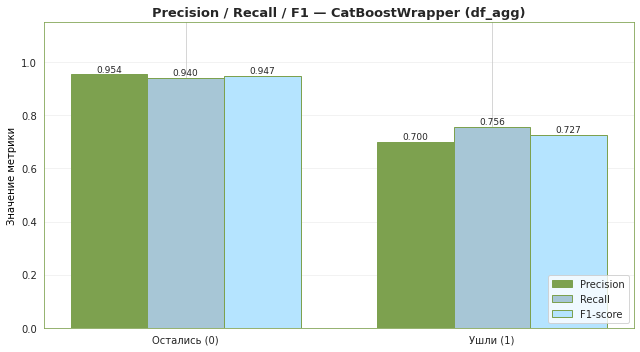

In [69]:
# 1.Precision / Recall / F1
show_precision_recall_f1(search_agg, X_agg_test, y_agg_test, dataset_name='df_agg')

МАТРИЦА ОШИБОК - df_agg
  TN = 1397 - верно определены оставшиеся
  FP =   89 - ошибочно предсказан уход
  FN =   67 - пропущен уход
  TP =  208 - верно определены ушедшие
----------------------------------------------------------------------
  Всего в тесте: 1761


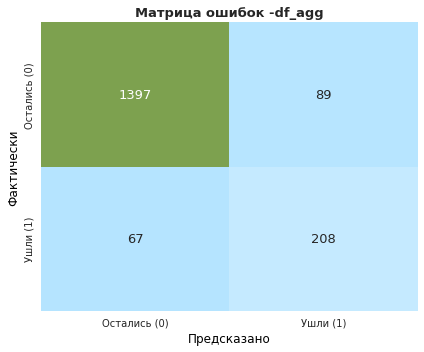

In [70]:
# 2.Матрица ошибок
cm_agg = show_confusion_matrix(search_agg, X_agg_test, y_agg_test, dataset_name='df_agg')

ТОП-15 ВАЖНЕЙШИХ ПРИЗНАКОВ - CatBoostWrapper (df_agg)
          feature  importance
      tenure_days   55.478398
  monthly_charges   12.419305
    total_charges   11.248995
             type    4.944268
     num_services    4.496920
   payment_method    3.878375
 charges_dynamics    3.172526
          partner    1.872832
paperless_billing    0.863496
       dependents    0.812985
   senior_citizen    0.811901


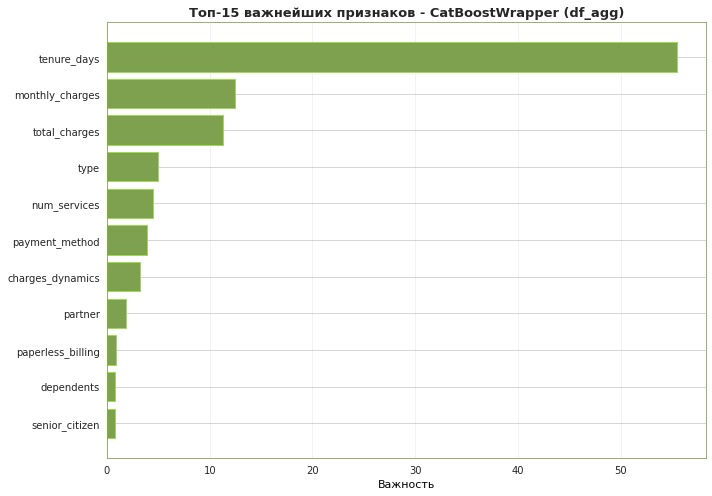

In [71]:
# 3.Важность признаков
importance_agg = show_importance(search_agg, X_agg_test, y_agg_test,dataset_name='df_agg', top_n=15)

<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">К О М М Е Н Т А Р И Й
    
---
    
- **Метрики.** ROC-AUC (CV)= 0.9134,ROC-AUC (test) = 0.9300, Accuracy =0.9114.

- Модель ловит 76% уходящих - на 3 п.п. больше, чем df_full.

**Топ-5 признаков:** 
    
- `tenure_days` (55.48%)
- `monthly_charges` (12.42%)
- `total_charges` (11.25%)
- `type` (4.94%)
- `num_services` (4.50%)
    
Числовые — 84% важности.

 <div style="border-left: 6px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
### <span style="color:#A7C6D6"> Анализ ошибок по сегментам

- FN / FP по type
- FN / FP по payment_method
- FN / FP по tenure_bin
- Комментарий — «где модель ошибается»

In [72]:
def analyze_errors_by_segment(search, X_test, y_test, segment_series,segment_name='segment', dataset_name='df_agg',
                              threshold=0.5, min_count=20):
    """Разбивает тест по сегментам и считает TP/FP/FN/TN, Recall, Precision."""
    best_model = search.best_estimator_
    y_proba = best_model.predict_proba(X_test)[:, 1]
    y_pred = (y_proba>threshold).astype(int)

    df_seg = pd.DataFrame({
                            'segment': segment_series.values,
                            'y_true': y_test.values,
                            'y_pred': y_pred,
                           })

    print("=" * 80)
    print(f"АНАЛИЗ ОШИБОК ПО '{segment_name}' — {dataset_name} (порог {threshold})")
    print("=" * 80)
    print(f"{'Сегмент':<15} {'Всего':<8} {'Ушли':<7} {'TP':<6} {'FP':<6} {'FN':<6} {'TN':<6} {'Recall':<8} {'Precision':<10}")
    print("-" * 80)

    for seg, group in df_seg.groupby('segment', observed=True):
        if len(group) < min_count:
            continue
        tn, fp, fn, tp = confusion_matrix(group['y_true'], group['y_pred']).ravel()
        recall_seg    = recall_score(group['y_true'], group['y_pred'], pos_label=1, zero_division=0)
        precision_seg = precision_score(group['y_true'], group['y_pred'], pos_label=1, zero_division=0)
        print(f"{str(seg):<15} {len(group):<8} {group['y_true'].sum():<7} "
              f"{tp:<6} {fp:<6} {fn:<6} {tn:<6} "
              f"{recall_seg:<8.3f} {precision_seg:<10.3f}")
    print("-" * 80)

In [73]:
# 5.4.1 FN / FP по type
err_type_agg = analyze_errors_by_segment(search=search_agg,X_test=X_agg_test, y_test=y_agg_test, 
                                         segment_series=X_agg_test['type'],segment_name='type', dataset_name='df_agg')

АНАЛИЗ ОШИБОК ПО 'type' — df_agg (порог 0.5)
Сегмент         Всего    Ушли    TP     FP     FN     TN     Recall   Precision 
--------------------------------------------------------------------------------
Month-to-month  967      97      65     32     32     838    0.670    0.670     
One year        377      78      58     30     20     269    0.744    0.659     
Two year        417      100     85     27     15     290    0.850    0.759     
--------------------------------------------------------------------------------


In [74]:
# 5.4.2 FN / FP по payment_method
err_pay_agg = analyze_errors_by_segment(search=search_agg, X_test=X_agg_test, y_test=y_agg_test,
                                        segment_series=X_agg_test['payment_method'],segment_name='payment_method', 
                                        dataset_name='df_agg')

АНАЛИЗ ОШИБОК ПО 'payment_method' — df_agg (порог 0.5)
Сегмент         Всего    Ушли    TP     FP     FN     TN     Recall   Precision 
--------------------------------------------------------------------------------
Bank transfer (automatic) 386      83      64     27     19     276    0.771    0.703     
Credit card (automatic) 398      77      64     23     13     298    0.831    0.736     
Electronic check 571      82      62     30     20     459    0.756    0.674     
Mailed check    406      33      18     9      15     364    0.545    0.667     
--------------------------------------------------------------------------------


In [75]:
# 5.4.3 FN / FP по tenure_bin
tenure_bin_test_agg = pd.cut( X_agg_test['tenure_days'],
                             bins=[0, 365, 730, 1095, 1460, 1825, 3000],
                             labels=['0–1 год', '1–2 года', '2–3 года', '3–4 года', '4–5 лет', '5+ лет'],
                             include_lowest=True)

err_tenure_agg = analyze_errors_by_segment(search_agg, X_agg_test, y_agg_test,segment_series=tenure_bin_test_agg,
                                           segment_name='tenure_bin', dataset_name='df_agg')



АНАЛИЗ ОШИБОК ПО 'tenure_bin' — df_agg (порог 0.5)
Сегмент         Всего    Ушли    TP     FP     FN     TN     Recall   Precision 
--------------------------------------------------------------------------------
0–1 год         560      34      23     9      11     517    0.676    0.719     
1–2 года        288      53      39     18     14     217    0.736    0.684     
2–3 года        266      74      62     22     12     170    0.838    0.738     
3–4 года        186      63      53     16     10     107    0.841    0.768     
4–5 лет         194      42      29     24     13     128    0.690    0.547     
5+ лет          267      9       2      0      7      258    0.222    1.000     
--------------------------------------------------------------------------------


<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">К О М М Е Н Т А Р И Й
    
---
    
    
ГДЕ МОДЕЛЬ ОШИБАЕТСЯ    
    
    
---    
    
**По type (df_agg).**

| Сегмент | Всего | Ушли | TP | FP | FN | TN | Recall | Precision |
|---|---|---|---|---|---|---|---|---|
| Month-to-month | 967 | 97 | 65 | 32 | 32 | 838 | 0.670 | 0.670 |
| One year | 377 | 78 | 58 | 30 | 20 | 269 | 0.744 | 0.659 |
| Two year | 417 | 100 | 85 | 27 | 15 | 290 | **0.850** | **0.759** |

- Лучше всего - `Two year` (Recall 0.850). Хуже - `Month-to-month` (0.670, 32 FN).

---
    
**По payment_method (df_agg).**

| Сегмент | Всего | Ушли | TP | FP | FN | TN | Recall | Precision |
|---|---|---|---|---|---|---|---|---|
| Bank transfer (automatic) | 386 | 83 | 64 | 27 | 19 | 276 | 0.771 | 0.703 |
| Credit card (automatic) | 398 | 77 | 64 | 23 | 13 | 298 | **0.831** | 0.736 |
| Electronic check | 571 | 82 | 62 | 30 | 20 | 459 | 0.756 | 0.674 |
| Mailed check | 406 | 33 | 18 | 9 | 15 | 364 | **0.545** | 0.667 |

- Лучше всего - автоплатежи. Хуже - `Mailed check` (Recall 0.545).
    
---    

**По tenure_bin (df_agg).**

| Сегмент | Всего | Ушли | TP | FP | FN | TN | Recall | Precision |
|---|---|---|---|---|---|---|---|---|
| 0–1 год | 560 | 34 | 23 | 9 | 11 | 517 | 0.676 | 0.719 |
| 1–2 года | 288 | 53 | 39 | 18 | 14 | 217 | 0.736 | 0.684 |
| 2–3 года | 266 | 74 | 62 | 22 | 12 | 170 | **0.838** | 0.738 |
| 3–4 года | 186 | 63 | 53 | 16 | 10 | 107 | **0.841** | 0.768 |
| 4–5 лет | 194 | 42 | 29 | 24 | 13 | 128 | 0.690 | 0.547 |
| 5+ лет | 267 | 9 | 2 | 0 | 7 | 258 | **0.222** | 1.000 |

- Recall максимален в **2-4 года**. Провал - на **5+ лет** (0.222) и **4-5 лет** (0.690, Precision 0.547).

---
    
СЛЕПЫЕ ЗОНЫ    
    
- `Month-to-month`: 32 FN, Recall 0.670.
- `Mailed check`: Recall 0.545.
- `5+ лет`: Recall 0.222.
- `4–5 лет`: Recall 0.690, Precision 0.547.

 <div style="border-left: 6px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
### <span style="color:#A7C6D6">Сравнение порогов

- Таблица: порог × Precision / Recall / F1 / FP / FN
- График: порог vs Recall / Precision / F1
- Комментарий — оптимальный порог

In [76]:
show_thresholds(search_agg, X_agg_test, y_agg_test, dataset_name='df_agg')

СРАВНЕНИЕ ПОРОГОВ — df_agg
Порог    Precision   Recall    F1        FP     FN    
-------------------------------------------------------------------------------------
0.5      0.7003      0.7564    0.7273    89     67    
0.45     0.6625      0.7709    0.7126    108    63    
0.4      0.6096      0.7891    0.6878    139    58    
0.35     0.5718      0.7964    0.6657    164    56    
0.3      0.5304      0.8255    0.6458    201    48    
0.25     0.4906      0.8545    0.6233    244    40    
0.2      0.4547      0.8764    0.5988    289    34    


<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">К О М М Е Н Т А Р И Й
    
---
    
ОПТИМАЛЬНЫЙ ПОРОГ    
    
    
**При снижении порога:**
    
- **Recall растёт** - ловим больше уходящих.
- **Precision падает** - больше ложных срабатываний.
- **F1** максимален при 0.5, при снижении - падает.

ВЫБОР ПОРОГА
    
- **0.5** - баланс Precision и Recall (F1 максимален).
- **0.3-0.4** - компромисс: Recall выше, Precision ниже.
- **0.2** - максимальный Recall, но Precision падает сильно.

Для задачи удержания **Recall важнее Precision**: пропустить уходящего дороже, чем лишний раз позвонить. Рекомендуется **порог 0.3–0.4**.

 <div style="border-left: 6px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
### <span style="color:#A7C6D6">Исследование признака `tenure_days`

- График зависимости входного и целевого признаков.

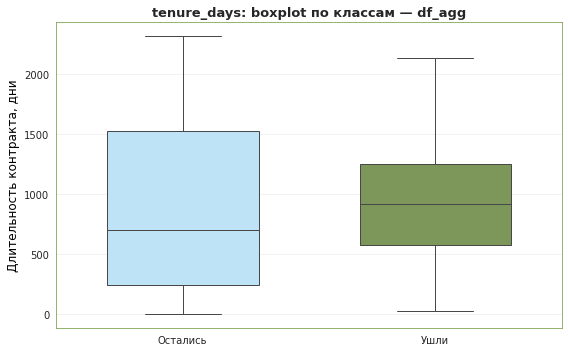

СТАТИСТИКА tenure_days ПО КЛАССАМ — df_agg
Класс             n    Среднее    Медиана        Std     Мин    Макс
----------------------------------------------------------------------
Остались       5942      893.7      702.0      717.0       0    2314
Ушли           1101      924.9      915.0      458.8      28    2129
----------------------------------------------------------------------
Разница (Ушли − Остались): +31.2 дней (+3.5%)

КВАРТИЛИ ПО КЛАССАМ:
Класс          Q1 (25%)   Q2 (50%)   Q3 (75%)        IQR
----------------------------------------------------------------------
Остались            245        702       1523       1278
Ушли                577        915       1249        672


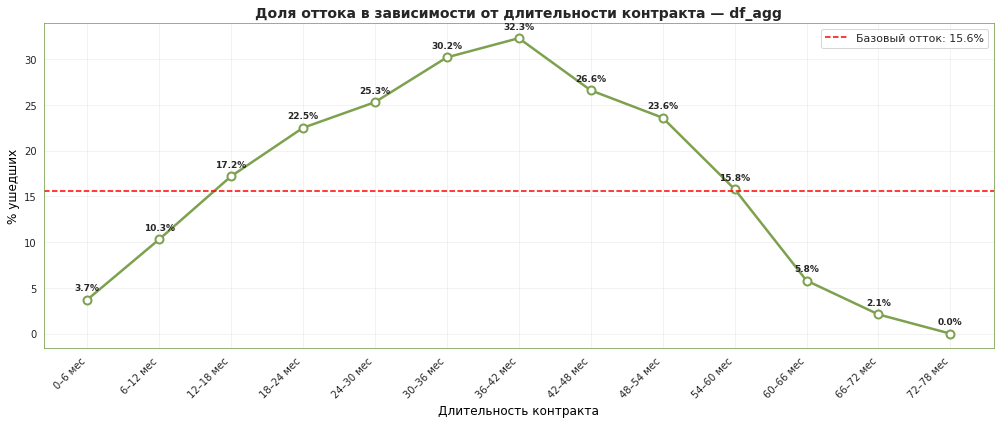

ОТТОК ПО ДЛИТЕЛЬНОСТИ — df_agg (весь датасет)
            всего  ушло  отток_pct
tenure_bin                        
0–6 мес      1218    45        3.7
6–12 мес      857    88       10.3
12–18 мес     708   122       17.2
18–24 мес     596   134       22.5
24–30 мес     558   141       25.3
30–36 мес     523   158       30.2
36–42 мес     430   139       32.3
42–48 мес     387   103       26.6
48–54 мес     407    96       23.6
54–60 мес     310    49       15.8
60–66 мес     327    19        5.8
66–72 мес     336     7        2.1
72–78 мес     386     0        0.0
-------------------------------------------------------
ИТОГО           7043     1101     15.6      


In [77]:
# Boxplot: сравнение tenure_days у классов
fig, ax = plt.subplots(figsize=(8, 5))
data_plot = pd.DataFrame({
                           'Длительность, дни': df_agg['tenure_days'],
                            'Класс':              df_agg['churn'].map({0: 'Остались', 1: 'Ушли'}),
                         })
sns.boxplot(data=data_plot, x='Класс', y='Длительность, дни', ax=ax,
            hue='Класс', palette={'Остались': COLORS['blue'], 'Ушли': COLORS['green_dark']}, legend=False, width=0.6)
ax.set_xlabel('')
ax.set_ylabel('Длительность контракта, дни', fontsize=12)
ax.set_title('tenure_days: boxplot по классам — df_agg',
             fontsize=13, fontweight='bold')
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

# Статистика tenure_days по классам
print("=" * 70)
print("СТАТИСТИКА tenure_days ПО КЛАССАМ — df_agg")
print("=" * 70)
print(f"{'Класс':<12} {'n':>6} {'Среднее':>10} {'Медиана':>10} {'Std':>10} {'Мин':>7} {'Макс':>7}")
print("-" * 70)

for churn_val, label in [(0, 'Остались'), (1, 'Ушли')]:
    subset = df_agg[df_agg['churn'] == churn_val]['tenure_days']
    print(f"{label:<12} {len(subset):>6} {subset.mean():>10.1f} {subset.median():>10.1f} "
          f"{subset.std():>10.1f} {subset.min():>7.0f} {subset.max():>7.0f}")

print("-" * 70)

# Разница между классами
mean_0 = df_agg[df_agg['churn'] == 0]['tenure_days'].mean()
mean_1 = df_agg[df_agg['churn'] == 1]['tenure_days'].mean()
diff = mean_1 - mean_0
print(f"Разница (Ушли − Остались): {diff:+.1f} дней ({diff / mean_0 * 100:+.1f}%)")
print("=" * 70)

# Квартили по классам
print("\nКВАРТИЛИ ПО КЛАССАМ:")
print("=" * 70)
print(f"{'Класс':<12} {'Q1 (25%)':>10} {'Q2 (50%)':>10} {'Q3 (75%)':>10} {'IQR':>10}")
print("-" * 70)
for churn_val, label in [(0, 'Остались'), (1, 'Ушли')]:
    subset = df_agg[df_agg['churn'] == churn_val]['tenure_days']
    q1, q2, q3 = subset.quantile([0.25, 0.5, 0.75])
    print(f"{label:<12} {q1:>10.0f} {q2:>10.0f} {q3:>10.0f} {q3 - q1:>10.0f}")
print("=" * 70)

# Отток по бинам tenure_days
df_agg_churn = df_agg.copy()
df_agg_churn['tenure_bin'] = pd.cut( df_agg_churn['tenure_days'], bins=np.arange(0, df_agg_churn['tenure_days'].max() + 180, 180),
    labels=[f'{int(b/30)}–{int((b+180)/30)} мес'
            for b in np.arange(0, df_agg_churn['tenure_days'].max() + 180, 180)[:-1]], include_lowest=True)

churn_rate = (df_agg_churn.groupby('tenure_bin', observed=True)
              .agg(всего=('churn', 'count'),
                   ушло=('churn', 'sum'),
                   отток=('churn', 'mean'))
              .assign(отток_pct=lambda d: (d['отток'] * 100).round(1)))
churn_rate = churn_rate[churn_rate['всего'] >= 20]

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(range(len(churn_rate)), churn_rate['отток_pct'],
        marker='o', linewidth=2.5, markersize=8,
        color=COLORS['green_dark'], markerfacecolor='white',
        markeredgewidth=2, markeredgecolor=COLORS['green_dark'])
for i, v in enumerate(churn_rate['отток_pct']):
    ax.text(i, v + 1, f'{v:.1f}%', ha='center', fontsize=9, fontweight='bold')
ax.axhline(df_agg_churn['churn'].mean() * 100, color='red', linestyle='--',
           linewidth=1.5,
           label=f'Базовый отток: {df_agg_churn["churn"].mean()*100:.1f}%')
ax.set_xticks(range(len(churn_rate)))
ax.set_xticklabels(churn_rate.index, rotation=45, ha='right', fontsize=10)
ax.set_xlabel('Длительность контракта', fontsize=12)
ax.set_ylabel('% ушедших', fontsize=12)
ax.set_title('Доля оттока в зависимости от длительности контракта — df_agg',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Сводка
print("=" * 55)
print("ОТТОК ПО ДЛИТЕЛЬНОСТИ — df_agg (весь датасет)")
print("=" * 55)
print(churn_rate[['всего', 'ушло', 'отток_pct']].to_string())
print("-" * 55)
print(f"{'ИТОГО':<15} {churn_rate['всего'].sum():<8} "
      f"{churn_rate['ушло'].sum():<8} "
      f"{churn_rate['ушло'].sum()/churn_rate['всего'].sum()*100:<10.1f}")

<div style="background-color: white; border: 1px solid #B5E4FF; border-radius: 23px; padding: 15px 25px; display: inline-block; color: black;">

<span style="color:#7DA14F">К О М М Е Н Т А Р И Й
    
---

**По boxplot и бинам.**

- **Остались** - медиана ~ 700 дней (~2 года), разброс широкий: от 0 до ~2400 дней. Есть и новички, и «долгожители».
- **Ушли** - ~ 900 дней (~2.5 года), разброс **уже**: от ~30 до ~2100 дней.

ВИДИМ
    
- Ушедшие концентрируются в **среднем сроке** (1–4 года). Они **реже бывают новичками** (0–6 мес) и **реже доживают до 5+ лет**. Именно средний срок - критическая зона оттока.

- **По бинам.** Отток растёт с 3.7% (0–6 мес) до пика **32.3% на 36-42 мес**, затем падает. Критическое окно - **30-42 мес**. После 60 мес отток резко снижается - клиенты «привыкают».

 <div style="border-left: 6px solid #B5E4FF; padding-left: 15px; margin: 15px 0;"> 
    
### <span style="color:#A7C6D6">Итоговая рекомендация

| Параметр | Значение |
|---|---|
| **Модель** | CatBoostWrapper на df_agg |
| **Признаков** | 11 |
| **Гиперпараметры** | depth=3, iterations=1500, lr=0.2 |
| **Порог** | 0.3–0.4 |
| **ROC-AUC (test)** | 0.9300 |
| **Recall (1)** | 0.76 при 0.5 - ~0.79 при 0.4 - ~0.83 при 0.3 |
| **Precision (1)** | 0.70 при 0.5 - ~0.61 при 0.4 - ~0.53 при 0.3 |

**Кого удерживать в первую очередь:**
    
1. Q4-клиенты (топ-25% по среднему чеку) - 25% базы, 49.1% выручки. Отток 25.7%.
2. `stable` + Q4 - 29.5% оттока.
3. 1-4 года + One year / Two year + автоплатёж - критическое окно.
4. `Month-to-month` — 32 FN.

**Что мониторить:**
    
- Реальный отклик на удержание.
- Recall и Precision по сегментам ежемесячно.
    
    
---
    
БИЗНЕС-ЦЕННОСТЬ

1. **Инструмент раннего предупреждения.** Модель ловит ~76–83% уходящих в зависимости от порога.
2. **Фокус удержания.** Удержание направлено клиентам в зоне риска, а не всем подряд.
3. **Понятные драйверы.** Топ-признаки (`tenure_days`, `monthly_charges`, `total_charges`, `type`, `num_services`) дают бизнесу конкретные паттерны:
    
                       - `tenure_days` - критическое окно 1–4 года.
                       - `monthly_charges` - дорогие клиенты уходят чаще.
                       - `type` - долгосрочные контракты в зоне риска.
                       - `num_services` - 7 услуг = пик оттока.
    
4. **Готовность к масштабированию.** Модель на 11 признаках - быстро обучается, легко интерпретируется, не требует сложного препроцессинга.
5. **Ограничение.** Точный экономический эффект в рамках проекта не оценивается: нет данных о LTV, стоимости удержания и конверсии. Это предмет отдельного исследования.

<div style="background-color: white; border: 3px solid #7DA14F; border-radius: 10px; padding: 15px 25px; display: inline-block; color: black;">

## <span style="color:#9EDB4F">Общий вывод

---

<span style="color:#A7C6D6">**СДЕЛАНО**

**1. Загрузка и предобработка.**
    
- Подключились к SQLite, загрузили 4 таблицы (`contract`, `personal`, `internet`, `phone`), привели столбцы к `snake_case`, объединили через `left join` от `contract`.
- Заполнили 11 пропусков в `total_charges`, обработали отсутствие услуг отдельными категориями `No internet service` / `No phone service`.
- Итог: 7043 клиента × 21 признак, пропусков нет, целевая `churn` - 15.6%.

**2. EDA и генерация признаков.**
    
- Создали `tenure_days` (длительность в днях), `avg_monthly` (средний чек), `charges_dynamics` (динамика тарифа), `num_services` (число услуг), `is_q4` (топ-25% по чеку).
- Провели корреляционный анализ (Phik) - сильнейшие предикторы: `tenure_days` (0.3746), `total_charges` (0.3043), `num_services` (0.2114).

**3. Подготовка данных.**
    
- Собрали два датасета: `df_full` (18 признаков - все услуги отдельно) и `df_agg` (11 признаков - только `num_services`).
- Стратифицированное разделение 75/25, дисбаланс 1:5.4 - борется весами классов.

**4. Обучение моделей.**
    
- **8 моделей:** 2 датасета × 4 класса (Dummy, RandomForest, CatBoost, Keras MLP).
- GridSearchCV: **20 комбинаций × 5 фолдов = 100 обучений** на каждый датасет.
- Победитель на обоих датасетах - **CatBoostWrapper** (по метрике ROC-AUC на CV).
- **Проверка адекватности:** Dummy (константа) даёт ROC-AUC = 0.5000 и Recall = 0.0000. Разрыв с CatBoost = **+41.4 п.п. ROC-AUC** и **+71.3 п.п. Recall** - модель различает классы, а не угадывает.

**5. Оценка и анализ.**
    
- **Тестирование - один раз, только для победителя:** `CatBoostWrapper` на `df_agg`.
- Финальная модель: ROC-AUC (test) = **0.9300**, Accuracy = **0.9114**, Recall (1) = **0.7564**, F1 = **0.7273**.
- Матрица ошибок: TN=1397, FP=89, FN=67, TP=208.
- Проанализировали важность признаков, ошибки по сегментам, «слепые зоны» и сравнили пороги.

---

<span style="color:#A7C6D6">**КЛЮЧЕВЫЕ ВЫВОДЫ**

- **Критическое окно оттока - 1–4 года.** Пик: **30–42 мес (30.2–32.3%)**. После 60 мес отток падает почти до нуля.
- **Топ-25% по чеку (Q4)** - 25% базы, но **49.1% выручки**. Их отток **25.7%** - в 1.6 раза выше базового.
- **Самая опасная группа - `stable` + Q4:** 29.5% оттока. Дорогие клиенты, которым не предлагают обновления тарифа.
- **Главный предиктор - `tenure_days`** (55.48% важности). Числовые признаки дают 84% важности модели.
- **«Слепые зоны»** - `Month-to-month` (Recall 0.670, 32 FN), `Mailed check` (Recall 0.545), клиенты со стажем 5+ лет (Recall 0.222).
- **Отдельные услуги не нужны.** `df_agg` (11 признаков) не хуже `df_full` (18): ROC-AUC в пределах погрешности, лучший Recall (+2.8 п.п.), проще интерпретация.

---

<span style="color:#A7C6D6">**БИЗНЕС-ЦЕННОСТЬ**

Модель - **инструмент раннего предупреждения**:

- Ловит **~76–83% уходящих** в зависимости от порога.
- Позволяет **фокусировать удержание** на зоне риска, а не тратить бюджет на всех подряд.
- **Приоритетные сегменты:** Q4, `stable + Q4`, 1–4 года + One/Two year + автоплатёж, `Month-to-month`.
- **Понятные драйверы:** `tenure_days` (критическое окно 1–4 года), `monthly_charges` (дорогие уходят чаще), `type` (долгосрочные контракты в зоне риска), `num_services` (7 услуг = пик оттока).

---

<span style="color:#A7C6D6">**ОГРАНИЧЕНИЕ**

Точный экономический эффект в рамках проекта не оценивается - нет данных о LTV, стоимости удержания и конверсии. Это предмет отдельного исследования.